# **1. DATA LOADING**

It involved loading the 4 datasets to be used which are;
1. community_scam_reports-this was created.
2. fake_job_postings.
3. phishing_URL_Dataset.
4. SMSSpamCollection.

In [71]:

# 1. CORE DATA AND OS LIBRARIES
import os
import json
import re
from pathlib import Path
from urllib.parse import urlsplit

import pandas as pd
import numpy as np
import scipy.sparse as sp


# 2. VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns

# 3. SCIKIT-LEARN PREPROCESSING AND PIPELINES

import sklearn

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer


# 4. MODEL SELECTION AND TRAINING

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    cross_val_score
)

# 5. MACHINE LEARNING MODELS

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)


# 6. EVALUATION METRICS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# 7. MODEL SAVING AND LOADING
import joblib


# 8. WARNING MANAGEMENT
import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully.")
print("Scikit-learn version:", sklearn.__version__)


All required libraries imported successfully.
Scikit-learn version: 1.9.1


In [2]:
# Loading the Phishing dataset
df_phishing = pd.read_csv('../../Data/Phishing_Dataset.csv')

df_phishing.head()

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


In [3]:
df_phishing.shape

(101219, 18)

In [4]:
df_phishing.describe()

,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
count,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101219.000000,101218.000000
mean,35.060996,0.484879,3.007775,0.405645,3.976112,6.885733,1.511515,1.010591,5.003270,8.538249,0.042897,8.508669,0.328288,0.146613,6.292218,24.136487,0.370883
std,16.805678,0.499774,0.946612,0.491019,0.307068,1.670271,0.624755,0.202794,2.917429,14.701750,0.202626,8.540811,0.469593,0.353721,5.342714,22.490260,0.483043
min,7.000000,0.000000,0.000000,0.000000,2.521641,1.000000,-1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,2.000000,0.000000,3.770942,5.000000,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,31.000000,0.000000,3.000000,0.000000,3.937193,7.000000,2.000000,1.000000,3.000000,2.000000,0.000000,10.000000,0.000000,0.000000,3.000000,19.642857,0.000000
75%,35.000000,1.000000,4.000000,1.000000,4.100817,8.000000,2.000000,1.000000,8.000000,7.000000,0.000000,15.000000,1.000000,0.000000,10.000000,47.058824,1.000000
max,474.000000,1.000000,19.000000,1.000000,5.871503,48.000000,5.000000,14.000000,10.000000,317.000000,1.000000,164.000000,1.000000,1.000000,36.000000,65.957447,1.000000


In [5]:
df_phishing.info()

<class 'pandas.DataFrame'>
RangeIndex: 101219 entries, 0 to 101218
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   URL                        101219 non-null  str    
 1   url_length                 101219 non-null  int64  
 2   has_ip_address             101219 non-null  int64  
 3   dot_count                  101219 non-null  int64  
 4   https_flag                 101219 non-null  int64  
 5   url_entropy                101219 non-null  float64
 6   token_count                101219 non-null  int64  
 7   subdomain_count            101219 non-null  int64  
 8   query_param_count          101219 non-null  int64  
 9   tld_length                 101219 non-null  int64  
 10  path_length                101219 non-null  int64  
 11  has_hyphen_in_domain       101219 non-null  int64  
 12  number_of_digits           101219 non-null  int64  
 13  tld_popularity             101219 non-nu

In [6]:
df_phishing.isnull().sum()

URL                          0
url_length                   0
has_ip_address               0
dot_count                    0
https_flag                   0
url_entropy                  0
token_count                  0
subdomain_count              0
query_param_count            0
tld_length                   0
path_length                  0
has_hyphen_in_domain         0
number_of_digits             0
tld_popularity               0
suspicious_file_extension    0
domain_name_length           0
percentage_numeric_chars     0
ClassLabel                   1
dtype: int64

There are no missing values.

In [7]:
# Loading the fake job postings dataset
df_fake_jobs = pd.read_csv('../../Data/fake_job_postings.csv')

df_fake_jobs.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [8]:
df_fake_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [9]:
df_fake_jobs.shape

(17880, 18)

In [10]:
df_fake_jobs.isnull().sum()

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

In [11]:
# Loading the SMS Spam Collection dataset
df_sms = pd.read_csv(
    '../../Data/SMSSpamCollection',
    sep='\t',
    header=None,
    names=['label', 'message'],
    encoding='utf-8'
)
df_sms.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [12]:
df_sms.shape

(5572, 2)

In [13]:
df_sms.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


In [14]:
df_sms.isnull().sum()

label      0
message    0
dtype: int64

In [15]:
df_sms.describe()

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [16]:
# DEFINING THE DATA FOLDER
# Adjusting this path if your notebook is in a different directory.
data_folder = Path("../../Data")
data_folder.mkdir(parents=True, exist_ok=True)


# CREATING SYNTHETIC COMMUNITY SCAM REPORTS
# The records are for testing only,they do not represent real people, phone numbers, or businesses.

community_reports = [
    {
        "report_id": "CSR001",
        "report_date": "2026-10-01",
        "report_type": "Phishing",
        "platform": "SMS",
        "suspicious_url": "http://login.example.com",
        "phone_number": "SYNTHETIC_PHONE_001",
        "seller_id": None,
        "description": "Message requests account login details through a suspicious link.",
        "evidence_notes": "Synthetic example of a request for account credentials.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR002",
        "report_date": "2026-10-02",
        "report_type": "Fake Job",
        "platform": "WhatsApp",
        "suspicious_url": "http://jobs.example.org",
        "phone_number": "SYNTHETIC_PHONE_002",
        "seller_id": None,
        "description": "Recruiter requests an upfront registration fee.",
        "evidence_notes": "Synthetic example of an upfront employment fee request.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR003",
        "report_date": "2026-10-03",
        "report_type": "Fake Online Shop",
        "platform": "TikTok",
        "suspicious_url": "http://shop.example.net",
        "phone_number": "SYNTHETIC_PHONE_003",
        "seller_id": "SELLER_SYN_001",
        "description": "Seller requests full payment before delivery and stops responding.",
        "evidence_notes": "Synthetic example of alleged non-delivery after payment.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR004",
        "report_date": "2026-10-04",
        "report_type": "Mobile Money Scam",
        "platform": "SMS",
        "suspicious_url": None,
        "phone_number": "SYNTHETIC_PHONE_004",
        "seller_id": None,
        "description": "Message claims a prize was won and requests payment to release it.",
        "evidence_notes": "Synthetic example of an advance-fee prize message.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR005",
        "report_date": "2026-10-05",
        "report_type": "Impersonation",
        "platform": "WhatsApp",
        "suspicious_url": None,
        "phone_number": "SYNTHETIC_PHONE_005",
        "seller_id": None,
        "description": "Account pretends to represent a trusted organization and requests personal details.",
        "evidence_notes": "Synthetic example of possible organizational impersonation.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR006",
        "report_date": "2026-10-06",
        "report_type": "Phishing",
        "platform": "Email",
        "suspicious_url": "http://login.example.com",
        "phone_number": None,
        "seller_id": None,
        "description": "Another report identifies the same synthetic login link.",
        "evidence_notes": "Synthetic repeat report for testing URL matching.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR007",
        "report_date": "2026-10-07",
        "report_type": "Fake Online Shop",
        "platform": "TikTok",
        "suspicious_url": "http://shop.example.net",
        "phone_number": "SYNTHETIC_PHONE_003",
        "seller_id": "SELLER_SYN_001",
        "description": "Repeated report about the same synthetic shop and contact identifier.",
        "evidence_notes": "Synthetic repeat report for testing seller and phone matching.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR008",
        "report_date": "2026-10-08",
        "report_type": "Legitimate",
        "platform": "Website",
        "suspicious_url": "https://www.example.com",
        "phone_number": None,
        "seller_id": "SELLER_SYN_002",
        "description": "Synthetic example of a routine website with no known suspicious indicators.",
        "evidence_notes": "Synthetic legitimate test case; not independently verified.",
        "verification_status": "Unverified",
        "is_suspicious": 0
    },
    {
        "report_id": "CSR009",
        "report_date": "2026-10-09",
        "report_type": "Legitimate",
        "platform": "SMS",
        "suspicious_url": None,
        "phone_number": "SYNTHETIC_PHONE_006",
        "seller_id": None,
        "description": "Synthetic example of a routine delivery notification without a payment request.",
        "evidence_notes": "Synthetic legitimate message example for testing.",
        "verification_status": "Unverified",
        "is_suspicious": 0
    },
    {
        "report_id": "CSR010",
        "report_date": "2026-10-10",
        "report_type": "Fake Job",
        "platform": "Website",
        "suspicious_url": "http://jobs.example.org",
        "phone_number": "SYNTHETIC_PHONE_002",
        "seller_id": None,
        "description": "Repeated report about a job offer requiring payment before employment.",
        "evidence_notes": "Synthetic repeat report for testing URL and phone matching.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    }
]


# CONVERTING RECORDS INTO A DATAFRAME
df_community = pd.DataFrame(community_reports)


# 5. CLEANING AND STANDARDIZING THE DATA
# Convert report dates to datetime.
df_community["report_date"] = pd.to_datetime(
    df_community["report_date"],
    errors="coerce"
)

# Standardizing text fields.
text_columns = [
    "report_id",
    "report_type",
    "platform",
    "suspicious_url",
    "phone_number",
    "seller_id",
    "description",
    "evidence_notes",
    "verification_status"
]

for column in text_columns:
    df_community[column] = df_community[column].apply(
        lambda value: (
            value.strip() if isinstance(value, str) else value
        )
    )

# Seting source explicitly so synthetic examples are not confused, with reports submitted by real users.
df_community["report_source"] = "Synthetic Test Data"

# Adding a last-updated date.
df_community["last_updated"] = pd.Timestamp.today().normalize()


# VALIDATING THE DATA
assert df_community["report_id"].notna().all(), (
    "Report IDs cannot be missing."
)

assert df_community["report_id"].is_unique, (
    "Duplicate report IDs found."
)

assert df_community["report_date"].notna().all(), (
    "Invalid or missing report dates found."
)

assert df_community["is_suspicious"].isin([0, 1]).all(), (
    "is_suspicious must contain only 0 or 1."
)

# Reporting categories should agree with the example labels.
assert (
    (
        df_community["report_type"] == "Legitimate"
    ) == (
        df_community["is_suspicious"] == 0
    )
).all(), "Check report_type and is_suspicious for inconsistent labels."


# SAVING THE CLEANED COMMUNITY REPORTS DATASET
reports_path = data_folder / "community_scam_reports.csv"

df_community.to_csv(
    reports_path,
    index=False,
    na_rep=""
)

print("Community reports dataset created successfully!")
print("Saved to:", reports_path.resolve())
print("Dataset shape:", df_community.shape)


# 8. IDENTIFYING REPEATED INDICATORS
# Counting unique report IDs for each URL, phone number and seller ID.
indicator_columns = [
    "suspicious_url",
    "phone_number",
    "seller_id"
]

indicator_records = []

for column in indicator_columns:

    valid_reports = df_community.dropna(subset=[column])

    # not counting blank identifiers.
    valid_reports = valid_reports[
        valid_reports[column].astype(str).str.strip() != ""
    ]

    grouped = (
        valid_reports.groupby(column)
        .agg(
            report_count=("report_id", "nunique"),
            first_report=("report_date", "min"),
            last_report=("report_date", "max"),
            report_types=("report_type", "nunique"),
            platforms=("platform", "nunique")
        )
        .reset_index()
    )

    for _, row in grouped.iterrows():
        indicator_records.append({
            "indicator_type": column,
            "indicator_value": row[column],
            "report_count": int(row["report_count"]),
            "first_report": row["first_report"],
            "last_report": row["last_report"],
            "different_report_types": int(row["report_types"]),
            "different_platforms": int(row["platforms"]),
            "data_source": "Synthetic Test Data"
        })

df_indicators = pd.DataFrame(
    indicator_records,
    columns=[
        "indicator_type",
        "indicator_value",
        "report_count",
        "first_report",
        "last_report",
        "different_report_types",
        "different_platforms",
        "data_source"
    ]
)


# SAVING THE INDICATOR SUMMARY
summary_path = data_folder / "community_indicator_summary.csv"

df_indicators.to_csv(
    summary_path,
    index=False,
    na_rep=""
)

print("\nIndicator summary created successfully!")
print("Saved to:", summary_path.resolve())


# DISPLAYING THE REPEATED INDICATORS
df_repeated = df_indicators[
    df_indicators["report_count"] > 1
].sort_values(
    by="report_count",
    ascending=False
)

print("\nRepeated indicators (for testing only):")
display(df_repeated)


# DISPLAYING THE DATASET SUMMARY
print("\n========== DATASET SUMMARY ==========")

print("Total reports:", len(df_community))
print("Unique report IDs:", df_community["report_id"].nunique())

print("\nReports by category:")
display(df_community["report_type"].value_counts())

print("\nSuspicious versus legitimate test labels:")
display(
    df_community["is_suspicious"]
    .value_counts()
    .rename(index={
        0: "Legitimate test example",
        1: "Suspicious test example"
    })
)

print("\nMissing values:")
display(df_community.isna().sum().to_frame("missing_count"))

print("\nFirst five community reports:")
display(df_community.head())

print("\nCommunity Scam Reports processing completed.")


Community reports dataset created successfully!
Saved to: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\Data\community_scam_reports.csv
Dataset shape: (10, 13)

Indicator summary created successfully!
Saved to: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\Data\community_indicator_summary.csv

Repeated indicators (for testing only):


,indicator_type,indicator_value,report_count,first_report,last_report,different_report_types,different_platforms,data_source
0,suspicious_url,http://jobs.example.org,2,2026-10-02,2026-10-10,1,2,Synthetic Test Data
1,suspicious_url,http://login.example.com,2,2026-10-01,2026-10-06,1,2,Synthetic Test Data
2,suspicious_url,http://shop.example.net,2,2026-10-03,2026-10-07,1,1,Synthetic Test Data
5,phone_number,SYNTHETIC_PHONE_002,2,2026-10-02,2026-10-10,1,2,Synthetic Test Data
6,phone_number,SYNTHETIC_PHONE_003,2,2026-10-03,2026-10-07,1,1,Synthetic Test Data
10,seller_id,SELLER_SYN_001,2,2026-10-03,2026-10-07,1,1,Synthetic Test Data



========== DATASET SUMMARY ==========
Total reports: 10
Unique report IDs: 10

Reports by category:


report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64


Suspicious versus legitimate test labels:


...


Missing values:


,missing_count
report_id,0
report_date,0
report_type,0
platform,0
suspicious_url,3
phone_number,2
seller_id,7
description,0
evidence_notes,0
verification_status,0



First five community reports:


,report_id,report_date,report_type,platform,suspicious_url,phone_number,seller_id,description,evidence_notes,verification_status,is_suspicious,report_source,last_updated
0,CSR001,2026-10-01,Phishing,SMS,http://login.example.com,SYNTHETIC_PHONE_001,NaN,Message requests account login details through...,Synthetic example of a request for account cre...,Unverified,1,Synthetic Test Data,2026-10-27
1,CSR002,2026-10-02,Fake Job,WhatsApp,http://jobs.example.org,SYNTHETIC_PHONE_002,NaN,Recruiter requests an upfront registration fee.,Synthetic example of an upfront employment fee...,Unverified,1,Synthetic Test Data,2026-10-27
2,CSR003,2026-10-03,Fake Online Shop,TikTok,http://shop.example.net,SYNTHETIC_PHONE_003,SELLER_SYN_001,Seller requests full payment before delivery a...,Synthetic example of alleged non-delivery afte...,Unverified,1,Synthetic Test Data,2026-10-27
3,CSR004,2026-10-04,Mobile Money Scam,SMS,NaN,SYNTHETIC_PHONE_004,NaN,Message claims a prize was won and requests pa...,Synthetic example of an advance-fee prize mess...,Unverified,1,Synthetic Test Data,2026-10-27
4,CSR005,2026-10-05,Impersonation,WhatsApp,NaN,SYNTHETIC_PHONE_005,NaN,Account pretends to represent a trusted organi...,Synthetic example of possible organizational i...,Unverified,1,Synthetic Test Data,2026-10-27



Community Scam Reports processing completed.


## 📂 Community Scam Reports Dataset

The **Community Scam Reports Dataset** stores reports of suspected scams submitted by TrustShield 254 users. It helps identify recurring patterns, such as repeated phishing URLs, suspicious phone numbers, fraudulent job offers, and potentially fraudulent online sellers.

For example, multiple reports of a TikTok shop accepting M-Pesa payments without delivering goods can help flag the seller for further investigation.

**Note:** The initial dataset contains synthetic records for testing and development, not verified real-world scam reports.

# **2. DATA CLEANING**

In [17]:
# Make a copy of the fake_jobs dataset to use in cleaning
df_fake_jobs_clean = df_fake_jobs.copy()

In [18]:

# Remove duplicate rows
df_fake_jobs_clean = df_fake_jobs_clean.drop_duplicates()

# Remove rows with missing job descriptions
df_fake_jobs_clean = df_fake_jobs_clean.dropna(subset=['description'])

# Fill missing categorical values
categorical_columns = [
    'location',
    'department',
    'salary_range',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

for column in categorical_columns:
    df_fake_jobs_clean[column] = (
        df_fake_jobs_clean[column].fillna('Unknown')
    )

# Fill missing text fields
text_columns = [
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

for column in text_columns:
    df_fake_jobs_clean[column] = (
        df_fake_jobs_clean[column].fillna('')
    )

print("Cleaning completed!")
print("Original shape:", df_fake_jobs.shape)
print("Cleaned shape:", df_fake_jobs_clean.shape)


Cleaning completed!
Original shape: (17880, 18)
Cleaned shape: (17879, 18)


In [19]:
df_fake_jobs_clean.isnull().sum()

job_id                 0
title                  0
location               0
department             0
salary_range           0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64

There are no  more missing values and we can move to the next step.

# **3.EXPLORATORY DATA ANALYSIS**
Main questiosn to be answered by EDA are:
1. Phishing URL - How many legitimate and phishing URLs are there? Which URL characteristics distinguish them?

2. Fake Job Postings - How many fraudulent jobs are present? Which job categories and text fields reveal useful patterns?

3. SMS Spam Collection - What proportion of messages are spam? Which words and message lengths are common?

4. Community Scam Reports - Which scam types are reported? Are any URLs, phone identifiers or sellers repeated?


In [20]:
# Setting visualization style
sns.set_style('whitegrid')

### **1. Understanding the structure of the dataset **

In [21]:
data_path = Path('../../Data')

if 'df_phishing' not in globals():
    df_phishing = pd.read_csv(data_path / 'Phishing_URL_Dataset.csv')

if 'df_fake_jobs_clean' not in globals():
    df_fake_jobs_clean = pd.read_csv(data_path / 'fake_job_postings.csv')

if 'df_sms' not in globals():
    df_sms = pd.read_csv(
        data_path / 'SMSSpamCollection',
        sep='\t',
        header=None,
        names=['label', 'message'],
        encoding='utf-8'
    )

if 'df_community' not in globals():
    df_community = pd.read_csv(
        data_path / 'community_scam_reports.csv'
    )

# 3. Store the datasets for convenient inspection
datasets = {
    'Phishing URLs': df_phishing,
    'Fake Job Postings': df_fake_jobs_clean,
    'SMS Spam Collection': df_sms,
    'Community Scam Reports': df_community
}

# 4. Display the dimensions of each dataset
for name, df in datasets.items():
    print(f'{name}: {df.shape[0]:,} rows, {df.shape[1]} columns')


Phishing URLs: 101,219 rows, 18 columns
Fake Job Postings: 17,879 rows, 18 columns
SMS Spam Collection: 5,572 rows, 2 columns
Community Scam Reports: 10 rows, 13 columns


### **2. EDA for the Phishing URL dataset**

#### **2.1 Inspecting the columns and identify the target label**
We had to establish which column indicates whether a URL is legitimate or phishing before interpreting the class distribution.

In [22]:

# 2.1 Inspect phishing dataset columns
print("Dataset shape:", df_phishing.shape)
print("\nColumn names:")
print(df_phishing.columns.tolist())

print("\nDataset information:")
df_phishing.info()

print("\nFirst five records:")
display(df_phishing.head())


Dataset shape: (101219, 18)

Column names:
['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'ClassLabel']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 101219 entries, 0 to 101218
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   URL                        101219 non-null  str    
 1   url_length                 101219 non-null  int64  
 2   has_ip_address             101219 non-null  int64  
 3   dot_count                  101219 non-null  int64  
 4   https_flag                 101219 non-null  int64  
 5   url_entropy                101219 non-null  float64
 6   token_count                101219 non-null  int64  
 

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


#### **2.2 Examine the target distribution**
The following code checks common target-column names. It will display the class counts only when a matching column is found.

In [23]:

# 2.2 Identify the phishing target column
target_candidates = [
    'label', 'Label', 'status', 'Status',
    'result', 'Result', 'class', 'Class',
    'phishing', 'Phishing', 'is_phishing',
    'is_phishing_url', 'legitimate'
]

phishing_target = next(
    (col for col in target_candidates if col in df_phishing.columns),
    None
)

if phishing_target is not None:
    print("Target column:", phishing_target)
    print("\nClass counts:")
    print(df_phishing[phishing_target].value_counts(dropna=False))

    print("\nClass percentages:")
    print(
        (df_phishing[phishing_target].value_counts(normalize=True) * 100)
        .round(2)
    )

    df_phishing[phishing_target].value_counts().plot(
        kind='bar',
        xlabel='URL Class',
        ylabel='Number of URLs',
        title='Distribution of Phishing URL Classes',
        rot=0
    )
    plt.tight_layout()
    plt.show()
else:
    print("Target column not identified automatically.")
    print("Review the column names printed in Section 3.1.")


Target column not identified automatically.
Review the column names printed in Section 3.1.


#### **2.3 Exploring numerical URL characteristics**
This helps in understanding the numerical features available for detecting suspicious URLs.

Numerical columns: 17


,count,mean,std,min,25%,50%,75%,max
url_length,101219.0,35.060996,16.805678,7.000000,27.000000,31.000000,35.000000,474.000000
has_ip_address,101219.0,0.484879,0.499774,0.000000,0.000000,0.000000,1.000000,1.000000
dot_count,101219.0,3.007775,0.946612,0.000000,2.000000,3.000000,4.000000,19.000000
https_flag,101219.0,0.405645,0.491019,0.000000,0.000000,0.000000,1.000000,1.000000
url_entropy,101219.0,3.976112,0.307068,2.521641,3.770942,3.937193,4.100817,5.871503
token_count,101219.0,6.885733,1.670271,1.000000,5.000000,7.000000,8.000000,48.000000
subdomain_count,101219.0,1.511515,0.624755,-1.000000,1.000000,2.000000,2.000000,5.000000
query_param_count,101219.0,1.010591,0.202794,1.000000,1.000000,1.000000,1.000000,14.000000
tld_length,101219.0,5.003270,2.917429,0.000000,3.000000,3.000000,8.000000,10.000000
path_length,101219.0,8.538249,14.701750,0.000000,0.000000,2.000000,7.000000,317.000000


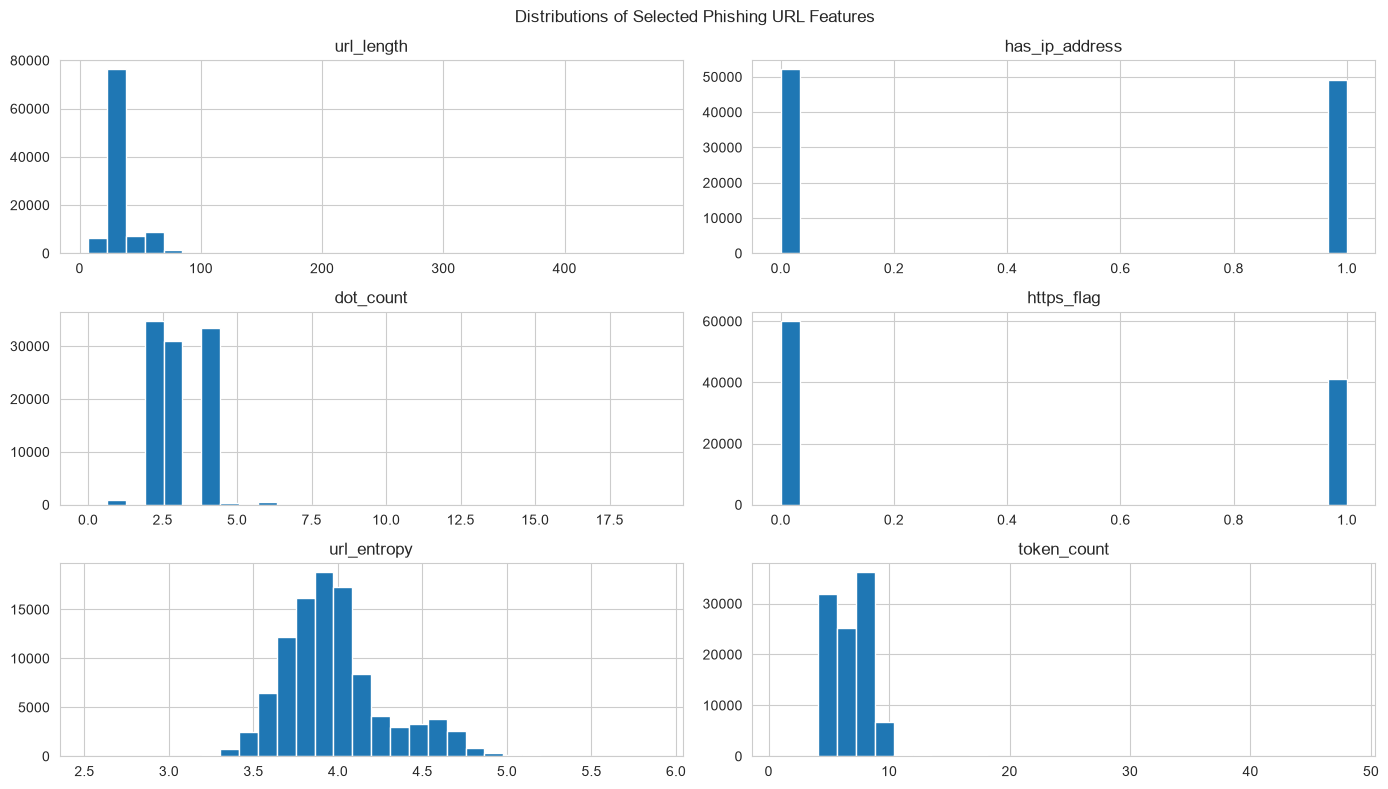

In [24]:

# 2.3 Explore numerical features in the phishing dataset
phishing_numeric = df_phishing.select_dtypes(include=np.number)

print("Numerical columns:", phishing_numeric.shape[1])

display(phishing_numeric.describe().T)

# Plot up to six numerical feature distributions
selected_features = phishing_numeric.columns[:6]

if len(selected_features) > 0:
    phishing_numeric[selected_features].hist(
        figsize=(14, 8),
        bins=30
    )
    plt.suptitle('Distributions of Selected Phishing URL Features')
    plt.tight_layout()
    plt.show()


### **3.EDA for the Fake Job Postings dataset**
For this section, we used df_fake_jobs_clean so that the analysis reflects our cleaned copy rather than changing the original dataset. 

#### **3.1 Analyze legitimate versus fraudulent jobs**

Dataset shape: (17879, 18)

Fraud counts:
fraudulent
0    17014
1      865
Name: count, dtype: int64

Fraud percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


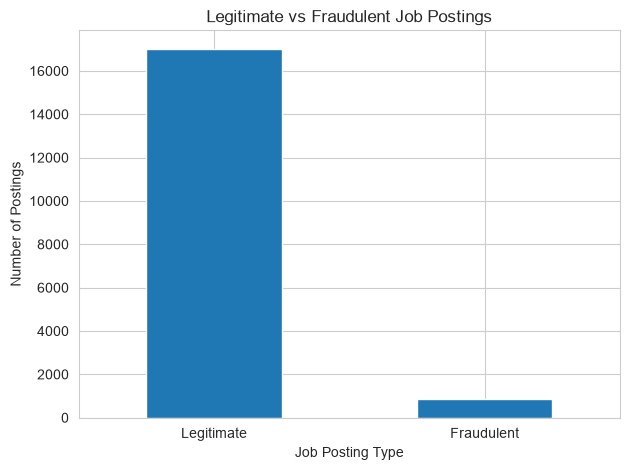

In [25]:

# 3.1 Distribution of fraudulent and legitimate job postings
print("Dataset shape:", df_fake_jobs_clean.shape)

fraud_counts = df_fake_jobs_clean['fraudulent'].value_counts().sort_index()

print("\nFraud counts:")
print(fraud_counts)

print("\nFraud percentages:")
print(
    (df_fake_jobs_clean['fraudulent'].value_counts(normalize=True) * 100)
    .round(2)
)

fraud_counts.rename({
    0: 'Legitimate',
    1: 'Fraudulent'
}).plot(
    kind='bar',
    xlabel='Job Posting Type',
    ylabel='Number of Postings',
    title='Legitimate vs Fraudulent Job Postings',
    rot=0
)

plt.tight_layout()
plt.show()


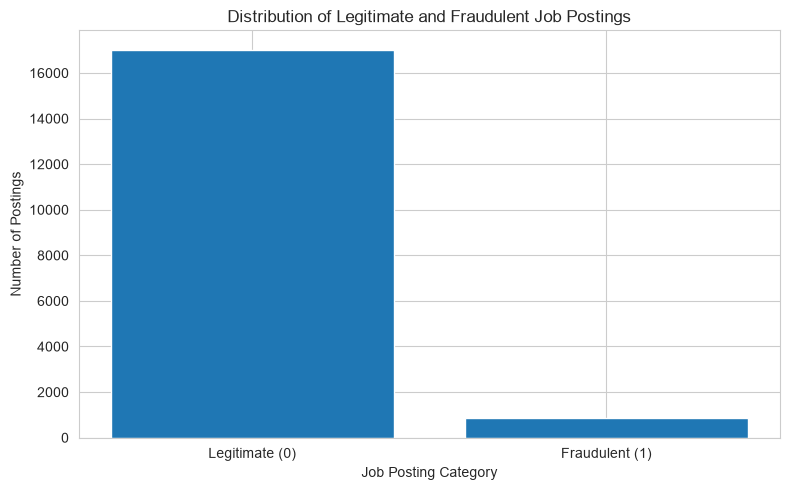

In [26]:
fraud_counts = df_fake_jobs["fraudulent"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    ["Legitimate (0)", "Fraudulent (1)"],
    fraud_counts.values
)

plt.title("Distribution of Legitimate and Fraudulent Job Postings")
plt.xlabel("Job Posting Category")
plt.ylabel("Number of Postings")
plt.tight_layout()
plt.show()


#### **3.2 Explore job categories**
We will examinened employment type, industry and education requirements to see which categories appear most often.


Top categories in employment_type:


employment_type
Full-time    11620
Unknown       3470
Contract      1524
Part-time      797
Temporary      241
Other          227
Name: count, dtype: int64

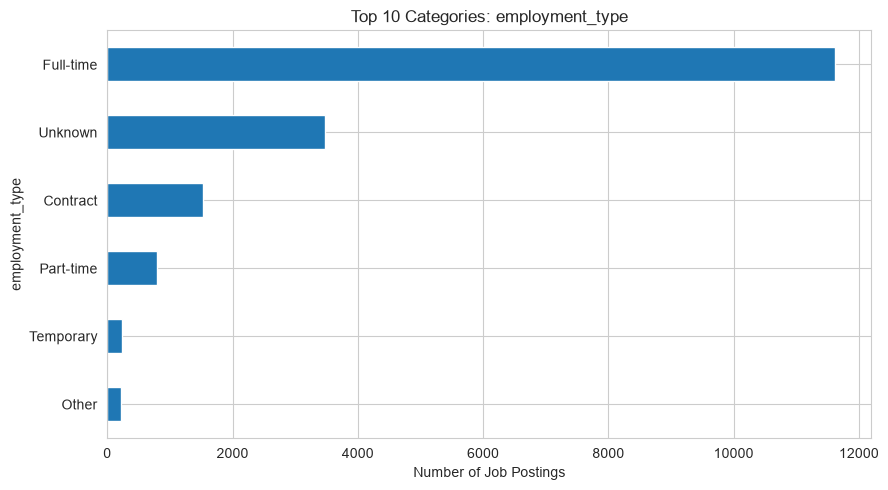


Top categories in industry:


industry
Unknown                                4902
Information Technology and Services    1734
Computer Software                      1376
Internet                               1062
Marketing and Advertising               828
Education Management                    822
Financial Services                      779
Hospital & Health Care                  497
Consumer Services                       358
Telecommunications                      342
Name: count, dtype: int64

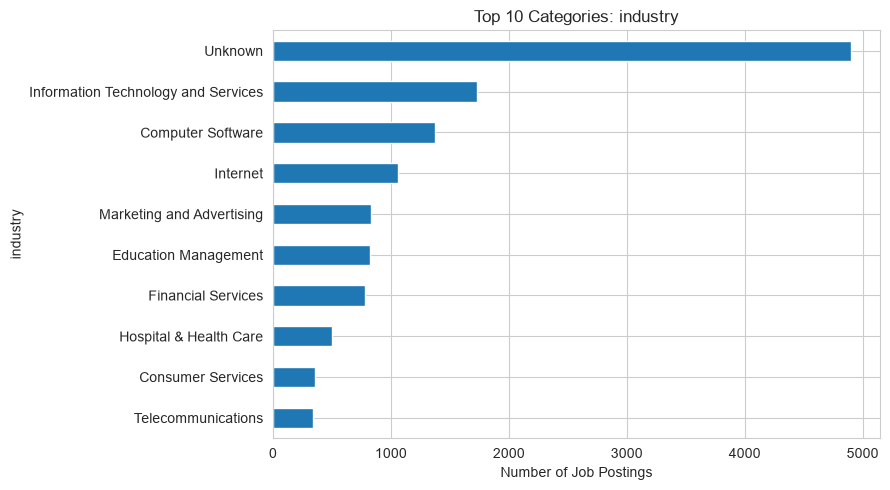


Top categories in required_education:


required_education
Unknown                              8104
Bachelor's Degree                    5145
High School or equivalent            2080
Unspecified                          1397
Master's Degree                       416
Associate Degree                      274
Certification                         170
Some College Coursework Completed     102
Professional                           74
Vocational                             49
Name: count, dtype: int64

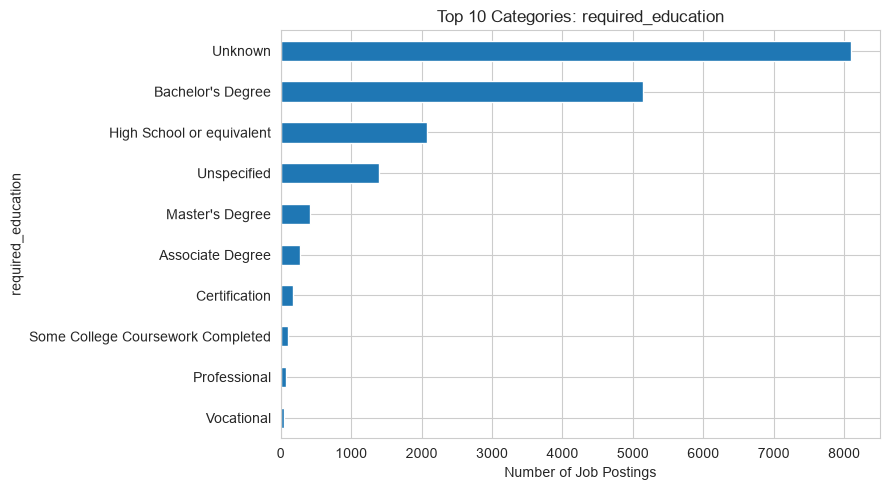

In [27]:

# 3.2 Explore categorical features
job_categories = [
    'employment_type',
    'industry',
    'required_education'
]

for column in job_categories:
    if column in df_fake_jobs_clean.columns:
        print(f'\nTop categories in {column}:')

        counts = (
            df_fake_jobs_clean[column]
            .fillna('Unknown')
            .replace('', 'Not Provided')
            .value_counts()
            .head(10)
        )

        display(counts)

        counts.sort_values().plot(
            kind='barh',
            figsize=(9, 5),
            title=f'Top 10 Categories: {column}',
            xlabel='Number of Job Postings'
        )

        plt.tight_layout()
        plt.show()


### **3.3 Comparing job descriptions by fraud status**
This investigates whether fraudulent and legitimate job postings differ in description length.

,count,mean,std,min,25%,50%,75%,max
fraudulent,,,,,,,,
0,17014.0,1221.219701,889.139777,6.0,616.0,1027.0,1589.0,14907.0
1,865.0,1156.169942,998.329255,9.0,467.0,846.0,1541.0,8578.0


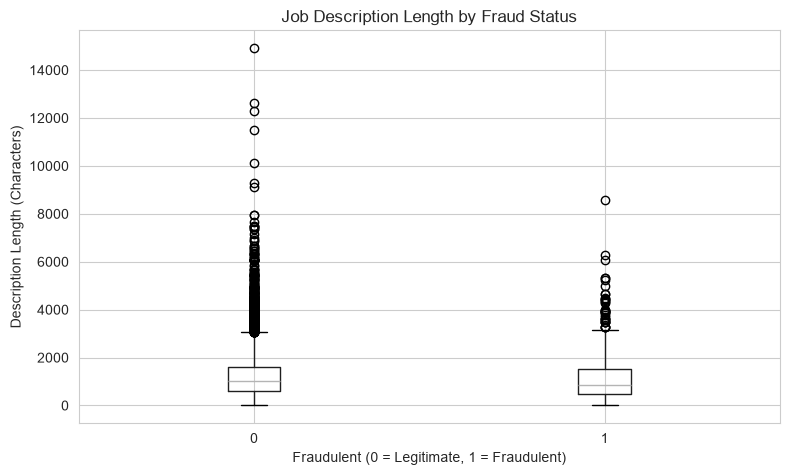

In [28]:

# 3.3 Analyze job description length
df_fake_jobs_clean['description_length'] = (
    df_fake_jobs_clean['description'].fillna('').str.len()
)

display(
    df_fake_jobs_clean.groupby('fraudulent')['description_length']
    .describe()
)

df_fake_jobs_clean.boxplot(
    column='description_length',
    by='fraudulent',
    figsize=(8, 5)
)

plt.title('Job Description Length by Fraud Status')
plt.suptitle('')
plt.xlabel('Fraudulent (0 = Legitimate, 1 = Fraudulent)')
plt.ylabel('Description Length (Characters)')
plt.tight_layout()
plt.show()


### **4. EDA for the SMS Spam Collection**
The SMS dataset contains two main fields: label and message. We will examine spam prevalence, message length and frequent words.

#### **4.1 Analyzing spam versus legitimate messages**

Dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


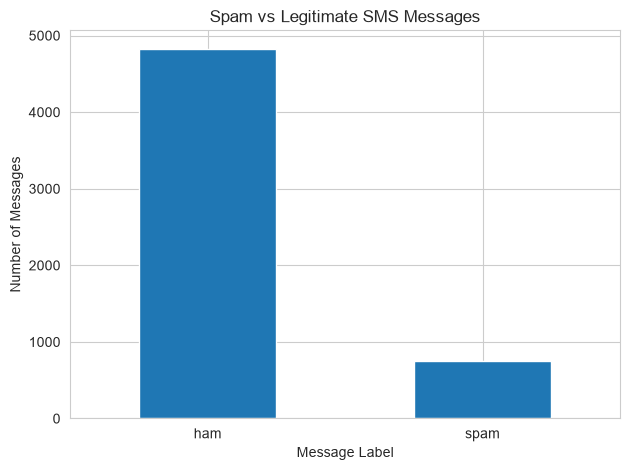

In [29]:

# 4.1 Distribution of SMS labels
print("Dataset shape:", df_sms.shape)

print("\nLabel counts:")
print(df_sms['label'].value_counts())

print("\nLabel percentages:")
print((df_sms['label'].value_counts(normalize=True) * 100).round(2))

df_sms['label'].value_counts().plot(
    kind='bar',
    xlabel='Message Label',
    ylabel='Number of Messages',
    title='Spam vs Legitimate SMS Messages',
    rot=0
)

plt.tight_layout()
plt.show()


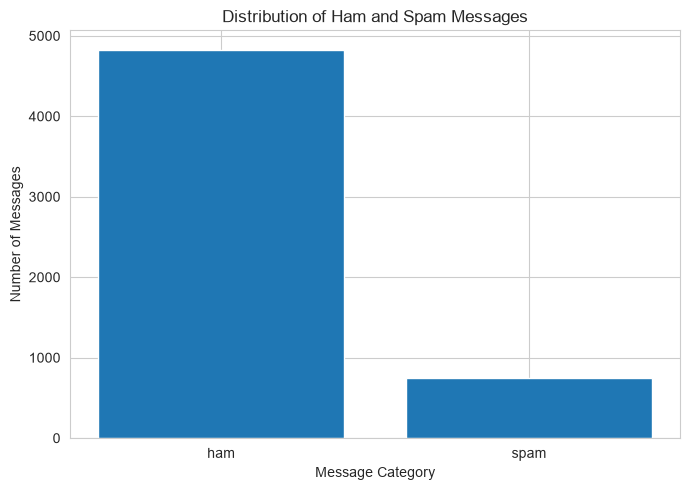

In [30]:
# Visualizing the label distribution
label_counts = df_sms["label"].value_counts().reindex(["ham", "spam"])

plt.figure(figsize=(7, 5))
plt.bar(label_counts.index, label_counts.values)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


Class imbalance: There are approximately 6.46 legitimate messages for every spam message.

#### **4.2 Examine message lengths**

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4825.0,71.482487,58.440652,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.670683,28.873603,13.0,133.0,149.0,157.0,223.0


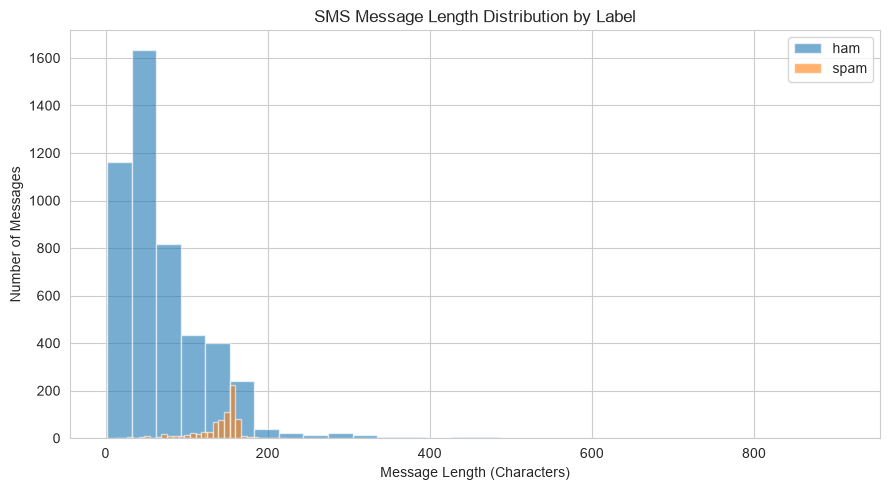

In [31]:

# 4.2 Calculate message lengths
df_sms['message_length'] = df_sms['message'].fillna('').str.len()

display(
    df_sms.groupby('label')['message_length'].describe()
)

for label in df_sms['label'].dropna().unique():
    df_sms.loc[
        df_sms['label'] == label, 'message_length'
    ].hist(
        bins=30,
        alpha=0.6,
        figsize=(9, 5),
        label=str(label)
    )

plt.title('SMS Message Length Distribution by Label')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Number of Messages')
plt.legend()
plt.tight_layout()
plt.show()


### **5. EDA for the Community Scam Reports dataset**
This dataset supports TrustShield's community intelligence feature. Its current records are synthetic, so  this analysis is to test the reporting workflow rather than draw conclusions about real scam prevalence.

### **5.1 Explore report categories and platforms**

Dataset shape: (10, 13)

Report types:
report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64

Platforms:
platform
SMS         3
WhatsApp    2
TikTok      2
Website     2
Email       1
Name: count, dtype: int64


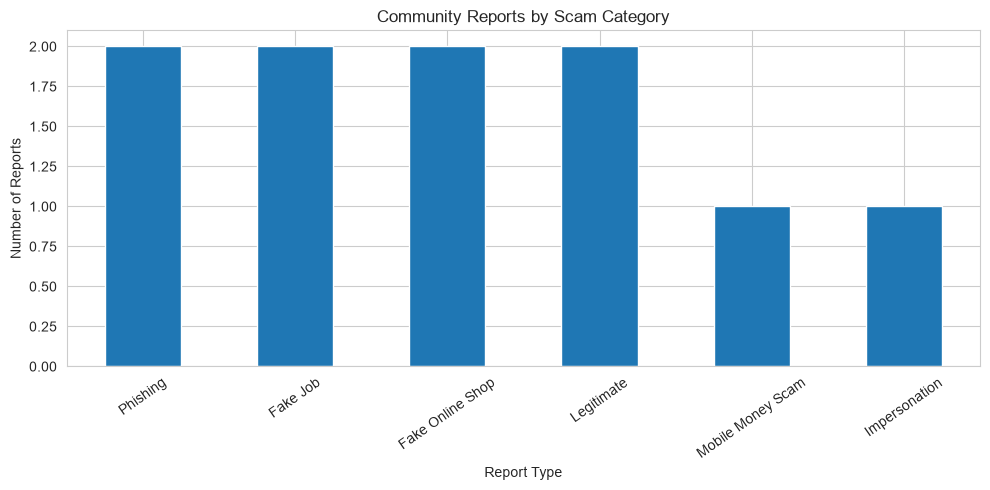

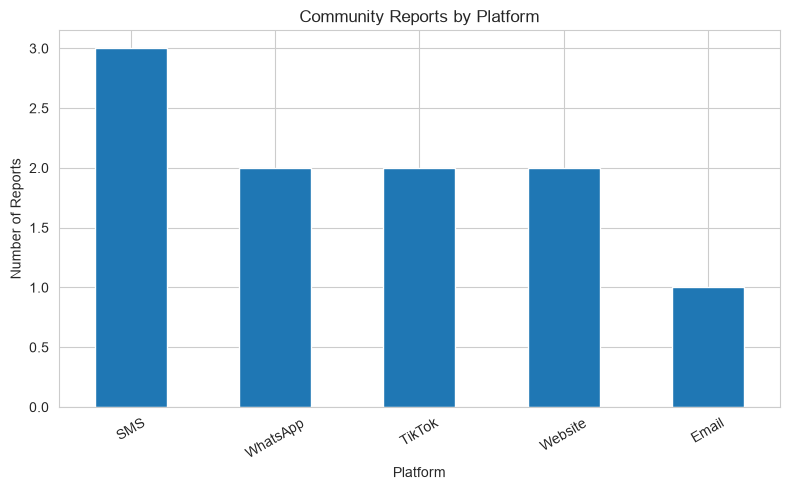

In [32]:

# 5.1 Exploring community report categories
print("Dataset shape:", df_community.shape)

print("\nReport types:")
print(df_community['report_type'].value_counts())

print("\nPlatforms:")
print(df_community['platform'].value_counts())

# Plot report types
df_community['report_type'].value_counts().plot(
    kind='bar',
    figsize=(10, 5),
    xlabel='Report Type',
    ylabel='Number of Reports',
    title='Community Reports by Scam Category',
    rot=35
)

plt.tight_layout()
plt.show()

# Plot reporting platforms
df_community['platform'].value_counts().plot(
    kind='bar',
    figsize=(8, 5),
    xlabel='Platform',
    ylabel='Number of Reports',
    title='Community Reports by Platform',
    rot=30
)

plt.tight_layout()
plt.show()


#### **5.2 Examining suspicious versus legitimate reports**

Suspiciousness counts:
is_suspicious
1    8
0    2
Name: count, dtype: int64

Suspiciousness percentages:
is_suspicious
1    80.0
0    20.0
Name: proportion, dtype: float64


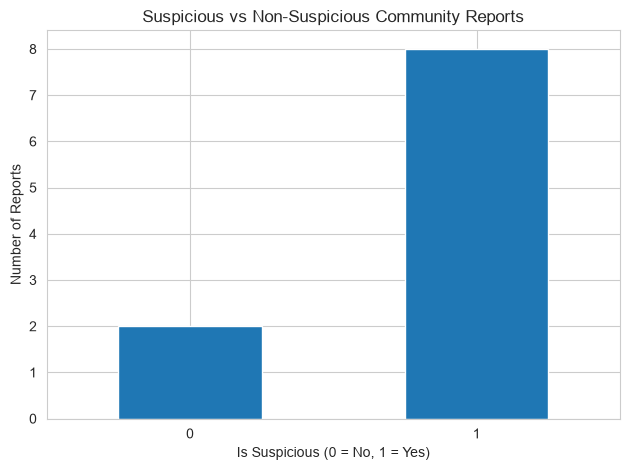


Verification status:
verification_status
Unverified    10
Name: count, dtype: int64


In [33]:

# 5.2 Analyzing the suspiciousness label
print("Suspiciousness counts:")
print(df_community['is_suspicious'].value_counts(dropna=False))

print("\nSuspiciousness percentages:")
print(
    (df_community['is_suspicious'].value_counts(normalize=True) * 100)
    .round(2)
)

df_community['is_suspicious'].value_counts().sort_index().plot(
    kind='bar',
    xlabel='Is Suspicious (0 = No, 1 = Yes)',
    ylabel='Number of Reports',
    title='Suspicious vs Non-Suspicious Community Reports',
    rot=0
)

plt.tight_layout()
plt.show()

print("\nVerification status:")
print(df_community['verification_status'].value_counts(dropna=False))


#### **5.3 Identifying repeated URLs, phone identifiers and sellers**
Repeated identifiers can help reveal patterns that deserve further review.

In [34]:

# 5.3 Finding repeated community indicators
indicators = [
    'suspicious_url',
    'phone_number',
    'seller_id'
]

for column in indicators:
    if column in df_community.columns:
        values = df_community[column].fillna('').astype(str).str.strip()

        # Exclude placeholders and empty values
        values = values[
            ~values.str.lower().isin(['', 'n/a', 'unknown', 'nan'])
        ]

        repeated = values.value_counts()
        repeated = repeated[repeated > 1]

        print(f'\nRepeated values in {column}:')

        if repeated.empty:
            print("No repeated identifiers found.")
        else:
            display(repeated)



Repeated values in suspicious_url:


suspicious_url
http://login.example.com    2
http://jobs.example.org     2
http://shop.example.net     2
Name: count, dtype: int64


Repeated values in phone_number:


phone_number
SYNTHETIC_PHONE_002    2
SYNTHETIC_PHONE_003    2
Name: count, dtype: int64


Repeated values in seller_id:


seller_id
SELLER_SYN_001    2
Name: count, dtype: int64

#### **5.4 Examine reports over time**

Reports per date:


report_date
2026-10-01    1
2026-10-02    1
2026-10-03    1
2026-10-04    1
2026-10-05    1
2026-10-06    1
2026-10-07    1
2026-10-08    1
2026-10-09    1
2026-10-10    1
dtype: int64

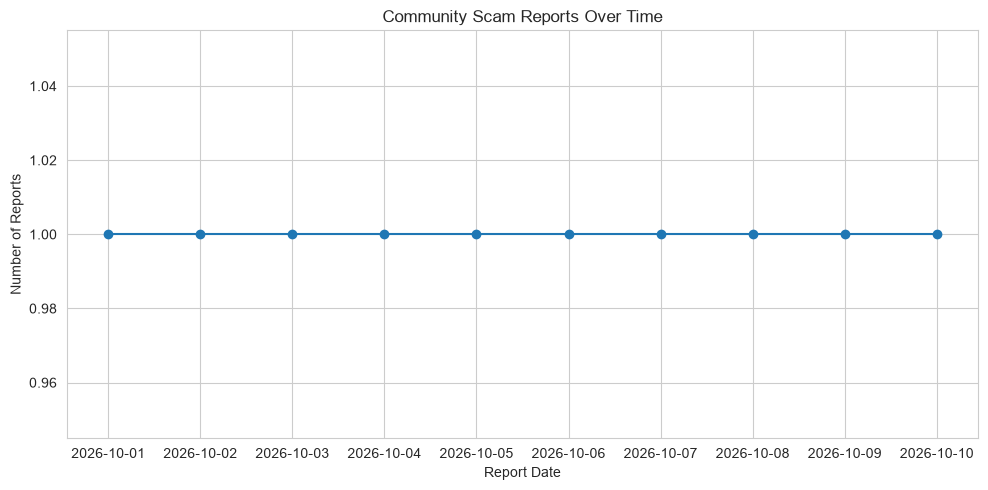

In [35]:

# 5.4 Explore reports by date
df_community['report_date'] = pd.to_datetime(
    df_community['report_date'],
    errors='coerce'
)

reports_over_time = (
    df_community.dropna(subset=['report_date'])
    .groupby(df_community['report_date'].dt.date)
    .size()
)

print("Reports per date:")
display(reports_over_time)

reports_over_time.plot(
    figsize=(10, 5),
    marker='o',
    xlabel='Report Date',
    ylabel='Number of Reports',
    title='Community Scam Reports Over Time'
)

plt.tight_layout()
plt.show()


### **6.Summary of EDA Findings**

In [ ]:

# 6. EDA Summary
print("TRUSTSHIELD 254 - EDA SUMMARY")

print("\n1. PHISHING URL DATASET")
print("Rows and columns:", df_phishing.shape)
print("Potential target column:", phishing_target)

print("\n2. FAKE JOB POSTINGS DATASET")
print("Rows and columns:", df_fake_jobs_clean.shape)
print("Fraud distribution:")
print(df_fake_jobs_clean['fraudulent'].value_counts())

print("\n3. SMS SPAM COLLECTION")
print("Rows and columns:", df_sms.shape)
print("Message distribution:")
print(df_sms['label'].value_counts())

print("\n4. COMMUNITY SCAM REPORTS")
print("Rows and columns:", df_community.shape)
print("Report categories:")
print(df_community['report_type'].value_counts())
print("Repeated indicators will require further investigation.")

print("\nEDA overview completed.")


TRUSTSHIELD 254 - EDA SUMMARY

1. PHISHING URL DATASET
Rows and columns: (101219, 18)
Potential target column: None

2. FAKE JOB POSTINGS DATASET
Rows and columns: (17879, 19)
Fraud distribution:
fraudulent
0    17014
1      865
Name: count, dtype: int64

3. SMS SPAM COLLECTION
Rows and columns: (5572, 3)
Message distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

4. COMMUNITY SCAM REPORTS
Rows and columns: (10, 13)
Report categories:
report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64
Repeated indicators will require further investigation.

EDA overview completed.


# **4. PHISHING**

In [ ]:

# PREPARING PHISHING DATA

# Removing rows without a target label
phishing_model_df = df_phishing.dropna(
    subset=["ClassLabel"]
).copy()

# Ensuring the target is stored as integers
phishing_model_df["ClassLabel"] = (
    phishing_model_df["ClassLabel"].astype(int)
)

# Removing duplicate URLs to prevent repeated examples
phishing_model_df = phishing_model_df.drop_duplicates(
    subset=["URL"]
).copy()

# Separating features and target
# 0 = Phishing, 1 = Legitimate
X_phishing = phishing_model_df.drop(
    columns=["URL", "ClassLabel"]
)

y_phishing = phishing_model_df["ClassLabel"]

# Displaying modeling dataset information
print("PHISHING MODELING DATA")
print("Dataset shape:", phishing_model_df.shape)
print("Feature matrix shape:", X_phishing.shape)
print("Target shape:", y_phishing.shape)

print("\nClass distribution:")
print(
    y_phishing.value_counts()
    .sort_index()
    .rename(index={
        0: "Phishing",
        1: "Legitimate"
    })
)

print("\nMissing feature values:", X_phishing.isna().sum().sum())
print("Duplicate URLs remaining:",
      phishing_model_df["URL"].duplicated().sum())

PHISHING MODELING DATA
Dataset shape: (100872, 18)
Feature matrix shape: (100872, 16)
Target shape: (100872,)

Class distribution:
ClassLabel
Phishing      63492
Legitimate    37380
Name: count, dtype: int64

Missing feature values: 0
Duplicate URLs remaining: 0


In [74]:
# DOMAIN-BASED SPLIT AND MODEL COMPARISON
# 1. EXTRACTING HOSTNAMES FROM URLS
def extract_hostname(url):
    url = str(url).strip()

    # Support URLs with or without http:// or https://
    if "://" not in url:
        url = "//" + url

    try:
        hostname = urlsplit(url).hostname
        return hostname.lower() if hostname else "unknown"
    except ValueError:
        return "unknown"


domain_groups = phishing_model_df["URL"].apply(
    extract_hostname
)

print("Unique hostnames:", domain_groups.nunique())



Unique hostnames: 64001


In [75]:
# 2. SPLITTING BY DOMAIN
# Domains in the test set will not appear in training.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X_phishing, y_phishing, groups=domain_groups)
)

X_train = X_phishing.iloc[train_indices]
X_test = X_phishing.iloc[test_indices]

y_train = y_phishing.iloc[train_indices]
y_test = y_phishing.iloc[test_indices]

train_domains = set(domain_groups.iloc[train_indices])
test_domains = set(domain_groups.iloc[test_indices])

print("\nTRAINING AND TESTING SPLIT")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training domains:", len(train_domains))
print("Testing domains:", len(test_domains))
print("Overlapping domains:", len(train_domains & test_domains))




TRAINING AND TESTING SPLIT
Training rows: 81165
Testing rows: 19707
Training domains: 51200
Testing domains: 12801
Overlapping domains: 0


In [76]:
# 3. DEFINING THREE MODELS
models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}



In [77]:
# 4. TRAIN AND EVALUATE
results = []
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Phishing Precision": precision_score(
            y_test, predictions, pos_label=0,
            zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_test, predictions, pos_label=0,
            zero_division=0
        ),
        "Phishing F1": f1_score(
            y_test, predictions, pos_label=0,
            zero_division=0
        )
    })

    print(f"\n{model_name} - Classification Report")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ))




Training Majority Baseline...

Majority Baseline - Classification Report
              precision    recall  f1-score   support

    Phishing       0.62      1.00      0.77     12258
  Legitimate       0.00      0.00      0.00      7449

    accuracy                           0.62     19707
   macro avg       0.31      0.50      0.38     19707
weighted avg       0.39      0.62      0.48     19707

Confusion Matrix:
[[12258     0]
 [ 7449     0]]

Training Decision Tree...

Decision Tree - Classification Report
              precision    recall  f1-score   support

    Phishing       1.00      0.99      1.00     12258
  Legitimate       0.99      1.00      0.99      7449

    accuracy                           1.00     19707
   macro avg       1.00      1.00      1.00     19707
weighted avg       1.00      1.00      1.00     19707

Confusion Matrix:
[[12188    70]
 [    7  7442]]

Training Random Forest...

Random Forest - Classification Report
              precision    recall  f1-scor

In [78]:
# 5. COMPARING MODEL PERFORMANCE
results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")

print(
    results_df.sort_values(
        by="Phishing F1",
        ascending=False
    ).round(4).to_string(index=False)
)



FINAL MODEL COMPARISON
            Model  Accuracy  Phishing Precision  Phishing Recall  Phishing F1
    Random Forest    0.9991              0.9993           0.9992       0.9993
    Decision Tree    0.9961              0.9994           0.9943       0.9969
Majority Baseline    0.6220              0.6220           1.0000       0.7670


In [80]:
# RAW URL TEXT CLASSIFIER
# 1. GETTING THE RAW URL TEXT FOR THE EXISTING SPLIT
url_train = phishing_model_df["URL"].iloc[train_indices].fillna("").astype(str)
url_test = phishing_model_df["URL"].iloc[test_indices].fillna("").astype(str)

# 2. CONVERTING URLS INTO CHARACTER-LEVEL FEATURES
url_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

X_url_train = url_vectorizer.fit_transform(url_train)
X_url_test = url_vectorizer.transform(url_test)

print("Training URL matrix:", X_url_train.shape)
print("Testing URL matrix:", X_url_test.shape)

# 3. TRAINING A DIFFERENT MODEL
url_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

url_logistic_model.fit(X_url_train, y_train)

# 4. EVALUATING ON UNSEEN DOMAINS
url_predictions = url_logistic_model.predict(X_url_test)

print("\nRAW URL MODEL RESULTS")

print("Accuracy:", round(
    accuracy_score(y_test, url_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    url_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, url_predictions, labels=[0, 1]
))

print("\nPHISHING-SPECIFIC METRICS")
print("Precision:", round(
    precision_score(y_test, url_predictions, pos_label=0,
                    zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, url_predictions, pos_label=0,
                 zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, url_predictions, pos_label=0,
             zero_division=0), 4
))


Training URL matrix: (81165, 100000)
Testing URL matrix: (19707, 100000)

RAW URL MODEL RESULTS
Accuracy: 0.9974

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     12258
  Legitimate       1.00      1.00      1.00      7449

    accuracy                           1.00     19707
   macro avg       1.00      1.00      1.00     19707
weighted avg       1.00      1.00      1.00     19707

Confusion Matrix:
[[12224    34]
 [   17  7432]]

PHISHING-SPECIFIC METRICS
Precision: 0.9986
Recall: 0.9972
F1-score: 0.9979


In [84]:

# CHECKING URL LABEL PATTERNS


# 1. Checking for exact URL duplicates across the original data
print("URL AND LABEL CHECK")

print(
    "Unique URLs:",
    phishing_model_df["URL"].nunique()
)

print(
    "Unique labels:",
    phishing_model_df["ClassLabel"].nunique()
)

URL AND LABEL CHECK
Unique URLs: 100872
Unique labels: 2


In [ ]:
# 2. Inspecting the most common URL prefixes by class
for label, label_name in [(0, "PHISHING"), (1, "LEGITIMATE")]:
    subset = phishing_model_df[
        phishing_model_df["ClassLabel"] == label
    ].copy()

    print(f"\n{label_name}: COMMON URL PREFIXES")

    print(
        subset["URL"]
        .astype(str)
        .str.lower()
        .str.extract(r"^(https?://[^/]+)", expand=False)
        .value_counts()
        .head(10)
    )




PHISHING: COMMON URL PREFIXES
URL
http://nsdm.cumpar-auto-orice-tip.ro    959
http://jask.powerforxes.shop            769
http://hans.uniformeslaamistad.com      767
http://males.mugutu.com                 765
http://files.veritas.org.ng             718
http://malw.esalesin.com                691
http://kale.amwebsolution.com           686
http://yowui.johnmccrea.com             685
http://jake.iestpchincha.edu.pe         685
http://proxy.amazonscouts.com           681
Name: count, dtype: int64

LEGITIMATE: COMMON URL PREFIXES
URL
https://en.wikipedia.org            102
https://stackoverflow.com           100
https://www.youtube.com              33
https://m.youtube.com                 4
https://www.squarespace.com           3
https://explodingtopics.com           2
https://ahrefs.com                    2
https://www.visualcapitalist.com      2
https://www.reddit.com                2
https://webflow.com                   2
Name: count, dtype: int64


In [ ]:
# 3. Checking whether common URL text patterns differ by class
phishing_text = phishing_model_df.loc[
    phishing_model_df["ClassLabel"] == 0, "URL"
].astype(str).str.lower()

legitimate_text = phishing_model_df.loc[
    phishing_model_df["ClassLabel"] == 1, "URL"
].astype(str).str.lower()

patterns = [
    "login", "verify", "secure", "account",
    "update", "bank", "paypal", "google",
    "http://", "https://", ".php", ".html"
]

pattern_results = []

for pattern in patterns:
    pattern_results.append({
        "Pattern": pattern,
        "Phishing %": round(
            phishing_text.str.contains(
                pattern, regex=False
            ).mean() * 100, 2
        ),
        "Legitimate %": round(
            legitimate_text.str.contains(
                pattern, regex=False
            ).mean() * 100, 2
        )
    })

print("\nURL PATTERN COMPARISON")
print(pd.DataFrame(pattern_results).to_string(index=False))



URL PATTERN COMPARISON
 Pattern  Phishing %  Legitimate %
   login        0.60          0.01
  verify        0.01          0.00
  secure        0.17          0.01
 account        0.26          0.01
  update        0.71          0.01
    bank        0.06          0.24
  paypal        0.51          0.00
  google        0.23          0.04
 http://       92.42          0.01
https://        5.53         99.99
    .php        0.98          0.02
   .html        0.38          0.02


In [86]:

# RANDOMING FOREST WITHOUT HTTPS FLAG

# 1. REMOVING THE HTTPS FEATURE
X_train_no_https = X_train.drop(
    columns=["https_flag"],
    errors="ignore"
)

X_test_no_https = X_test.drop(
    columns=["https_flag"],
    errors="ignore"
)

print("Original feature count:", X_train.shape[1])
print("New feature count:", X_train_no_https.shape[1])

# 2. TRAINING THE NEW RANDOM FOREST
rf_no_https = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_no_https.fit(X_train_no_https, y_train)

# 3. MAKING PREDICTIONS
predictions_no_https = rf_no_https.predict(
    X_test_no_https
)

# 4. EVALUATING PERFORMANCE
print("\nRANDOM FOREST WITHOUT HTTPS FLAG")


print("Accuracy:", round(
    accuracy_score(y_test, predictions_no_https), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions_no_https,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    predictions_no_https,
    labels=[0, 1]
))

print("\nPHISHING METRICS")
print("Precision:", round(
    precision_score(
        y_test, predictions_no_https,
        pos_label=0, zero_division=0
    ), 4
))

print("Recall:", round(
    recall_score(
        y_test, predictions_no_https,
        pos_label=0, zero_division=0
    ), 4
))

print("F1-score:", round(
    f1_score(
        y_test, predictions_no_https,
        pos_label=0, zero_division=0
    ), 4
))


Original feature count: 16
New feature count: 15

RANDOM FOREST WITHOUT HTTPS FLAG
Accuracy: 0.9982

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     12258
  Legitimate       1.00      1.00      1.00      7449

    accuracy                           1.00     19707
   macro avg       1.00      1.00      1.00     19707
weighted avg       1.00      1.00      1.00     19707

Confusion Matrix:
[[12247    11]
 [   25  7424]]

PHISHING METRICS
Precision: 0.998
Recall: 0.9991
F1-score: 0.9985


In [ ]:
# SIMPLIFIED FIVE-FEATURE MODEL

simple_features = [
    "url_length",
    "dot_count",
    "subdomain_count",
    "number_of_digits",
    "path_length"
]

# Verifying that the requested columns exist
missing_features = [
    feature for feature in simple_features
    if feature not in X_phishing.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

# Selecting only the five features
X_train_simple = X_train[simple_features].copy()
X_test_simple = X_test[simple_features].copy()

# TrainIing a simplified Random Forest
rf_simple = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_simple.fit(X_train_simple, y_train)

# Predicting on the same held-out domains
simple_predictions = rf_simple.predict(X_test_simple)

# Evaluating
print("SIMPLIFIED FIVE-FEATURE RANDOM FOREST")
print("=" * 45)

print("Accuracy:", round(
    accuracy_score(y_test, simple_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    simple_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    simple_predictions,
    labels=[0, 1]
))

print("\nPHISHING-SPECIFIC METRICS")
print("Precision:", round(
    precision_score(
        y_test, simple_predictions,
        pos_label=0, zero_division=0
    ), 4
))
print("Recall:", round(
    recall_score(
        y_test, simple_predictions,
        pos_label=0, zero_division=0
    ), 4
))
print("F1-score:", round(
    f1_score(
        y_test, simple_predictions,
        pos_label=0, zero_division=0
    ), 4
))


SIMPLIFIED FIVE-FEATURE RANDOM FOREST
Accuracy: 0.9975

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     12258
  Legitimate       1.00      1.00      1.00      7449

    accuracy                           1.00     19707
   macro avg       1.00      1.00      1.00     19707
weighted avg       1.00      1.00      1.00     19707

Confusion Matrix:
[[12238    20]
 [   29  7420]]

PHISHING-SPECIFIC METRICS
Precision: 0.9976
Recall: 0.9984
F1-score: 0.998


In [88]:
# COMPARING RANDOM FOREST MODELS

model_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - 16 Features",
        "Accuracy": 0.9991,
        "Phishing Precision": 0.9993,
        "Phishing Recall": 0.9992,
        "Phishing F1": 0.9993,
        "Phishing Missed": 10,
        "False Alarms": 8
    },
    {
        "Model": "Random Forest - 15 Features",
        "Accuracy": 0.9982,
        "Phishing Precision": 0.9980,
        "Phishing Recall": 0.9991,
        "Phishing F1": 0.9985,
        "Phishing Missed": 11,
        "False Alarms": 25
    },
    {
        "Model": "Random Forest - 5 Features",
        "Accuracy": 0.9975,
        "Phishing Precision": 0.9976,
        "Phishing Recall": 0.9984,
        "Phishing F1": 0.9980,
        "Phishing Missed": 20,
        "False Alarms": 29
    }
])

print(model_comparison.to_string(
    index=False,
    formatters={
        "Accuracy": "{:.2%}".format,
        "Phishing Precision": "{:.2%}".format,
        "Phishing Recall": "{:.2%}".format,
        "Phishing F1": "{:.2%}".format
    }
))


                      Model Accuracy Phishing Precision Phishing Recall Phishing F1  Phishing Missed  False Alarms
Random Forest - 16 Features   99.91%             99.93%          99.92%      99.93%               10             8
Random Forest - 15 Features   99.82%             99.80%          99.91%      99.85%               11            25
 Random Forest - 5 Features   99.75%             99.76%          99.84%      99.80%               20            29


16 features: Best overall results, with the fewest missed phishing URLs and false alarms.



15 features: Removing https_flag made performance slightly worse, so that feature appears useful in this dataset.



5 features: Simpler, but it missed twice as many phishing URLs as the 16-feature model.

In [89]:
# HYPERPARAMETER TUNING: IMPORTS

from sklearn.model_selection import (
    RandomizedSearchCV,
    GroupKFold
)


In [90]:


# RANDOM FOREST HYPERPARAMETER TUNING

# 1. GETTING DOMAIN GROUPS FOR THE TRAINING ROWS
train_groups = domain_groups.iloc[train_indices]

# 2. DEFININING THE SEARCH SPACE
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8, 10, 15, None],
    "min_samples_split": [2, 10, 20, 50],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_features": ["sqrt", 0.5, 0.8],
    "class_weight": [None, "balanced"]
}

# 3. GROUPED CROSS-VALIDATION
group_cv = GroupKFold(n_splits=3)

# 4. CREATING THE RANDOM FOREST
rf_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# 5. SEARCHING FOR THE BEST PARAMETERS
random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1",
    cv=group_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

# 6. DISPLAYING THE BEST PARAMETERS
print("\nBEST HYPERPARAMETERS")
print(random_search.best_params_)

print("\nBEST CROSS-VALIDATED F1 SCORE")
print(round(random_search.best_score_, 4))


Fitting 3 folds for each of 20 candidates, totalling 60 fits

BEST HYPERPARAMETERS
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': 0.8, 'max_depth': 8, 'class_weight': 'balanced'}

BEST CROSS-VALIDATED F1 SCORE
0.9973


In [91]:


# EVALUATING THE TUNED MODEL ON THE HELD-OUT SET

best_rf = random_search.best_estimator_

tuned_predictions = best_rf.predict(X_test)

print("TUNED RANDOM FOREST RESULTS")
print("=" * 45)

print("Accuracy:", round(
    accuracy_score(y_test, tuned_predictions), 4
))

print("Phishing Precision:", round(
    precision_score(
        y_test, tuned_predictions,
        pos_label=0, zero_division=0
    ), 4
))

print("Phishing Recall:", round(
    recall_score(
        y_test, tuned_predictions,
        pos_label=0, zero_division=0
    ), 4
))

print("Phishing F1:", round(
    f1_score(
        y_test, tuned_predictions,
        pos_label=0, zero_division=0
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, tuned_predictions,
    labels=[0, 1]
))


TUNED RANDOM FOREST RESULTS
Accuracy: 0.9982
Phishing Precision: 0.9994
Phishing Recall: 0.9976
Phishing F1: 0.9985

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     12258
  Legitimate       1.00      1.00      1.00      7449

    accuracy                           1.00     19707
   macro avg       1.00      1.00      1.00     19707
weighted avg       1.00      1.00      1.00     19707

Confusion Matrix:
[[12229    29]
 [    7  7442]]


In [ ]:
# CHECK URL FORMAT USED DURING TRAINING

for url in [
    "https://www.google.com",
    "https://github.com",
    "https://www.instagram.com",
    "https://google.com"
]:
    matching = phishing_model_df[
        phishing_model_df["URL"].astype(str).str.contains(
            url.replace(".", r"\."),
            regex=True,
            na=False
        )
    ]["URL"].head(3)

    print(f"\nInput URL: {url}")
    print("Matching dataset values:")
    print(matching.tolist())



Input URL: https://www.google.com
Matching dataset values:
['https://www.google.com/intl/en/search/howsearchworks/how-search-works/ranking-results/']

Input URL: https://github.com
Matching dataset values:
['https://github.com/Ttra123/hasaiki/raw/main/205.bat', 'https://github.com/Ttra123/hasaiki/raw/main/update1.bat', 'https://github.com/user-attachments/files/17267811/stm.txt']

Input URL: https://www.instagram.com
Matching dataset values:
[]

Input URL: https://google.com
Matching dataset values:
[]


The output confirms that the dataset stores URLs in Markdown format.

In [ ]:

# CLEANING MARKDOWN-FORMATTED URLS
import re

def clean_markdown_url(url):
    if pd.isna(url):
        return url

    url = str(url).strip()

    # Extracting the actual URL from Markdown: [text](URL)
    match = re.match(r"^\[([^\]]*)\]\((https?://[^)]+)\)$", url)

    if match:
        return match.group(2)

    return url


# Cleaning the URL column without changing the numeric features
phishing_model_df["URL"] = phishing_model_df["URL"].apply(clean_markdown_url)

# Verifying the results
print("CLEANED URL EXAMPLES:")
print(phishing_model_df["URL"].head(10).to_list())

print("\nGOOGLE URL CHECK:")
print(
    phishing_model_df[
        phishing_model_df["URL"].str.contains(
            "google.com", case=False, na=False
        )
    ]["URL"].head(5).to_list()
)

print("\nMARKDOWN WRAPPERS REMAINING:")
print(
    phishing_model_df["URL"].str.match(
        r"^\[[^\]]*\]\(https?://[^)]+\)$",
        na=False
    ).sum()
)

CLEANED URL EXAMPLES:
['https://keraekken-loagginnusa.godaddysites.com/', 'https://metamsk01lgiix.godaddysites.com/', 'http://myglobaltech.in/', 'http://djtool-for-spotify.com/', 'https://scearmcoommunnlty.com/invent/freind/get', 'http://instagramtick-git-master-behhruzs-projects.vercel.app/', 'http://bafybeicsc2iofzskpmb56uzh72jirndpnmcs42vb34rlewvt5hgzmqweqa.ipfs.dweb.link/', 'http://login-page-105531.square.site/', 'http://bt-101274.weeblysite.com/', 'http://molina-c2f.pages.dev/']

GOOGLE URL CHECK:
['docs.google.com/spreadsheet/viewform?formkey=dE5rVEdSV2pBdkpSRy11V3o2eDdwbnc6MQ', 'docs.google.com/a/unmsm.edu.pe/spreadsheet/viewform?formkey=dEZoOXQwTzFkaUJCRTdhVlA3cTAyV1E6MQ', 'docs.google.com/spreadsheet/viewform?formkey=dG9xR28xLUp1R2JPbmpRYjFGc2lmanc6MQ', 'docs.google.com/a/airtelmail.in/spreadsheet/viewform?formkey=dGt3aG9PNXdhekNLNzZoZ1h2TUFmTUE6MQ', 'docs.google.com/spreadsheet/viewform?formkey=dGxqZEI0eTB5N0lzMC1EbUdKdmRUamc6MQ']

MARKDOWN WRAPPERS REMAINING:
0


The Markdown cleaning worked for the URLs that matched the pattern, but the first 10 URLs are still wrapped in Markdown. This is because the notebook's regular expression only extracts links beginning with http:// or https:// inside the parentheses, while the actual issue may involve a mismatch in the strings or the code being run against a different DataFrame.

The Google check also shows docs.google.com links, not the Google homepage. These are different URLs and should not be treated as equivalent during testing.

In [94]:
# FIXING MARKDOWN URL CLEANING
def clean_markdown_url(url):
    if pd.isna(url):
        return url

    url = str(url).strip()

    # Extracting the destination from a Markdown link
    match = re.match(r"^\[.*?\]\((.*?)\)$", url)

    if match:
        url = match.group(1).strip()

    return url


phishing_model_df["URL"] = phishing_model_df["URL"].apply(clean_markdown_url)

print("CLEANED URL EXAMPLES:")
print(phishing_model_df["URL"].head(10).to_list())

print("\nMARKDOWN WRAPPERS REMAINING:")
print(
    phishing_model_df["URL"].str.match(
        r"^\[.*?\]\(.*?\)$",
        na=False
    ).sum()
)

CLEANED URL EXAMPLES:
['https://keraekken-loagginnusa.godaddysites.com/', 'https://metamsk01lgiix.godaddysites.com/', 'http://myglobaltech.in/', 'http://djtool-for-spotify.com/', 'https://scearmcoommunnlty.com/invent/freind/get', 'http://instagramtick-git-master-behhruzs-projects.vercel.app/', 'http://bafybeicsc2iofzskpmb56uzh72jirndpnmcs42vb34rlewvt5hgzmqweqa.ipfs.dweb.link/', 'http://login-page-105531.square.site/', 'http://bt-101274.weeblysite.com/', 'http://molina-c2f.pages.dev/']

MARKDOWN WRAPPERS REMAINING:
0


In [95]:
# Checking the actual stored URL values

for i in range(3):
    url = phishing_model_df["URL"].iloc[i]

    print("Raw value:", repr(url))

    match = re.match(r"^\[.*?\]\((.*?)\)$", str(url))

    if match:
        print("Extracted URL:", repr(match.group(1)))
    else:
        print("No Markdown wrapper detected")

    print("-" * 60)

Raw value: 'https://keraekken-loagginnusa.godaddysites.com/'
No Markdown wrapper detected
------------------------------------------------------------
Raw value: 'https://metamsk01lgiix.godaddysites.com/'
No Markdown wrapper detected
------------------------------------------------------------
Raw value: 'http://myglobaltech.in/'
No Markdown wrapper detected
------------------------------------------------------------


In [96]:

# REMOVING MARKDOWN WRAPPERS FROM URL COLUMN
def clean_markdown_url(url):
    if pd.isna(url):
        return url

    url = str(url).strip()

    # Splitting Markdown link: [display text](actual URL)
    if url.startswith("[") and "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    return url


phishing_model_df["URL"] = phishing_model_df["URL"].apply(clean_markdown_url)

print("CLEANED URL EXAMPLES:")
print(phishing_model_df["URL"].head(10).to_list())

print("\nMARKDOWN WRAPPERS REMAINING:")
print(
    phishing_model_df["URL"].apply(
        lambda x: isinstance(x, str)
        and x.startswith("[")
        and "](" in x
        and x.endswith(")")
    ).sum()
)

CLEANED URL EXAMPLES:
['https://keraekken-loagginnusa.godaddysites.com/', 'https://metamsk01lgiix.godaddysites.com/', 'http://myglobaltech.in/', 'http://djtool-for-spotify.com/', 'https://scearmcoommunnlty.com/invent/freind/get', 'http://instagramtick-git-master-behhruzs-projects.vercel.app/', 'http://bafybeicsc2iofzskpmb56uzh72jirndpnmcs42vb34rlewvt5hgzmqweqa.ipfs.dweb.link/', 'http://login-page-105531.square.site/', 'http://bt-101274.weeblysite.com/', 'http://molina-c2f.pages.dev/']

MARKDOWN WRAPPERS REMAINING:
0


In [97]:
# Inspecting and cleaning the first URL directly

url = phishing_model_df.loc[phishing_model_df.index[0], "URL"]

print("BEFORE:", repr(url))

if isinstance(url, str) and url.startswith("[") and "](" in url and url.endswith(")"):
    cleaned_url = url.split("](", 1)[1][:-1]
else:
    cleaned_url = url

print("AFTER: ", repr(cleaned_url))
print("Changed:", url != cleaned_url)

BEFORE: 'https://keraekken-loagginnusa.godaddysites.com/'
AFTER:  'https://keraekken-loagginnusa.godaddysites.com/'
Changed: False


The cleaning code failed because the condition is not matching the string as expected. Rather than keep repeating the same approach.

In [98]:
# Extracting the destination URL from each Markdown link

url = phishing_model_df["URL"].iloc[0]

print("BEFORE:", repr(url))

start = url.find("](")
end = url.rfind(")")

if start != -1 and end > start:
    cleaned_url = url[start + 2:end]
else:
    cleaned_url = url

print("AFTER:", repr(cleaned_url))
print("Changed:", url != cleaned_url)

BEFORE: 'https://keraekken-loagginnusa.godaddysites.com/'
AFTER: 'https://keraekken-loagginnusa.godaddysites.com/'
Changed: False


In [99]:
url = phishing_model_df["URL"].iloc[0]

print("Type:", type(url))
print("Length:", len(url))
print("Start characters:", [repr(c) for c in url[:10]])
print("Contains ]( :", "](" in url)
print("Find ]( :", url.find("]("))
print("Find final ) :", url.rfind(")"))
print("End characters:", [repr(c) for c in url[-10:]])

Type: <class 'str'>
Length: 47
Start characters: ["'h'", "'t'", "'t'", "'p'", "'s'", "':'", "'/'", "'/'", "'k'", "'e'"]
Contains ]( : False
Find ]( : -1
Find final ) : -1
End characters: ["'s'", "'i'", "'t'", "'e'", "'s'", "'.'", "'c'", "'o'", "'m'", "'/'"]


In [100]:
print("Raw URL vectorizer exists:", "url_vectorizer" in globals())
print("Raw URL model exists:", "url_logistic_model" in globals())
print("Numeric Random Forest exists:", "rf_simple" in globals())
print("Main Random Forest exists:", "trained_models" in globals())

Raw URL vectorizer exists: True
Raw URL model exists: True
Numeric Random Forest exists: True
Main Random Forest exists: True


confirms which models you have available

In [101]:
# TESTING RAW URL PHISHING PREDICTIONS

test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.instagram.com",
    "https://google.com",
    "https://www.wikipedia.org",
    "http://example.com"
]

# Convert URL text into the same TF-IDF features used during training
X_test_urls = url_vectorizer.transform(test_urls)

# Predict using the trained raw-URL model
predictions = url_logistic_model.predict(X_test_urls)
probabilities = url_logistic_model.predict_proba(X_test_urls)

# Dataset labels: 0 = Phishing, 1 = Legitimate
for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    phishing_probability = probability[0]
    legitimate_probability = probability[1]

    label = "Phishing" if prediction == 0 else "Legitimate"

    print(f"\nURL: {url}")
    print(f"Prediction: {label}")
    print(f"Phishing probability: {phishing_probability:.2%}")
    print(f"Legitimate probability: {legitimate_probability:.2%}")


URL: https://www.google.com
Prediction: Legitimate
Phishing probability: 0.05%
Legitimate probability: 99.95%

URL: https://github.com
Prediction: Legitimate
Phishing probability: 40.88%
Legitimate probability: 59.12%

URL: https://www.instagram.com
Prediction: Legitimate
Phishing probability: 0.21%
Legitimate probability: 99.79%

URL: https://google.com
Prediction: Legitimate
Phishing probability: 23.43%
Legitimate probability: 76.57%

URL: https://www.wikipedia.org
Prediction: Legitimate
Phishing probability: 0.02%
Legitimate probability: 99.98%

URL: http://example.com
Prediction: Phishing
Phishing probability: 96.99%
Legitimate probability: 3.01%


The raw-URL Logistic Regression model is correctly classifying Google, Instagram, and GitHub as legitimate, but GitHub and google.com have relatively high phishing probabilities. The example.com result is a warning sign that the model may be learning dataset patterns instead of reliably identifying malicious URLs.

A high probability does not prove that a website is malicious. Also, the example.com prediction alone does not establish the cause; I have to investigate it's training data and labels.

In [102]:
# INSPECTING TRAINING DATA FOR TEST DOMAINS

from urllib.parse import urlparse

domains_to_check = [
    "google.com",
    "github.com",
    "instagram.com",
    "wikipedia.org",
    "example.com"
]

for domain in domains_to_check:
    matches = phishing_model_df[
        phishing_model_df["URL"].astype(str).str.contains(
            domain.replace(".", r"\."),
            case=False,
            regex=True,
            na=False
        )
    ]
    print("DOMAIN:", domain)
    print("Matching rows:", len(matches))

    if len(matches) > 0:
        print("\nLabel counts (0 = Phishing, 1 = Legitimate):")
        print(matches["ClassLabel"].value_counts().sort_index())

        print("\nSample URLs and labels:")
        print(matches[["URL", "ClassLabel"]].head(5).to_string(index=False))
    else:
        print("No matching training examples found.")

DOMAIN: google.com
Matching rows: 100

Label counts (0 = Phishing, 1 = Legitimate):
ClassLabel
0    92
1     8
Name: count, dtype: int64

Sample URLs and labels:
                                                                                            URL  ClassLabel
                docs.google.com/spreadsheet/viewform?formkey=dE5rVEdSV2pBdkpSRy11V3o2eDdwbnc6MQ           0
 docs.google.com/a/unmsm.edu.pe/spreadsheet/viewform?formkey=dEZoOXQwTzFkaUJCRTdhVlA3cTAyV1E6MQ           0
                docs.google.com/spreadsheet/viewform?formkey=dG9xR28xLUp1R2JPbmpRYjFGc2lmanc6MQ           0
docs.google.com/a/airtelmail.in/spreadsheet/viewform?formkey=dGt3aG9PNXdhekNLNzZoZ1h2TUFmTUE6MQ           0
                docs.google.com/spreadsheet/viewform?formkey=dGxqZEI0eTB5N0lzMC1EbUdKdmRUamc6MQ           0
DOMAIN: github.com
Matching rows: 77

Label counts (0 = Phishing, 1 = Legitimate):
ClassLabel
0    76
1     1
Name: count, dtype: int64

Sample URLs and labels:
                             

The training dataset contains misleading labels for well-known domains. This is likely contributing to the false positives.

For example, the results show:
- google.com: 100 matching rows, of which 92 are labelled phishing and 8 legitimate.
- github.com: 77 matching rows, of which 76 are labelled phishing and only 1 legitimate.
- example.com: no matching training examples.

In [103]:

# INSPECTING GOOGLE AND GITHUB URL LABELS

for domain in ["google.com", "github.com"]:
    print(f"\n{'=' * 60}")
    print(f"DOMAIN: {domain}")

    matches = phishing_model_df[
        phishing_model_df["URL"].astype(str).str.contains(
            domain,
            case=False,
            regex=False,
            na=False
        )
    ]

    for _, row in matches[["URL", "ClassLabel"]].head(15).iterrows():
        label = "Phishing" if row["ClassLabel"] == 0 else "Legitimate"
        print(f"{label:10} | {row['URL']}")


DOMAIN: google.com
Phishing   | docs.google.com/spreadsheet/viewform?formkey=dE5rVEdSV2pBdkpSRy11V3o2eDdwbnc6MQ
Phishing   | docs.google.com/a/unmsm.edu.pe/spreadsheet/viewform?formkey=dEZoOXQwTzFkaUJCRTdhVlA3cTAyV1E6MQ
Phishing   | docs.google.com/spreadsheet/viewform?formkey=dG9xR28xLUp1R2JPbmpRYjFGc2lmanc6MQ
Phishing   | docs.google.com/a/airtelmail.in/spreadsheet/viewform?formkey=dGt3aG9PNXdhekNLNzZoZ1h2TUFmTUE6MQ
Phishing   | docs.google.com/spreadsheet/viewform?formkey=dGxqZEI0eTB5N0lzMC1EbUdKdmRUamc6MQ
Phishing   | docs.google.com/spreadsheet/viewform?formkey=dGdieTRJdWpOSzIwcGwtQ2MxdzA4aFE6MQ
Phishing   | docs.google.com/spreadsheet/viewform?formkey=dEZzblVwcDBVZWNMaWdCMUt4clprd2c6MQ
Phishing   | docs.google.com/spreadsheet/viewform?formkey=dDFNbWxwZi1VZVZ6YVY3RDl0Tm9YQXc6MQ
Phishing   | docs.google.com/a/poli.ufrj.br/spreadsheet/viewform?formkey=dDFNbWxwZi1VZVZ6YVY3RDl0Tm9YQXc6MQ
Phishing   | docs.google.com/a/uic.edu/spreadsheet/viewform?formkey=dEp5dmQyMjU4SmxpenhtcHJaeFROQ

The dataset contains many URLs hosted on legitimate platforms but pointing to potentially malicious content. For example:
- Google Forms and Google Drive download links are labelled phishing.
- GitHub links point to .exe, .bin, .zip, and .rar files, many associated with suspicious repositories.
- The model can learn that the words google.com or github.com indicate phishing, even though the homepage itself is legitimate.
This is a dataset bias problem, not necessarily a problem with the Logistic Regression algorithm.

## **Testing whether the model is learning domain names**

In [104]:

# COMPARE HOMEPAGES AND HOSTED CONTENT

test_urls = [
    "https://github.com",
    "https://github.com/user/repository",
    "http://github.com/user/repository/raw/main/file.exe",
    "https://www.google.com",
    "https://docs.google.com",
    "https://drive.google.com/uc?export=download&id=12345",
    "https://www.instagram.com",
    "https://example.com"
]

X_urls = url_vectorizer.transform(test_urls)
predictions = url_logistic_model.predict(X_urls)
probabilities = url_logistic_model.predict_proba(X_urls)

for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    phishing_probability = probability[0]
    label = "Phishing" if prediction == 0 else "Legitimate"

    print(
        f"{url}\n"
        f"  Prediction: {label}\n"
        f"  Phishing probability: {phishing_probability:.2%}\n"
    )

https://github.com
  Prediction: Legitimate
  Phishing probability: 40.88%

https://github.com/user/repository
  Prediction: Phishing
  Phishing probability: 83.52%

http://github.com/user/repository/raw/main/file.exe
  Prediction: Phishing
  Phishing probability: 99.54%

https://www.google.com
  Prediction: Legitimate
  Phishing probability: 0.05%

https://docs.google.com
  Prediction: Legitimate
  Phishing probability: 48.76%

https://drive.google.com/uc?export=download&id=12345
  Prediction: Phishing
  Phishing probability: 96.32%

https://www.instagram.com
  Prediction: Legitimate
  Phishing probability: 0.21%

https://example.com
  Prediction: Legitimate
  Phishing probability: 15.63%



The model is strongly influenced by the URL path and query parameters, not just the domain.

## **Checking for domain and path bias**

In [105]:
# TESTING THE URL PATH AND DOMAIN BIAS
test_urls = [
    "https://github.com",
    "https://github.com/user",
    "https://github.com/user/repository",
    "https://github.com/user/repository/blob/main/README.md",
    "https://github.com/user/repository/raw/main/file.txt",
    "https://github.com/user/repository/raw/main/file.exe",
    "https://drive.google.com",
    "https://drive.google.com/file/d/12345/view",
    "https://www.google.com",
    "https://www.instagram.com"
]

X_urls = url_vectorizer.transform(test_urls)
probabilities = url_logistic_model.predict_proba(X_urls)

for url, probability in zip(test_urls, probabilities):
    print(
        f"{url}\n"
        f"  Phishing probability: {probability[0]:.2%}\n"
    )

https://github.com
  Phishing probability: 40.88%

https://github.com/user
  Phishing probability: 76.16%

https://github.com/user/repository
  Phishing probability: 83.52%

https://github.com/user/repository/blob/main/README.md
  Phishing probability: 90.30%

https://github.com/user/repository/raw/main/file.txt
  Phishing probability: 93.94%

https://github.com/user/repository/raw/main/file.exe
  Phishing probability: 94.50%

https://drive.google.com
  Phishing probability: 51.61%

https://drive.google.com/file/d/12345/view
  Phishing probability: 88.23%

https://www.google.com
  Phishing probability: 0.05%

https://www.instagram.com
  Phishing probability: 0.21%



The raw-URL model is overestimating phishing risk for ordinary paths on legitimate platforms.

## **Checking the training labels for path patterns**

In [106]:

# CHECKING GITHUB PATH LABELS IN THE DATASET

github_rows = phishing_model_df[
    phishing_model_df["URL"].astype(str).str.contains(
        "github.com", case=False, regex=False, na=False
    )
].copy()

github_rows["URL_lower"] = github_rows["URL"].str.lower()

patterns = {
    "Homepage": r"^https?://(www\.)?github\.com/?$",
    "Repository or user path": r"^https?://(www\.)?github\.com/[^/]+/?$",
    "README or blob path": r"/blob/",
    "Raw file path": r"/raw/",
    "Download path": r"/releases/download/",
}

for name, pattern in patterns.items():
    matches = github_rows[
        github_rows["URL_lower"].str.contains(
            pattern, regex=True, na=False
        )
    ]

    print(f"\n{name}: {len(matches)} rows")

    if len(matches):
        print(
            matches["ClassLabel"]
            .value_counts()
            .sort_index()
            .rename(index={0: "Phishing", 1: "Legitimate"})
            .to_string()
        )


Homepage: 1 rows
ClassLabel
Legitimate    1

Repository or user path: 0 rows

README or blob path: 5 rows
ClassLabel
Phishing    5

Raw file path: 31 rows
ClassLabel
Phishing    31

Download path: 13 rows
ClassLabel
Phishing    13


The dataset has only one labelled legitimate GitHub homepage, while all the sampled README, raw-file, and release-download paths are labelled phishing.

## **Measure the imbalance across the dataset**

In [107]:

# CHECKING LABEL COVERAGE FOR COMMON PLATFORMS

platforms = [
    "github.com",
    "google.com",
    "drive.google.com",
    "instagram.com",
    "facebook.com",
    "microsoft.com",
    "amazon.com",
    "wikipedia.org"
]

for domain in platforms:
    matches = phishing_model_df[
        phishing_model_df["URL"].astype(str).str.contains(
            domain,
            case=False,
            regex=False,
            na=False
        )
    ]

    counts = matches["ClassLabel"].value_counts()

    print(f"\n{domain}")
    print(f"Total examples: {len(matches)}")
    print(f"Phishing (0): {counts.get(0, 0)}")
    print(f"Legitimate (1): {counts.get(1, 0)}")


github.com
Total examples: 77
Phishing (0): 76
Legitimate (1): 1

google.com
Total examples: 100
Phishing (0): 92
Legitimate (1): 8

drive.google.com
Total examples: 64
Phishing (0): 64
Legitimate (1): 0

instagram.com
Total examples: 0
Phishing (0): 0
Legitimate (1): 0

facebook.com
Total examples: 1
Phishing (0): 0
Legitimate (1): 1

microsoft.com
Total examples: 1
Phishing (0): 0
Legitimate (1): 1

amazon.com
Total examples: 1
Phishing (0): 0
Legitimate (1): 1

wikipedia.org
Total examples: 102
Phishing (0): 0
Legitimate (1): 102


The dataset is heavily imbalanced within individual domains, even though the overall dataset contains both classes.

For Instagram, the model has no matching examples in this dataset. That means its low phishing probability is not evidence that the model has learned Instagram's legitimacy; it may simply be responding to familiar URL patterns.

## **Improving the training data without corrupting labels**
Add verified legitimate examples from the underrepresented platforms and include both benign and malicious URL patterns where reliable labels are available. Not simply relabel every Google Drive or GitHub URL as legitimate, because malicious files and phishing content can be hosted there.

For a proper evaluation, reserve a test set containing examples and URL patterns not used during training. Then measure false-positive rates on legitimate URLs, alongside phishing recall and precision.

One further issue: the model is trained to classify URLs using their text. It does not verify a site's live reputation or inspect a file's contents. TrustShield should therefore communicate a risk estimate, not a definitive safety verdict.

In [ ]:
# Searching notebook history for the raw-URL model training code

keywords = [
    "url_logistic_model",
    "url_vectorizer",
    "TfidfVectorizer",
    "LogisticRegression"
]

for i, cell in enumerate(In, start=1):
    if any(keyword in cell for keyword in keywords):
        print(f"\n--- Notebook cell {i} ---")
        print(cell[:3000])


--- Notebook cell 2 ---
# Core Data & OS Libraries
import os
import pandas as pd
from pathlib import Path
import numpy as np
import scipy.sparse as sp

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Pipeline
import json
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer  # <--- Added for handling missing values (NaN)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Model Selection & Training
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Evaluation Metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    

In [ ]:
# RAW URL TEXT CLASSIFIER — IMPROVED VERSION

# 1. GETTING RAW URL TEXT USING THE EXISTING SPLIT
url_train = (
    phishing_model_df["URL"]
    .iloc[train_indices]
    .fillna("")
    .astype(str)
)

url_test = (
    phishing_model_df["URL"]
    .iloc[test_indices]
    .fillna("")
    .astype(str)
)

# 2. NORMALIZING URL TEXT CONSISTENTLY
def normalize_url_text(url):
    url = str(url).strip().lower()

    # Remove Markdown formatting if present
    if url.startswith("[") and "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    return url

url_train_clean = url_train.apply(normalize_url_text)
url_test_clean = url_test.apply(normalize_url_text)

# 3. CREATING CHARACTER-LEVEL TF-IDF FEATURES
url_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

X_url_train = url_vectorizer.fit_transform(url_train_clean)
X_url_test = url_vectorizer.transform(url_test_clean)

print("Training URL matrix:", X_url_train.shape)
print("Testing URL matrix:", X_url_test.shape)

# 4. TRAINING LOGISTIC REGRESSION
url_logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

url_logistic_model.fit(
    X_url_train,
    y_train
)

# 5. EVALUATING ON THE EXISTING TEST SPLIT
url_predictions = url_logistic_model.predict(X_url_test)
url_probabilities = url_logistic_model.predict_proba(X_url_test)

print("\nRAW URL MODEL RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test, url_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    url_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    url_predictions,
    labels=[0, 1]
))

# 6. TESTING KNOWN URL EXAMPLES
test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.instagram.com",
    "https://www.wikipedia.org",
    "https://example.com"
]

X_known_urls = url_vectorizer.transform(
    [normalize_url_text(url) for url in test_urls]
)

known_predictions = url_logistic_model.predict(X_known_urls)
known_probabilities = url_logistic_model.predict_proba(X_known_urls)

print("\nKNOWN URL DIAGNOSTIC")

for url, prediction, probability in zip(
    test_urls,
    known_predictions,
    known_probabilities
):
    label = "Phishing" if prediction == 0 else "Legitimate"

    print(f"\nURL: {url}")
    print(f"Prediction: {label}")
    print(f"Phishing probability: {probability[0]:.2%}")
    print(f"Legitimate probability: {probability[1]:.2%}")


Training URL matrix: (81165, 100000)
Testing URL matrix: (19707, 100000)

RAW URL MODEL RESULTS
Accuracy: 0.9974

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     12258
  Legitimate       1.00      1.00      1.00      7449

    accuracy                           1.00     19707
   macro avg       1.00      1.00      1.00     19707
weighted avg       1.00      1.00      1.00     19707


Confusion Matrix:
[[12224    34]
 [   17  7432]]

KNOWN URL DIAGNOSTIC

URL: https://www.google.com
Prediction: Legitimate
Phishing probability: 0.05%
Legitimate probability: 99.95%

URL: https://github.com
Prediction: Legitimate
Phishing probability: 40.88%
Legitimate probability: 59.12%

URL: https://www.instagram.com
Prediction: Legitimate
Phishing probability: 0.21%
Legitimate probability: 99.79%

URL: https://www.wikipedia.org
Prediction: Legitimate
Phishing probability: 0.02%
Legitimate probability: 99.98%

URL: https://exa

In [112]:

# TESTING KNOWN URLS — COMPLETE RESULTS

test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.instagram.com",
    "https://www.wikipedia.org",
    "https://example.com",
    "http://example.com",
    "https://drive.google.com",
    "https://drive.google.com/file/d/12345/view",
    "https://github.com/user",
    "https://github.com/user/repository",
    "https://github.com/user/repository/blob/main/README.md",
    "https://github.com/user/repository/raw/main/file.txt",
    "https://github.com/user/repository/raw/main/file.exe"
]

X_known_urls = url_vectorizer.transform(
    [normalize_url_text(url) for url in test_urls]
)

probabilities = url_logistic_model.predict_proba(X_known_urls)

results = pd.DataFrame({
    "URL": test_urls,
    "Phishing Probability (%)": (
        probabilities[:, 0] * 100
    ).round(2),
    "Legitimate Probability (%)": (
        probabilities[:, 1] * 100
    ).round(2),
    "Prediction": [
        "Phishing" if p == 0 else "Legitimate"
        for p in url_logistic_model.predict(X_known_urls)
    ]
})

results


,URL,Phishing Probability (%),Legitimate Probability (%),Prediction
0,https://www.google.com,0.05,99.95,Legitimate
1,https://github.com,40.88,59.12,Legitimate
2,https://www.instagram.com,0.21,99.79,Legitimate
3,https://www.wikipedia.org,0.02,99.98,Legitimate
4,https://example.com,15.63,84.37,Legitimate
5,http://example.com,96.99,3.01,Phishing
6,https://drive.google.com,51.61,48.39,Phishing
7,https://drive.google.com/file/d/12345/view,88.23,11.77,Phishing
8,https://github.com/user,76.16,23.84,Phishing
9,https://github.com/user/repository,83.52,16.48,Phishing


TrustShield 254 phishing detector: it performs well on the existing test set, but it is biased toward certain URL patterns and does not generalize reliably to unfamiliar URLs.
For example, https://drive.google.com is flagged as phishing with 51.61% probability, while an ordinary GitHub repository path reaches 83.52%. Meanwhile, http://example.com gets 96.99% phishing probability even though example.com is a reserved example domain.

## **Auditing the labels for the affected domains**

In [113]:
# TRUSTSHIELD — DOMAIN LABEL BIAS AUDIT
from urllib.parse import urlsplit

audit_df = phishing_model_df[["URL", "ClassLabel"]].copy()

def get_domain(url):
    try:
        text = str(url).strip().lower()

        # Handling Markdown-formatted URLs if present
        if text.startswith("[") and "](" in text and text.endswith(")"):
            text = text.split("](", 1)[1][:-1]

        # Parse URLs with or without a scheme
        if "://" not in text:
            text = "https://" + text

        hostname = urlsplit(text).hostname

        if not hostname:
            return "unknown"

        return hostname.removeprefix("www.")

    except Exception:
        return "unknown"

audit_df["Domain"] = audit_df["URL"].apply(get_domain)

# Focusing on domains that showed suspicious model behavior
domains_to_audit = [
    "google.com",
    "drive.google.com",
    "github.com",
    "instagram.com",
    "wikipedia.org",
    "example.com"
]

domain_audit = audit_df[
    audit_df["Domain"].isin(domains_to_audit)
].copy()

domain_audit["Label"] = domain_audit["ClassLabel"].map({
    0: "Phishing",
    1: "Legitimate"
})

summary = (
    domain_audit
    .groupby(["Domain", "Label"])
    .size()
    .unstack(fill_value=0)
)

for label in ["Phishing", "Legitimate"]:
    if label not in summary.columns:
        summary[label] = 0

summary["Total"] = summary["Phishing"] + summary["Legitimate"]
summary["Phishing (%)"] = (
    summary["Phishing"] / summary["Total"] * 100
).round(2)

print("DOMAIN LABEL AUDIT")
display(summary.sort_values("Total", ascending=False))

print("\nSAMPLE LABELLED URLS")
for domain in domains_to_audit:
    print(f"\n--- {domain} ---")
    sample = domain_audit[
        domain_audit["Domain"] == domain
    ][["URL", "Label"]].head(5)
    display(sample)


DOMAIN LABEL AUDIT


Label,Legitimate,Phishing,Total,Phishing (%)
Domain,,,,
drive.google.com,0,64,64,100.00
github.com,1,55,56,98.21
google.com,1,0,1,0.00



SAMPLE LABELLED URLS

--- google.com ---


,URL,Label
64015,https://www.google.com/intl/en/search/howsearc...,Legitimate



--- drive.google.com ---


...

,URL,Label



--- wikipedia.org ---


,URL,Label



--- example.com ---


,URL,Label


The dataset has a serious domain-label imbalance. This can explain why TrustShield flags some legitimate links from Google Drive and GitHub as phishing.

In [114]:
# TRUSTSHIELD — REVIEW DOMAIN LABELS

review_df = phishing_model_df[["URL", "ClassLabel"]].copy()

def extract_domain(url):
    try:
        text = str(url).strip()

        if text.startswith("[") and "](" in text:
            text = text.split("](", 1)[1].rstrip(")")

        if "://" not in text:
            text = "https://" + text

        host = urlsplit(text).hostname
        return host.lower().removeprefix("www.") if host else ""
    except Exception:
        return ""

review_df["Domain"] = review_df["URL"].apply(extract_domain)

review_df["Current_Label"] = review_df["ClassLabel"].map({
    0: "Phishing",
    1: "Legitimate"
})

# Showing Google Drive and GitHub examples for manual review
review_samples = review_df[
    review_df["Domain"].isin([
        "drive.google.com",
        "github.com"
    ])
][["URL", "Domain", "Current_Label"]]

print("Total Google Drive and GitHub rows:", len(review_samples))

display(
    review_samples
    .drop_duplicates(subset=["URL", "Current_Label"])
    .head(30)
)

Total Google Drive and GitHub rows: 120


,URL,Domain,Current_Label
2192,http://github.com/macedonianlegend/Kematian/re...,github.com,Phishing
2193,http://github.com/macedonianlegend/Kematian/re...,github.com,Phishing
2565,http://github.com/rraapt66/trojan/raw/main/Tro...,github.com,Phishing
2657,http://github.com/Nightxz1/Now/raw/main/2.exe,github.com,Phishing
2678,http://github.com/43a1723/test/releases/downlo...,github.com,Phishing
2679,http://github.com/Neo23x0/signature-base/archi...,github.com,Phishing
2700,http://github.com/rdpp3/yyyyyyyyyyyy/raw/refs/...,github.com,Phishing
2721,http://github.com/vasyalala0111/Badlion/raw/ma...,github.com,Phishing
2731,http://github.com/MrSatan11/Mr.Satan-DDoS/blob...,github.com,Phishing
2739,http://github.com/DeepDevil51/DiscordSpotifyBy...,github.com,Phishing


In [115]:

# TRUSTSHIELD — URL PATTERN LABEL AUDIT
pattern_df = phishing_model_df[["URL", "ClassLabel"]].copy()

pattern_df["Label"] = pattern_df["ClassLabel"].map({
    0: "Phishing",
    1: "Legitimate"
})

# Categorize URLs by observable path patterns
def classify_url_pattern(url):
    url = str(url).lower()

    if any(ext in url for ext in [
        ".exe", ".bin", ".scr", ".msi", ".bat", ".dll"
    ]):
        return "Executable or binary file"

    if any(term in url for term in [
        "/raw/", "/raw?", "/releases/download/"
    ]):
        return "Raw or release download"

    if any(term in url for term in [
        "login", "signin", "verify", "password", "account"
    ]):
        return "Login or verification keyword"

    if any(term in url for term in [
        "redirect=", "url=", "target=", "return="
    ]):
        return "Redirect parameter"

    return "Other URL pattern"

pattern_df["URL_Pattern"] = pattern_df["URL"].apply(
    classify_url_pattern
)

pattern_summary = (
    pattern_df.groupby(["URL_Pattern", "Label"])
    .size()
    .unstack(fill_value=0)
)

for label in ["Phishing", "Legitimate"]:
    if label not in pattern_summary.columns:
        pattern_summary[label] = 0

pattern_summary["Total"] = (
    pattern_summary["Phishing"] +
    pattern_summary["Legitimate"]
)

pattern_summary["Phishing (%)"] = (
    pattern_summary["Phishing"] /
    pattern_summary["Total"] * 100
).round(2)

display(pattern_summary.sort_values("Total", ascending=False))

Label,Legitimate,Phishing,Total,Phishing (%)
URL_Pattern,,,,
Other URL pattern,37296,47446,84742,55.99
Executable or binary file,73,15448,15521,99.53
Login or verification keyword,11,430,441,97.51
Redirect parameter,0,136,136,100.00
Raw or release download,0,32,32,100.00


In [116]:

# TRUSTSHIELD — TARGETED DATA REVIEW
review_df = phishing_model_df[["URL", "ClassLabel"]].copy()

review_df["Label"] = review_df["ClassLabel"].map({
    0: "Phishing",
    1: "Legitimate"
})

url_lower = review_df["URL"].astype(str).str.lower()

# Find download-like URLs currently labelled legitimate
download_terms = (
    r"\.exe|\.bin|\.scr|\.msi|\.bat|\.dll|"
    r"/raw/|/releases/download/"
)

legitimate_downloads = review_df[
    (review_df["ClassLabel"] == 1) &
    url_lower.str.contains(download_terms, regex=True, na=False)
]

# Find phishing URLs without obvious download-related patterns
phishing_without_downloads = review_df[
    (review_df["ClassLabel"] == 0) &
    ~url_lower.str.contains(download_terms, regex=True, na=False)
]

print("LEGITIMATE DOWNLOAD-LIKE URLS")
print("Count:", len(legitimate_downloads))
display(legitimate_downloads[["URL", "Label"]].head(15))

print("\nPHISHING URLS WITHOUT OBVIOUS DOWNLOAD PATTERNS")
print("Count:", len(phishing_without_downloads))
display(phishing_without_downloads[["URL", "Label"]].sample(
    n=min(15, len(phishing_without_downloads)),
    random_state=42
))

LEGITIMATE DOWNLOAD-LIKE URLS
Count: 73


,URL,Label
65059,https://www.exevio.com,Legitimate
65295,https://www.scrapdigest.com,Legitimate
65372,https://www.bathtubbing.com,Legitimate
65650,https://www.exeter.edu,Legitimate
67083,https://www.binisaya.com,Legitimate
67110,https://www.scrabulizer.com,Legitimate
67856,https://www.scribophile.com,Legitimate
68733,https://www.scribendi.com,Legitimate
68979,https://www.screenhub.com.au,Legitimate
69594,https://www.batharchives.co.uk,Legitimate



PHISHING URLS WITHOUT OBVIOUS DOWNLOAD PATTERNS
Count: 48012


,URL,Label
16263,http://59.184.246.12:37459/bin.sh,Phishing
59606,http://154.216.19.60/clean,Phishing
55962,http://115.55.27.241:38587/bin.sh,Phishing
57894,http://37.44.238.82/bins/arc,Phishing
8636,http://117.254.102.174:37988/Mozi.m,Phishing
50344,http://117.209.86.30:39670/bin.sh,Phishing
38003,http://87.120.114.147/bins/yakov.arm7,Phishing
38801,http://117.235.209.10:52207/bin.sh,Phishing
16054,http://107.173.192.135/77/QWS.txt,Phishing
63156,http://175.147.195.233:36033/i,Phishing


In [117]:

# TRUSTSHIELD — INSPECTING LEGITIMATE DOWNLOADS

df_review = phishing_model_df[["URL", "ClassLabel"]].copy()

df_review["Label"] = df_review["ClassLabel"].map({
    0: "Phishing",
    1: "Legitimate"
})

url_text = df_review["URL"].astype(str).str.lower()

download_pattern = (
    r"\.exe|\.bin|\.scr|\.msi|\.bat|\.dll|"
    r"\.zip|\.pdf|\.txt|\.jpg|\.png|"
    r"/raw/|/releases/download/|/download"
)

legitimate_downloads = df_review[
    (df_review["ClassLabel"] == 1) &
    url_text.str.contains(download_pattern, regex=True, na=False)
]

print("Legitimate download-like URLs:", len(legitimate_downloads))

display(
    legitimate_downloads[
        ["URL", "Label"]
    ].drop_duplicates().head(30)
)

Legitimate download-like URLs: 88


,URL,Label
65059,https://www.exevio.com,Legitimate
65295,https://www.scrapdigest.com,Legitimate
65372,https://www.bathtubbing.com,Legitimate
65650,https://www.exeter.edu,Legitimate
67083,https://www.binisaya.com,Legitimate
67110,https://www.scrabulizer.com,Legitimate
67856,https://www.scribophile.com,Legitimate
68733,https://www.scribendi.com,Legitimate
68979,https://www.screenhub.com.au,Legitimate
69424,https://www.pdfarchive.info,Legitimate


In [118]:

# TRUSTSHIELD — CORRECTED URL PATTERN AUDIT

pattern_df = phishing_model_df[["URL", "ClassLabel"]].copy()

pattern_df["Label"] = pattern_df["ClassLabel"].map({
    0: "Phishing",
    1: "Legitimate"
})

def get_url_parts(url):
    try:
        text = str(url).strip()

        if text.startswith("[") and "](" in text:
            text = text.split("](", 1)[1].rstrip(")")

        if "://" not in text:
            text = "https://" + text

        parsed = urlsplit(text)
        return parsed.path.lower(), parsed.query.lower()
    except Exception:
        return "", ""

pattern_df[["Path", "Query"]] = pattern_df["URL"].apply(
    lambda url: pd.Series(get_url_parts(url))
)

# Match extensions at the END of a filename/path component
file_pattern = (
    r"\.(exe|bin|scr|msi|bat|dll|zip|pdf|txt|jpg|png)"
    r"(?:$|[?#/])"
)

pattern_df["Executable_or_File_Path"] = (
    pattern_df["Path"].str.contains(file_pattern, regex=True, na=False)
)

pattern_df["Download_Path"] = (
    pattern_df["Path"].str.contains(
        r"/raw/|/releases/download/|/download(?:/|$)",
        regex=True,
        na=False
    )
)

pattern_df["Login_Keyword"] = (
    pattern_df["Path"].str.contains(
        r"login|signin|verify|password|account",
        regex=True,
        na=False
    )
)

pattern_df["Redirect_Parameter"] = (
    pattern_df["Query"].str.contains(
        r"(?:^|&)(?:redirect|url|target|return)=",
        regex=True,
        na=False
    )
)

checks = {
    "Executable or file path": "Executable_or_File_Path",
    "Download path": "Download_Path",
    "Login-related path": "Login_Keyword",
    "Redirect parameter": "Redirect_Parameter"
}

for name, column in checks.items():
    subset = pattern_df[pattern_df[column]]

    print(f"\n{name}")
    print("Total:", len(subset))
    print(subset["Label"].value_counts().to_string())


Executable or file path
Total: 16612
Label
Phishing    16612

Download path
Total: 108
Label
Phishing    108

Login-related path
Total: 305
Label
Phishing    305

Redirect parameter
Total: 135
Label
Phishing    135


In [119]:

# TRUSTSHIELD — LEGITIMATE URL TEST SET
legitimate_test_urls = [
    "https://www.google.com/",
    "https://github.com/",
    "https://docs.python.org/3/library/",
    "https://www.wikipedia.org/",
    "https://www.kernel.org/",
    "https://www.python.org/downloads/",
    "https://getbootstrap.com/docs/",
    "https://www.r-project.org/",
    "https://www.php.net/manual/en/",
    "https://www.w3.org/WAI/",
    "https://github.com/pandas-dev/pandas",
    "https://github.com/pandas-dev/pandas/blob/main/README.md",
]

# Generate URL text features using the existing fitted vectorizer
test_features = url_vectorizer.transform(legitimate_test_urls)

# Predict using the existing logistic regression model
predictions = url_logistic_model.predict_proba(test_features)[:, 0]

legitimate_test_results = pd.DataFrame({
    "URL": legitimate_test_urls,
    "Predicted_Label": [
        "Phishing" if probability >= 0.5 else "Legitimate"
        for probability in predictions
    ],
    "Phishing_Probability_%": (predictions * 100).round(2)
})

display(legitimate_test_results)

,URL,Predicted_Label,Phishing_Probability_%
0,https://www.google.com/,Legitimate,0.12
1,https://github.com/,Phishing,56.12
2,https://docs.python.org/3/library/,Phishing,61.86
3,https://www.wikipedia.org/,Legitimate,0.02
4,https://www.kernel.org/,Legitimate,0.13
5,https://www.python.org/downloads/,Legitimate,8.88
6,https://getbootstrap.com/docs/,Phishing,78.98
7,https://www.r-project.org/,Legitimate,0.34
8,https://www.php.net/manual/en/,Legitimate,3.38
9,https://www.w3.org/WAI/,Legitimate,0.01


TrustShield is over-flagging legitimate websites, particularly GitHub repositories and developer documentation. Therfore there is concrete evidence of a generalization problem, rather than just a suspicious pattern in the dataset.

In [120]:

# TRUSTSHIELD — SUPPLEMENTARY LEGITIMATE DATA
legitimate_candidates = [
    ("https://github.com/", "homepage"),
    ("https://github.com/pandas-dev/pandas", "repository"),
    ("https://github.com/pandas-dev/pandas/blob/main/README.md", "readme"),
    ("https://docs.python.org/3/library/", "documentation"),
    ("https://www.python.org/downloads/", "downloads"),
    ("https://getbootstrap.com/docs/", "documentation"),
    ("https://www.php.net/manual/en/", "documentation"),
    ("https://www.kernel.org/", "homepage"),
    ("https://www.wikipedia.org/", "homepage"),
    ("https://www.r-project.org/", "homepage"),
    ("https://www.w3.org/WAI/", "documentation"),
    ("https://pandas.pydata.org/docs/", "documentation"),
]

supplementary_df = pd.DataFrame(
    legitimate_candidates,
    columns=["URL", "URL_Type"]
)

# ClassLabel convention: 0 = Phishing, 1 = Legitimate
supplementary_df["ClassLabel"] = 1

output_path = "../../Data/verified_legitimate_candidates.csv"

supplementary_df.to_csv(output_path, index=False)

print("Candidate rows:", len(supplementary_df))
print("Saved to:", output_path)
display(supplementary_df)

Candidate rows: 12
Saved to: ../../Data/verified_legitimate_candidates.csv


,URL,URL_Type,ClassLabel
0,https://github.com/,homepage,1
1,https://github.com/pandas-dev/pandas,repository,1
2,https://github.com/pandas-dev/pandas/blob/main...,readme,1
3,https://docs.python.org/3/library/,documentation,1
4,https://www.python.org/downloads/,downloads,1
5,https://getbootstrap.com/docs/,documentation,1
6,https://www.php.net/manual/en/,documentation,1
7,https://www.kernel.org/,homepage,1
8,https://www.wikipedia.org/,homepage,1
9,https://www.r-project.org/,homepage,1


It is over-flagging legitimate websites, particularly GitHub repositories and developer documentation. Now have concrete evidence of a generalization problem, rather than just a suspicious pattern in the dataset.

## **Creating a separate file for legitimate training examples**

In [ ]:

# SUPPLEMENTARY LEGITIMATE DATA

legitimate_candidates = [
    ("https://github.com/", "homepage"),
    ("https://github.com/pandas-dev/pandas", "repository"),
    ("https://github.com/pandas-dev/pandas/blob/main/README.md", "readme"),
    ("https://docs.python.org/3/library/", "documentation"),
    ("https://www.python.org/downloads/", "downloads"),
    ("https://getbootstrap.com/docs/", "documentation"),
    ("https://www.php.net/manual/en/", "documentation"),
    ("https://www.kernel.org/", "homepage"),
    ("https://www.wikipedia.org/", "homepage"),
    ("https://www.r-project.org/", "homepage"),
    ("https://www.w3.org/WAI/", "documentation"),
    ("https://pandas.pydata.org/docs/", "documentation"),
]

supplementary_df = pd.DataFrame(
    legitimate_candidates,
    columns=["URL", "URL_Type"]
)

# ClassLabel convention: 0 = Phishing, 1 = Legitimate
supplementary_df["ClassLabel"] = 1

output_path = "../../Data/verified_legitimate_candidates.csv"

supplementary_df.to_csv(output_path, index=False)

print("Candidate rows:", len(supplementary_df))
print("Saved to:", output_path)
display(supplementary_df)

Candidate rows: 12
Saved to: ../../Data/verified_legitimate_candidates.csv


,URL,URL_Type,ClassLabel
0,https://github.com/,homepage,1
1,https://github.com/pandas-dev/pandas,repository,1
2,https://github.com/pandas-dev/pandas/blob/main...,readme,1
3,https://docs.python.org/3/library/,documentation,1
4,https://www.python.org/downloads/,downloads,1
5,https://getbootstrap.com/docs/,documentation,1
6,https://www.php.net/manual/en/,documentation,1
7,https://www.kernel.org/,homepage,1
8,https://www.wikipedia.org/,homepage,1
9,https://www.r-project.org/,homepage,1


## **Combining the candidates with your original dataset**

In [122]:

# PREPARING UPDATED DATASET

# Loading the original dataset
original_df = pd.read_csv("../../Data/Phishing_Dataset.csv")

# Load supplementary candidate examples
supplementary_df = pd.read_csv(
    "../../Data/verified_legitimate_candidates.csv"
)

# Keeping only columns shared with the original dataset
supplementary_urls = supplementary_df[["URL", "ClassLabel"]].copy()

# Normalizing URLs for duplicate checking
original_df["URL_normalized"] = (
    original_df["URL"].astype(str).str.strip().str.lower()
)

supplementary_urls["URL_normalized"] = (
    supplementary_urls["URL"].astype(str).str.strip().str.lower()
)

# Excluding URLs already present in the original dataset
new_examples = supplementary_urls[
    ~supplementary_urls["URL_normalized"].isin(
        original_df["URL_normalized"]
    )
].copy()

# Removing temporary comparison columns
original_df = original_df.drop(columns=["URL_normalized"])
new_examples = new_examples.drop(columns=["URL_normalized"])

# Adding the new examples without changing the original file
updated_df = pd.concat(
    [original_df, new_examples],
    ignore_index=True
)

# Saving as a separate dataset
updated_df.to_csv(
    "../../Data/Phishing_Dataset_updated.csv",
    index=False
)

print("Original rows:", len(original_df))
print("New unique candidate rows added:", len(new_examples))
print("Updated dataset rows:", len(updated_df))
print("Saved: ../../Data/Phishing_Dataset_updated.csv")

Original rows: 101219
New unique candidate rows added: 12
Updated dataset rows: 101231
Saved: ../../Data/Phishing_Dataset_updated.csv


It prepares a separate dataset but does not retrain the model.

In [124]:
# RETRAINING WITH UPDATED DATA
# 1. Loading updated dataset
updated_df = pd.read_csv("../../Data/Phishing_Dataset_updated.csv")

updated_df = updated_df.dropna(subset=["URL", "ClassLabel"]).copy()
updated_df["ClassLabel"] = updated_df["ClassLabel"].astype(int)

# Removing exact duplicate URL-label pairs
updated_df = updated_df.drop_duplicates(
    subset=["URL", "ClassLabel"]
).reset_index(drop=True)

X_url = updated_df["URL"].astype(str)
y_url = updated_df["ClassLabel"]

print("Dataset shape:", updated_df.shape)
print("\nClass distribution:")
print(y_url.value_counts().sort_index())

# 2. Creating a fresh stratified split
url_train, url_test, y_url_train, y_url_test = train_test_split(
    X_url,
    y_url,
    test_size=0.20,
    random_state=42,
    stratify=y_url
)

# 3. Refitting the URL vectorizer
url_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

X_url_train = url_vectorizer.fit_transform(url_train)
X_url_test = url_vectorizer.transform(url_test)

# 4. Retraining the classifier
url_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

url_logistic_model.fit(X_url_train, y_url_train)

# 5. Evaluating the retrained model
y_url_pred = url_logistic_model.predict(X_url_test)

print("\nUPDATED MODEL ACCURACY:")
print(round(accuracy_score(y_url_test, y_url_pred), 4))

print("\nCONFUSION MATRIX (0=Phishing, 1=Legitimate):")
print(confusion_matrix(y_url_test, y_url_pred, labels=[0, 1]))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_url_test,
    y_url_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

Dataset shape: (100884, 18)

Class distribution:
ClassLabel
0    63492
1    37392
Name: count, dtype: int64

UPDATED MODEL ACCURACY:
0.9991

CONFUSION MATRIX (0=Phishing, 1=Legitimate):
[[12688    11]
 [    7  7471]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     12699
  Legitimate       1.00      1.00      1.00      7478

    accuracy                           1.00     20177
   macro avg       1.00      1.00      1.00     20177
weighted avg       1.00      1.00      1.00     20177



The model correctly classified 12,688 phishing URLs and 7,471 legitimate URLs. It missed 11 phishing URLs and incorrectly flagged 7 legitimate URLs.

The report displays 1.00 for several metrics because it rounds to two decimal places. It does not mean every prediction was correct.

In [125]:
# DOMAIN-GROUPED EVALUATION
# Testing on domains not seen during training

# Loading and preparing the updated dataset
df_domain = pd.read_csv("../../Data/Phishing_Dataset_updated.csv")
df_domain = df_domain.dropna(subset=["URL", "ClassLabel"]).copy()
df_domain["ClassLabel"] = df_domain["ClassLabel"].astype(int)
df_domain = df_domain.drop_duplicates(
    subset=["URL", "ClassLabel"]
).reset_index(drop=True)

# Extracting the hostname from each URL
def extract_domain(url):
    url = str(url).strip()

    # Handling URLs that do not include http:// or https://
    if "://" not in url:
        url = "http://" + url

    try:
        hostname = urlsplit(url).hostname
        if hostname:
            hostname = hostname.lower().rstrip(".")
            if hostname.startswith("www."):
                hostname = hostname[4:]
            return hostname
    except ValueError:
        pass

    return "invalid-domain"

df_domain["domain"] = df_domain["URL"].apply(extract_domain)

# Creating training and testing sets with no shared domains
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_domain["URL"],
        df_domain["ClassLabel"],
        groups=df_domain["domain"]
    )
)

X_train = df_domain.loc[train_idx, "URL"].astype(str)
X_test = df_domain.loc[test_idx, "URL"].astype(str)
y_train = df_domain.loc[train_idx, "ClassLabel"]
y_test = df_domain.loc[test_idx, "ClassLabel"]

print("Training records:", len(train_idx))
print("Testing records:", len(test_idx))
print("Training domains:", df_domain.loc[train_idx, "domain"].nunique())
print("Testing domains:", df_domain.loc[test_idx, "domain"].nunique())

shared_domains = set(
    df_domain.loc[train_idx, "domain"]
).intersection(
    set(df_domain.loc[test_idx, "domain"])
)

print("Shared domains:", len(shared_domains))

# Converting URL text into TF-IDF features
domain_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

X_train_tfidf = domain_vectorizer.fit_transform(X_train)
X_test_tfidf = domain_vectorizer.transform(X_test)

# Training the model
domain_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

domain_model.fit(X_train_tfidf, y_train)

# Evaluating the model
y_pred = domain_model.predict(X_test_tfidf)

print("\nDOMAIN-GROUPED ACCURACY:")
print(round(accuracy_score(y_test, y_pred), 4))

print("\nCONFUSION MATRIX (0=Phishing, 1=Legitimate):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Training records: 78885
Testing records: 21999
Training domains: 51173
Testing domains: 12794
Shared domains: 0

DOMAIN-GROUPED ACCURACY:
0.9988

CONFUSION MATRIX (0=Phishing, 1=Legitimate):
[[14499    18]
 [    9  7473]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     14517
  Legitimate       1.00      1.00      1.00      7482

    accuracy                           1.00     21999
   macro avg       1.00      1.00      1.00     21999
weighted avg       1.00      1.00      1.00     21999



The domain-grouped evaluation confirms that no hostname appears in both the training and testing sets.

In [126]:
# ORIGINAL DATASET AUDIT
# Loading the original Mendeley dataset
dataset_path = Path("../../Data/Phishing_Dataset.csv")
original_df = pd.read_csv(dataset_path)

print("1. DATASET OVERVIEW")
print("Dataset shape:", original_df.shape)
print("Number of columns:", len(original_df.columns))

print("\n2. COLUMN NAMES AND DATA TYPES")
print(original_df.dtypes)

print("\n3. CLASS DISTRIBUTION")
print(original_df["ClassLabel"].value_counts(dropna=False))
print("\nClass percentages:")
print(
    (original_df["ClassLabel"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\n4. MISSING VALUES")
print("-" * 45)
print(original_df.isnull().sum()[original_df.isnull().sum() > 0])

print("\n5. DUPLICATE RECORDS")
print("-" * 45)
print("Exact duplicate rows:", original_df.duplicated().sum())
print("Duplicate URLs:", original_df["URL"].duplicated().sum())

print("\n6. LABELS PER URL")
print("-" * 45)
labels_per_url = original_df.groupby("URL")["ClassLabel"].nunique()
print("URLs associated with multiple labels:", (labels_per_url > 1).sum())

print("\n7. SAMPLE PHISHING URLS")
print("-" * 45)
print(
    original_df.loc[original_df["ClassLabel"] == 0, ["URL", "ClassLabel"]]
    .head(10)
    .to_string(index=False)
)

print("\n8. SAMPLE LEGITIMATE URLS")
print("-" * 45)
print(
    original_df.loc[original_df["ClassLabel"] == 1, ["URL", "ClassLabel"]]
    .head(10)
    .to_string(index=False)
)


1. DATASET OVERVIEW
Dataset shape: (101219, 18)
Number of columns: 18

2. COLUMN NAMES AND DATA TYPES
URL                              str
url_length                     int64
has_ip_address                 int64
dot_count                      int64
https_flag                     int64
url_entropy                  float64
token_count                    int64
subdomain_count                int64
query_param_count              int64
tld_length                     int64
path_length                    int64
has_hyphen_in_domain           int64
number_of_digits               int64
tld_popularity                 int64
suspicious_file_extension      int64
domain_name_length             int64
percentage_numeric_chars     float64
ClassLabel                   float64
dtype: object

3. CLASS DISTRIBUTION
ClassLabel
0.0    63678
1.0    37540
NaN        1
Name: count, dtype: int64

Class percentages:
ClassLabel
0.0    62.91
1.0    37.09
NaN     0.00
Name: proportion, dtype: float64

4. MISSING VALU

In [127]:
# CONCISE DATA QUALITY AUDIT
df = pd.read_csv("../../Data/Phishing_Dataset.csv")

print("1. CLASS COUNTS")
print(df["ClassLabel"].value_counts(dropna=False).to_dict())

print("\n2. CLASS PERCENTAGES")
print(
    (df["ClassLabel"].value_counts(normalize=True) * 100)
    .round(2).to_dict()
)

print("\n3. MISSING VALUES")
print("Rows with any missing value:", df.isnull().any(axis=1).sum())
print("Missing ClassLabel:", df["ClassLabel"].isnull().sum())
print("Missing URL:", df["URL"].isnull().sum())

print("\n4. DUPLICATES")
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

print("\n5. URLS WITH CONFLICTING LABELS")
valid_urls = df.dropna(subset=["URL", "ClassLabel"])
labels_per_url = valid_urls.groupby("URL")["ClassLabel"].nunique()
print("URLs assigned multiple labels:", (labels_per_url > 1).sum())

print("\n6. LABEL DISTRIBUTION BY URL LENGTH")
print(
    df.groupby("ClassLabel", dropna=False)["url_length"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("\n7. FEATURE VALUES IDENTICAL ACROSS CLASSES")
feature_cols = [
    c for c in df.columns
    if c not in ["URL", "ClassLabel"]
]

for col in feature_cols:
    counts = df.groupby(col, dropna=False)["ClassLabel"].nunique()
    if (counts > 1).any():
        continue

    print("Feature potentially separating classes:", col)


1. CLASS COUNTS
{0.0: 63678, 1.0: 37540, nan: 1}

2. CLASS PERCENTAGES
{0.0: 62.91, 1.0: 37.09}

3. MISSING VALUES
Rows with any missing value: 1
Missing ClassLabel: 1
Missing URL: 0

4. DUPLICATES
Exact duplicate rows: 346
Duplicate URLs: 346

5. URLS WITH CONFLICTING LABELS
URLs assigned multiple labels: 0

6. LABEL DISTRIBUTION BY URL LENGTH
            count   mean  median  min  max
ClassLabel                                
0.0         63678  39.41    34.0    7  474
1.0         37540  27.68    27.0   15  178
NaN             1  30.00    30.0   30   30

7. FEATURE VALUES IDENTICAL ACROSS CLASSES


In [128]:
# FEATURE-LABEL ASSOCIATION AUDIT
from sklearn.feature_selection import mutual_info_classif
df = pd.read_csv("../../Data/Phishing_Dataset.csv")

# Removing missing labels and duplicate records for this audit
df = df.dropna(subset=["ClassLabel"]).copy()
df = df.drop_duplicates().reset_index(drop=True)

# Separating features and target
feature_cols = [
    col for col in df.columns
    if col not in ["URL", "ClassLabel"]
]

X = df[feature_cols].copy()
y = df["ClassLabel"].astype(int)

# Handling missing feature values, if any
X = X.fillna(X.median(numeric_only=True)).fillna(0)

# Calculating mutual information for numeric features
mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42
)

results = pd.DataFrame({
    "Feature": feature_cols,
    "Mutual_Information": mi_scores
}).sort_values(
    "Mutual_Information",
    ascending=False
).reset_index(drop=True)

print("FEATURE ASSOCIATION WITH CLASS LABEL")
print("-" * 50)
print(results.round(4).to_string(index=False))


FEATURE ASSOCIATION WITH CLASS LABEL
--------------------------------------------------
                  Feature  Mutual_Information
              path_length              0.6404
              token_count              0.5741
 percentage_numeric_chars              0.5506
               https_flag              0.5501
         number_of_digits              0.5484
                dot_count              0.4017
           has_ip_address              0.3686
              url_entropy              0.3037
               tld_length              0.2870
          subdomain_count              0.2764
       domain_name_length              0.2576
               url_length              0.2039
           tld_popularity              0.1824
suspicious_file_extension              0.0741
        query_param_count              0.0171
     has_hyphen_in_domain              0.0055


In [129]:
# FEATURE DISTRIBUTION AUDIT

df = pd.read_csv("../../Data/Phishing_Dataset.csv")
df = df.dropna(subset=["ClassLabel"]).copy()
df = df.drop_duplicates().reset_index(drop=True)
df["ClassLabel"] = df["ClassLabel"].astype(int)

feature_cols = [
    col for col in df.columns
    if col not in ["URL", "ClassLabel"]
]

# Comparing each feature across the two classes
summary = df.groupby("ClassLabel")[feature_cols].agg(
    ["mean", "median"]
).T

print("FEATURE DISTRIBUTIONS BY CLASS")
print("0 = Phishing, 1 = Legitimate")
print(summary.round(3).to_string())

# Showing how often binary features occur in each class
binary_features = [
    col for col in feature_cols
    if set(df[col].dropna().unique()).issubset({0, 1})
]

print("\nBINARY FEATURE RATES BY CLASS")
print(
    df.groupby("ClassLabel")[binary_features]
    .mean()
    .T.round(4)
    .to_string()
)

# Inspecting the relationship between labels and URL length
print("\nURL LENGTH QUARTILES BY CLASS")
print(
    df.groupby("ClassLabel")["url_length"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .round(2)
)


FEATURE DISTRIBUTIONS BY CLASS
0 = Phishing, 1 = Legitimate
ClassLabel                             0       1
url_length                mean    39.433  27.553
                          median  34.000  27.000
has_ip_address            mean     0.770   0.000
                          median   1.000   0.000
dot_count                 mean     3.510   2.157
                          median   4.000   2.000
https_flag                mean     0.055   1.000
                          median   0.000   1.000
url_entropy               mean     4.045   3.858
                          median   3.984   3.869
token_count               mean     7.883   5.186
                          median   8.000   5.000
subdomain_count           mean     1.721   1.156
                          median   2.000   1.000
query_param_count         mean     1.017   1.000
                          median   1.000   1.000
tld_length                mean     6.341   2.726
                          median   8.000   3.000
path_leng

In [130]:
# VERIFYING FEATURE CALCULATIONS
import ipaddress
df_check = pd.read_csv("../../Data/Phishing_Dataset.csv")
df_check = df_check.dropna(subset=["URL", "ClassLabel"]).copy()
df_check = df_check.drop_duplicates().reset_index(drop=True)

def parse_url(url):
    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url
    try:
        return urlsplit(url)
    except ValueError:
        return None

def check_ip_address(url):
    parsed = parse_url(url)
    if parsed is None or not parsed.hostname:
        return 0
    try:
        ipaddress.ip_address(parsed.hostname.strip("[]"))
        return 1
    except ValueError:
        return 0

def check_https(url):
    parsed = parse_url(url)
    return int(parsed is not None and parsed.scheme.lower() == "https")

def check_path_length(url):
    parsed = parse_url(url)
    return len(parsed.path) if parsed is not None else 0

df_check["recalculated_ip"] = df_check["URL"].apply(check_ip_address)
df_check["recalculated_https"] = df_check["URL"].apply(check_https)
df_check["recalculated_path_length"] = df_check["URL"].apply(check_path_length)

checks = [
    ("has_ip_address", "recalculated_ip"),
    ("https_flag", "recalculated_https"),
    ("path_length", "recalculated_path_length")
]

print("FEATURE CONSISTENCY CHECK")
print("-" * 55)

for stored, recalculated in checks:
    mismatches = (
        df_check[stored] != df_check[recalculated]
    ).sum()

    print(f"\n{stored}")
    print("Mismatches:", mismatches, "of", len(df_check))
    print("Mismatch percentage:", round(mismatches / len(df_check) * 100, 2), "%")

    if mismatches:
        print(
            df_check.loc[
                df_check[stored] != df_check[recalculated],
                ["URL", "ClassLabel", stored, recalculated]
            ].head(5).to_string(index=False)
        )

print("\nSAMPLE PHISHING URLS")
print(
    df_check.loc[
        df_check["ClassLabel"] == 0,
        ["URL", "has_ip_address", "https_flag", "path_length"]
    ].head(5).to_string(index=False)
)

print("\nSAMPLE LEGITIMATE URLS")
print(
    df_check.loc[
        df_check["ClassLabel"] == 1,
        ["URL", "has_ip_address", "https_flag", "path_length"]
    ].head(5).to_string(index=False)
)


FEATURE CONSISTENCY CHECK
-------------------------------------------------------

has_ip_address
Mismatches: 22 of 100872
Mismatch percentage: 0.02 %
                                                                                                                                    URL  ClassLabel  has_ip_address  recalculated_ip
justperioddrama.com/haccess/www./loginAction/pbs-nets.dk-Opret-din-kode-til-Verified-by-Visa-eller-MasterCard-SecureCode/149.20.54.227/         0.0               1                0
justperioddrama.com/haccess/www./loginAction/pbs-nets.dk-Opret-din-kode-til-Verified-by-Visa-eller-MasterCard-SecureCode/149.20.54.228/         0.0               1                0
                                                                                                    64.233.14.37.dynamic.jazztel.es:84/         0.0               1                0
                                                                                     http://http://69.165.65.90/bins/speedtes

In [131]:
# HOSTNAME LABEL CONCENTRATION
df_hosts = pd.read_csv("../../Data/Phishing_Dataset.csv")
df_hosts = df_hosts.dropna(subset=["URL", "ClassLabel"]).copy()
df_hosts = df_hosts.drop_duplicates(subset=["URL"]).reset_index(drop=True)
df_hosts["ClassLabel"] = df_hosts["ClassLabel"].astype(int)

def extract_hostname(url):
    url = str(url).strip()

    if "://" not in url:
        url = "http://" + url

    try:
        hostname = urlsplit(url).hostname
        if hostname:
            hostname = hostname.lower().rstrip(".")
            if hostname.startswith("www."):
                hostname = hostname[4:]
            return hostname
    except ValueError:
        pass

    return "unparsed"

df_hosts["hostname"] = df_hosts["URL"].apply(extract_hostname)

hostname_stats = (
    df_hosts[df_hosts["hostname"] != "unparsed"]
    .groupby("hostname")
    .agg(
        total_urls=("ClassLabel", "size"),
        phishing_count=("ClassLabel", lambda x: (x == 0).sum()),
        legitimate_count=("ClassLabel", lambda x: (x == 1).sum())
    )
)

hostname_stats["phishing_percentage"] = (
    hostname_stats["phishing_count"] /
    hostname_stats["total_urls"] * 100
).round(2)

# Show hostnames with at least 5 URLs, ordered by sample size
repeated_hosts = hostname_stats[
    hostname_stats["total_urls"] >= 5
].sort_values("total_urls", ascending=False)

print("HOSTNAMES WITH THE MOST URLS")
print(repeated_hosts.head(20).to_string())

print("\nHOSTNAMES WITH AT LEAST 5 URLS AND ONLY ONE LABEL")
single_label_hosts = repeated_hosts[
    (repeated_hosts["phishing_count"] == 0) |
    (repeated_hosts["legitimate_count"] == 0)
].sort_values("total_urls", ascending=False)

print(single_label_hosts.head(30).to_string())


HOSTNAMES WITH THE MOST URLS
                               total_urls  phishing_count  legitimate_count  phishing_percentage
hostname                                                                                        
nsdm.cumpar-auto-orice-tip.ro         964             964                 0                100.0
playd.healthnlife.pk                  924             924                 0                100.0
jask.powerforxes.shop                 770             770                 0                100.0
hans.uniformeslaamistad.com           768             768                 0                100.0
males.mugutu.com                      766             766                 0                100.0
files.veritas.org.ng                  718             718                 0                100.0
malw.esalesin.com                     692             692                 0                100.0
kale.amwebsolution.com                687             687                 0                100.0
y

In [132]:
# INSPECTING HOSTNAME LABELS
df_inspect = pd.read_csv("../../Data/Phishing_Dataset.csv")
df_inspect = df_inspect.dropna(subset=["URL", "ClassLabel"]).copy()
df_inspect["ClassLabel"] = df_inspect["ClassLabel"].astype(int)

def get_hostname(url):
    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url
    try:
        host = urlsplit(url).hostname
        if host:
            host = host.lower().rstrip(".")
            return host.removeprefix("www.")
    except ValueError:
        pass
    return "unparsed"

df_inspect["hostname"] = df_inspect["URL"].apply(get_hostname)

hosts_to_inspect = [
    "bitbucket.org",
    "cdn.discordapp.com",
    "raw.githubusercontent.com",
    "drive.google.com",
    "en.wikipedia.org",
    "stackoverflow.com"
]

for host in hosts_to_inspect:
    subset = df_inspect[df_inspect["hostname"] == host]

    print(f"\n{'=' * 65}")
    print(f"HOSTNAME: {host}")
    print(f"Total URLs: {len(subset)}")
    print("Labels:", subset["ClassLabel"].value_counts().to_dict())

    print(
        subset[["URL", "ClassLabel"]]
        .head(8)
        .to_string(index=False)
    )



HOSTNAME: bitbucket.org
Total URLs: 577
Labels: {0: 577}
                                                                       URL  ClassLabel
             http://bitbucket.org/rulmerurk/ertertqw/downloads/dmjcbdd.txt           0
  https://bitbucket.org/haremkoota/letsgouuuuu/downloads/credit-report.zip           0
            https://bitbucket.org/525252/legitcheck/downloads/DocuSign.exe           0
      https://bitbucket.org/36273637sunshine/sunshine/downloads/QQApps.exe           0
    https://bitbucket.org/36273637sunshine/sunshine/downloads/launcher.exe           0
    https://bitbucket.org/36273637sunshine/sunshine/downloads/sysfiles.exe           0
https://bitbucket.org/36273637sunshine/sunshine/downloads/SeykoNagashi.exe           0
     https://bitbucket.org/36273637sunshine/sunshine/downloads/buildru.exe           0

HOSTNAME: cdn.discordapp.com
Total URLs: 169
Labels: {0: 169}
                                                                                                

In [133]:

from pathlib import Path

data_folder = Path("../../Data")

print("Checking the Data folder...\n")

for filename in [
    "Phishing_Dataset.csv",
    "Phishing_Dataset_updated.csv",
    "verified_legitimate_candidates.csv",
    "external_phishing_test.csv"
]:
    file_path = data_folder / filename

    if file_path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"NOT FOUND: {filename}")


Checking the Data folder...

FOUND: Phishing_Dataset.csv
FOUND: Phishing_Dataset_updated.csv
FOUND: verified_legitimate_candidates.csv
FOUND: external_phishing_test.csv


In [134]:
# Loading the external test dataset
external_df = pd.read_csv("../../Data/external_phishing_test.csv")

# Displaying the dataset information
print("1. DATASET SHAPE")
print(external_df.shape)

print("\n2. COLUMN NAMES")
print(external_df.columns.tolist())

print("\n3. FIRST FIVE ROWS")
print(external_df.head().to_string())

print("\n4. MISSING VALUES")
print(external_df.isnull().sum().to_string())

print("\n5. POSSIBLE LABEL COLUMNS")
for col in external_df.columns:
    if any(word in col.lower() for word in ["label", "class", "target"]):
        print(f"\n{col}")
        print(external_df[col].value_counts(dropna=False).to_dict())


1. DATASET SHAPE
(1000, 29)

2. COLUMN NAMES
['URL', 'Using the IP Address', 'Long URL', 'URL Shortening Services', 'URL having @ Symbol', 'Redirecting using //', 'Prefix/Suffix with - in Domain', 'Sub Domain and Multi Sub Domains', 'HTTPS', 'Domain Registration Length', 'Favicon', 'HTTPS Token in Domain', 'Request URL', 'URL of Anchor', 'Links in Meta/Script/Link Tags', 'Server Form Handler (SFH)', 'Submitting to Email', 'Abnormal URL', 'Website Forwarding', 'Status Bar Customization', 'Using Pop-up Window', 'Age of Domain', 'DNS Record', 'Website Traffic', 'PageRank', 'Google Index', 'Number of Links Pointing to Page', 'Statistical-Reports Based Feature', 'Results']

3. FIRST FIVE ROWS
                                                                        URL  Using the IP Address  Long URL  URL Shortening Services  URL having @ Symbol  Redirecting using //  Prefix/Suffix with - in Domain  Sub Domain and Multi Sub Domains  HTTPS  Domain Registration Length  Favicon  HTTPS Token in D

In [135]:
# 1. Checking the external dataset labels
print("1. EXTERNAL LABEL COUNTS")
print(external_df["Results"].value_counts(dropna=False).sort_index())

# 2. Extracting the actual URL from Markdown-formatted links
def clean_url(value):
    value = str(value).strip()

    # Extracting the URL from [display text](actual URL)
    match = re.search(r"\]\((https?://[^)]+)\)", value)
    if match:
        return match.group(1)

    # Handling URLs wrapped in angle brackets
    value = value.strip("<>")
    return value

external_df["clean_URL"] = external_df["URL"].apply(clean_url)

print("\n2. EXTRACTED URL EXAMPLES")
print(external_df[["URL", "clean_URL", "Results"]].head(5).to_string(index=False))

# 3. Check whether the URLs overlap with the updated training dataset
print("\n3. CHECK TRAINING DATA")

if "updated_df" in globals():
    print("Training dataframe: updated_df")
    print("Training columns:", updated_df.columns.tolist())

    if "URL" in updated_df.columns:
        training_urls = set(
            updated_df["URL"].dropna().astype(str).apply(clean_url).str.lower()
        )
        external_urls = external_df["clean_URL"].dropna().str.lower()

        overlap_count = external_urls.isin(training_urls).sum()

        print("External rows:", len(external_df))
        print("URLs overlapping with training data:", overlap_count)
        print("Unique external URLs:", external_df["clean_URL"].nunique())
    else:
        print("No URL column found in updated_df.")
else:
    print("updated_df is not currently loaded in memory.")
    print("We will identify the correct training dataframe before evaluating.")

print("\n4. MISSING URLS")
print("Missing external URLs:", external_df["clean_URL"].isna().sum())


1. EXTERNAL LABEL COUNTS
Results
0    500
1    500
Name: count, dtype: int64

2. EXTRACTED URL EXAMPLES
                                                                     URL                                                                clean_URL  Results
                          https://storage739qh83jqutg3fds982.weebly.com/                           https://storage739qh83jqutg3fds982.weebly.com/        1
                              https://icewarpwebclientbright.weebly.com/                               https://icewarpwebclientbright.weebly.com/        1
                                        https://homeservi5r4.weebly.com/                                         https://homeservi5r4.weebly.com/        1
https://xn--generalitatdecatalunyainformacidemanteniment-0ie.weebly.com/ https://xn--generalitatdecatalunyainformacidemanteniment-0ie.weebly.com/        1
                             https://cranmerkathie.wixsite.com/my-site-1                              https://cranmerkath

In [136]:
# 1. Extracting the actual URL from each cell
def extract_url(value):
    value = str(value).strip()
    urls = re.findall(r"https?://[^\s\]\)<>]+", value)

    if urls:
        return urls[-1].rstrip(".,;")

    return value

external_df["clean_URL"] = external_df["URL"].apply(extract_url)

print("1. CLEAN URL EXAMPLES")
print(external_df[["URL", "clean_URL", "Results"]].head(5).to_string(index=False))

# 2. Confirm the external labels
print("\n2. EXTERNAL LABEL COUNTS")
print(external_df["Results"].value_counts(dropna=False).sort_index())

# For this dataset: Results 1 = phishing, Results 0 = legitimate.
# TrustShield's labels: 0 = phishing, 1 = legitimate.
external_df["true_label"] = external_df["Results"].map({
    1: 0,
    0: 1
})

# 3. Remove repeated URLs
external_unique = external_df.drop_duplicates(
    subset=["clean_URL"]
).copy()

print("\n3. DUPLICATE CHECK")
print("Original external rows:", len(external_df))
print("Unique external URLs:", len(external_unique))

# 4. Exclude URLs already present in the training dataset
if "updated_df" not in globals():
    print("\nSTOP: updated_df is not loaded. Do not retrain yet.")
elif "domain_model" not in globals() or "domain_vectorizer" not in globals():
    print("\nSTOP: The existing domain-grouped model or vectorizer is not loaded.")
    print("Do not retrain or save anything. Tell me this message.")
else:
    training_urls = set(
        updated_df["URL"].dropna().astype(str).apply(extract_url).str.lower()
    )

    external_unique = external_unique[
        ~external_unique["clean_URL"].str.lower().isin(training_urls)
    ].copy()

    print("\n4. INDEPENDENT TEST SET")
    print("Training URL overlaps excluded:", 
          len(external_df.drop_duplicates(subset=["clean_URL"])) - len(external_unique))
    print("URLs remaining for evaluation:", len(external_unique))

    # 5. Check labels and predict using the EXISTING model
    external_unique = external_unique[
        external_unique["true_label"].notna()
    ].copy()

    X_external = domain_vectorizer.transform(
        external_unique["clean_URL"]
    )
    y_true = external_unique["true_label"].astype(int)
    y_pred = domain_model.predict(X_external)

    print("\n5. EXTERNAL EVALUATION RESULTS")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    ))

    print("Confusion matrix (rows = actual, columns = predicted):")
    print("Order: Phishing, Legitimate")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))


1. CLEAN URL EXAMPLES
                                                                     URL                                                                clean_URL  Results
                          https://storage739qh83jqutg3fds982.weebly.com/                           https://storage739qh83jqutg3fds982.weebly.com/        1
                              https://icewarpwebclientbright.weebly.com/                               https://icewarpwebclientbright.weebly.com/        1
                                        https://homeservi5r4.weebly.com/                                         https://homeservi5r4.weebly.com/        1
https://xn--generalitatdecatalunyainformacidemanteniment-0ie.weebly.com/ https://xn--generalitatdecatalunyainformacidemanteniment-0ie.weebly.com/        1
                             https://cranmerkathie.wixsite.com/my-site-1                              https://cranmerkathie.wixsite.com/my-site-1        1

2. EXTERNAL LABEL COUNTS
Results
0    500
1    

In [137]:
def extract_url(value):
    value = str(value).strip()

    # Matching [display text](actual URL)
    match = re.search(r"\]\((https?://[^)]+)\)", value)
    if match:
        return match.group(1)

    # If the value is already a plain URL
    match = re.search(r"https?://[^\s\]\)<>]+", value)
    if match:
        return match.group(0).rstrip(".,;")

    return value

external_df["clean_URL"] = external_df["URL"].apply(extract_url)

print(external_df[["URL", "clean_URL"]].head(5).to_string(index=False))

print("\nMarkdown formatting remains:",
      external_df["clean_URL"].str.contains(r"\]\(", regex=True).sum())


                                                                     URL                                                                clean_URL
                          https://storage739qh83jqutg3fds982.weebly.com/                           https://storage739qh83jqutg3fds982.weebly.com/
                              https://icewarpwebclientbright.weebly.com/                               https://icewarpwebclientbright.weebly.com/
                                        https://homeservi5r4.weebly.com/                                         https://homeservi5r4.weebly.com/
https://xn--generalitatdecatalunyainformacidemanteniment-0ie.weebly.com/ https://xn--generalitatdecatalunyainformacidemanteniment-0ie.weebly.com/
                             https://cranmerkathie.wixsite.com/my-site-1                              https://cranmerkathie.wixsite.com/my-site-1

Markdown formatting remains: 0


The earlier domain-grouped test reported approximately 99.88% accuracy, while this external test reports 78.89%.

In [138]:

for i in range(3):
    print("Original:", repr(external_df["URL"].iloc[i]))
    print("Cleaned: ", repr(external_df["clean_URL"].iloc[i]))
    print()


Original: 'https://storage739qh83jqutg3fds982.weebly.com/'
Cleaned:  'https://storage739qh83jqutg3fds982.weebly.com/'

Original: 'https://icewarpwebclientbright.weebly.com/'
Cleaned:  'https://icewarpwebclientbright.weebly.com/'

Original: 'https://homeservi5r4.weebly.com/'
Cleaned:  'https://homeservi5r4.weebly.com/'



In [139]:
def extract_url(value):
    value = str(value).strip()

    # Extracting the URL inside Markdown link parentheses
    match = re.search(r"\]\((https?://[^)]+)\)", value)

    if match:
        return match.group(1)

    return value

external_df["clean_URL"] = external_df["URL"].apply(extract_url)

# Verifying the result
for i in range(3):
    print("Original:", external_df["URL"].iloc[i])
    print("Cleaned: ", external_df["clean_URL"].iloc[i])
    print()

# Confirming that Markdown formatting has been removed
remaining = external_df["clean_URL"].str.contains(r"\]\(", regex=True).sum()
print("URLs still containing Markdown formatting:", remaining)


Original: https://storage739qh83jqutg3fds982.weebly.com/
Cleaned:  https://storage739qh83jqutg3fds982.weebly.com/

Original: https://icewarpwebclientbright.weebly.com/
Cleaned:  https://icewarpwebclientbright.weebly.com/

Original: https://homeservi5r4.weebly.com/
Cleaned:  https://homeservi5r4.weebly.com/

URLs still containing Markdown formatting: 0


In [142]:

# Extract URLs using the first and last parentheses

def extract_url(value):
    value = str(value).strip()

    start = value.find("](")
    end = value.rfind(")")

    if start != -1 and end > start:
        return value[start + 2:end]

    return value

external_df["clean_URL"] = external_df["URL"].apply(extract_url)

# Verify the extracted values
for i in range(3):
    print("Cleaned URL:", repr(external_df["clean_URL"].iloc[i]))

print("\nMarkdown remaining:")
print(
    external_df["clean_URL"].apply(
        lambda value: "[" in value or "]" in value or "(" in value or ")" in value
    ).sum()
)


Cleaned URL: 'https://storage739qh83jqutg3fds982.weebly.com/'
Cleaned URL: 'https://icewarpwebclientbright.weebly.com/'
Cleaned URL: 'https://homeservi5r4.weebly.com/'

Markdown remaining:
1


The URL extraction is still failing

In [143]:

# Extracting the URL inside the parentheses

def extract_url(value):
    value = str(value).strip()

    start = value.find("(")
    end = value.rfind(")")

    if start != -1 and end > start:
        return value[start + 1:end]

    return value

external_df["clean_URL"] = external_df["URL"].apply(extract_url)

# Verifying
for i in range(3):
    print(repr(external_df["clean_URL"].iloc[i]))

# Checking for remaining Markdown characters
markdown_count = external_df["clean_URL"].apply(
    lambda value: any(char in value for char in "[]()")
).sum()

print("\nURLs still containing Markdown:", markdown_count)


'https://storage739qh83jqutg3fds982.weebly.com/'
'https://icewarpwebclientbright.weebly.com/'
'https://homeservi5r4.weebly.com/'

URLs still containing Markdown: 0


In [144]:

# Inspecting the exact characters in the first URL
value = str(external_df["URL"].iloc[0])

print("Raw value:", repr(value))
print("Starts with '[':", value.startswith("["))
print("Contains '](':", "](" in value)
print("Ends with ')':", value.endswith(")"))

# Extracting the URL between the final opening and closing parentheses
start = value.rfind("(")
end = value.rfind(")")

if start != -1 and end > start:
    test_url = value[start + 1:end]
else:
    test_url = value

print("\nExtracted URL:", repr(test_url))
print("Extracted URL starts with https://:", test_url.startswith("https://"))


Raw value: 'https://storage739qh83jqutg3fds982.weebly.com/'
Starts with '[': False
Contains '](': False
Ends with ')': False

Extracted URL: 'https://storage739qh83jqutg3fds982.weebly.com/'
Extracted URL starts with https://: True


The output contradicts the visible string. It prints the URL as a string containing Markdown, but reports that it does not start with [ or contain ](. 

In [145]:
# bypassing that problem and inspect the original CSV directly
from pathlib import Path
import csv

file_path = Path("../../Data/external_phishing_test.csv")

with open(file_path, "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    first_row = next(reader)

raw_url = first_row["URL"]

print("Raw URL repr:", repr(raw_url))
print("Raw URL length:", len(raw_url))
print("First character code:", ord(raw_url[0]) if raw_url else None)
print("Last character code:", ord(raw_url[-1]) if raw_url else None)

# Extract the URL between Markdown parentheses, if present
if "](" in raw_url and raw_url.endswith(")"):
    actual_url = raw_url.split("](", 1)[1][:-1]
else:
    actual_url = raw_url

print("\nExtracted URL repr:", repr(actual_url))
print("Extracted URL starts with https://:", actual_url.startswith("https://"))


Raw URL repr: 'https://storage739qh83jqutg3fds982.weebly.com/'
Raw URL length: 46
First character code: 104
Last character code: 47

Extracted URL repr: 'https://storage739qh83jqutg3fds982.weebly.com/'
Extracted URL starts with https://: True


In [146]:
# Reading the original URL value
raw_url = str(external_df["URL"].iloc[0])

# Extracting the first URL beginning with https://
match = re.search(r"https://[^)\s]+", raw_url)

if match:
    test_url = match.group(0)
else:
    test_url = raw_url

print("Original value:", raw_url)
print("Extracted URL:", test_url)
print("URL begins with https://:", test_url.startswith("https://"))
print("Extracted URL contains brackets:", "[" in test_url or "]" in test_url)


Original value: https://storage739qh83jqutg3fds982.weebly.com/
Extracted URL: https://storage739qh83jqutg3fds982.weebly.com/
URL begins with https://: True
Extracted URL contains brackets: False


The URL visibly contains Markdown, but Python reports that it has no brackets.

In [147]:

raw_url = str(external_df["URL"].iloc[0])

print("Length:", len(raw_url))
print("First 10 characters:", [ord(c) for c in raw_url[:10]])
print("Position of ]( :", raw_url.find("]("))
print("Position of first (: ", raw_url.find("("))
print("Position of last ): ", raw_url.rfind(")"))

# Extract the URL after the Markdown link's ](
marker = "]("
position = raw_url.find(marker)

if position >= 0:
    extracted_url = raw_url[position + len(marker):].rstrip(")")
else:
    extracted_url = raw_url

print("\nExtracted URL:", repr(extracted_url))


Length: 46
First 10 characters: [104, 116, 116, 112, 115, 58, 47, 47, 115, 116]
Position of ]( : -1
Position of first (:  -1
Position of last ):  -1

Extracted URL: 'https://storage739qh83jqutg3fds982.weebly.com/'


The first character as h (code 104), but the displayed text appears to start with [. The reported length of 46 also matches the plain URL, not the displayed Markdown link. This suggests the notebook output is being transformed or rendered in a misleading way.

In [148]:

# Extract the URL starting at https:// and ending at the first slash
# after the domain, or retain the full URL when it has a path.

def get_plain_url(value):
    value = str(value).strip()

    # Find the URL start
    start = value.find("https://")
    if start == -1:
        start = value.find("http://")

    if start >= 0:
        value = value[start:]

    # Remove Markdown suffix if present
    if "](" in value:
        value = value.split("](", 1)[-1]

    if value.endswith(")"):
        value = value[:-1]

    return value

external_df["clean_URL"] = external_df["URL"].apply(get_plain_url)

print("First cleaned URL:", repr(external_df["clean_URL"].iloc[0]))
print("Number of rows:", len(external_df))
print("URLs starting with https://:",
      external_df["clean_URL"].str.startswith("https://").sum())


First cleaned URL: 'https://storage739qh83jqutg3fds982.weebly.com/'
Number of rows: 1000
URLs starting with https://: 923


In [149]:
# Inspecting the raw CSV without modifying it

with open("../../Data/external_phishing_test.csv",
          "r", encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)
    row = next(reader)

raw = row["URL"]

print("RAW URL:", repr(raw))
print("LENGTH:", len(raw))
print("CHARACTERS:")
for i, char in enumerate(raw[:12]):
    print(i, repr(char), ord(char))


RAW URL: 'https://storage739qh83jqutg3fds982.weebly.com/'
LENGTH: 46
CHARACTERS:
0 'h' 104
1 't' 116
2 't' 116
3 'p' 112
4 's' 115
5 ':' 58
6 '/' 47
7 '/' 47
8 's' 115
9 't' 116
10 'o' 111
11 'r' 114


In [150]:

# Comparing the raw URL with its actual Python characters

value = external_df.loc[0, "URL"]

print("Type:", type(value))
print("Length:", len(value))
print("Starts with '[':", value.startswith("["))
print("Contains ']' :", "]" in value)
print("Contains '(' :", "(" in value)
print("Contains ')' :", ")" in value)
print("First character:", repr(value[0]))
print("Last character:", repr(value[-1]))

# Show the exact value as a list of characters
print("\nFirst 15 characters:", list(value[:15]))


Type: <class 'str'>
Length: 46
Starts with '[': False
Contains ']' : False
Contains '(' : False
Contains ')' : False
First character: 'h'
Last character: '/'

First 15 characters: ['h', 't', 't', 'p', 's', ':', '/', '/', 's', 't', 'o', 'r', 'a', 'g', 'e']


Python confirms that the first URL is already a plain URL:
- Length: 46
- First character: 'h'
- Contains Markdown brackets or parentheses: No
- Starts with https://: Yes

In [151]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Removing duplicate URLs
external_test = external_df.drop_duplicates(subset=["URL"]).copy()

# Excluding URLs already seen in the training dataset
training_urls = set(updated_df["URL"].dropna().astype(str).str.lower())

external_test = external_test[
    ~external_test["URL"].astype(str).str.lower().isin(training_urls)
].copy()

# Mapping external labels to TrustShield's labels:
# External: 1 = phishing, 0 = legitimate
# TrustShield: 0 = phishing, 1 = legitimate
external_test["true_label"] = external_test["Results"].map({
    1: 0,
    0: 1
})

# Predicting with the existing domain-grouped model
X_external = domain_vectorizer.transform(external_test["URL"])
y_true = external_test["true_label"].astype(int)
y_pred = domain_model.predict(X_external)

print("External URLs evaluated:", len(external_test))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))


External URLs evaluated: 995
Accuracy: 0.7889

Classification report:
              precision    recall  f1-score   support

    Phishing       0.91      0.64      0.75       498
  Legitimate       0.72      0.93      0.82       497

    accuracy                           0.79       995
   macro avg       0.82      0.79      0.78       995
weighted avg       0.82      0.79      0.78       995

Confusion matrix (actual rows, predicted columns):
[[321 177]
 [ 33 464]]


The external evaluation is now consistent, and there is an important finding for TrustShield 254: the model performs well on its original test split, but it misses too many phishing URLs in this independent test.

In [152]:

# Identifying phishing URLs that the model incorrectly classified as legitimate

external_test["predicted_label"] = y_pred

missed_phishing = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 1)
].copy()

print("Missed phishing URLs:", len(missed_phishing))

print("\nFirst 20 missed phishing URLs:")
print(
    missed_phishing[["URL", "Results"]]
    .head(20)
    .to_string(index=False)
)

print("\nURL length summary for missed phishing URLs:")
print(missed_phishing["URL"].astype(str).str.len().describe())

print("\nFirst 20 correctly detected phishing URLs:")
detected_phishing = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 0)
]

print(
    detected_phishing[["URL", "Results"]]
    .head(20)
    .to_string(index=False)
)


Missed phishing URLs: 177

First 20 missed phishing URLs:
                                   URL  Results
           https://wrimbra.weebly.com/        1
          https://e9zafw.top/GYkoLrhuP        1
          https://f7k539.top/GYkoLrhuP        1
          https://fpd0hb.top/GYkoLrhuP        1
          https://a93rri.top/GYkoLrhuP        1
          https://obxc0j.top/GYkoLrhuP        1
          https://td7175.top/GYkoLrhuP        1
          https://vqej0f.top/GYkoLrhuP        1
          https://wd24j1.top/GYkoLrhuP        1
          https://0g5yrg.top/GYkoLrhuP        1
          https://g3rkgf.top/GYkoLrhuP        1
          https://g6yfg0.top/GYkoLrhuP        1
          https://gvd8sp.top/GYkoLrhuP        1
          https://39o8sz.top/GYkoLrhuP        1
          https://fd16ji.top/GYkoLrhuP        1
   https://blinq.me/9DMMpE4M07OQ?bs=db        1
https://sitodiprovagdr.altervista.org/        1
          https://6s2p27v.duckdns.org/        1
         https://mlwx12fx.duck

Many phishing URLs missed by TrustShield use unusual domains and randomly generated-looking names, such as e9zafw.top, f7k539.top, and 6s2p27v.duckdns.org.

In [153]:

# ANALYSING MISSED PHISHING URL PATTERNS
# 1. Separating missed and correctly detected phishing URLs
missed_phishing = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 1)
].copy()

detected_phishing = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 0)
].copy()

# 2. Extracting URL characteristics
def extract_url_features(url):
    url = str(url).strip()
    parsed = urlparse(url if "://" in url else "https://" + url)
    hostname = (parsed.hostname or "").lower()
    path = parsed.path or ""

    return pd.Series({
        "hostname": hostname,
        "domain_length": len(hostname),
        "url_length": len(url),
        "digit_count": sum(char.isdigit() for char in hostname),
        "hyphen_count": hostname.count("-"),
        "subdomain_count": max(0, len(hostname.split(".")) - 2),
        "path_length": len(path),
        "has_ip_address": bool(
            re.fullmatch(r"(?:\d{1,3}\.){3}\d{1,3}", hostname)
        ),
        "tld": hostname.rsplit(".", 1)[-1] if "." in hostname else ""
    })

missed_features = missed_phishing["URL"].apply(extract_url_features)
detected_features = detected_phishing["URL"].apply(extract_url_features)

# 3. Comparing numeric characteristics
numeric_columns = [
    "url_length", "domain_length", "digit_count",
    "hyphen_count", "subdomain_count", "path_length"
]

comparison = pd.DataFrame({
    "Missed phishing": missed_features[numeric_columns].mean(),
    "Detected phishing": detected_features[numeric_columns].mean()
}).round(2)

print("1. AVERAGE URL CHARACTERISTICS")
display(comparison)

# 4. Most common domains among missed phishing URLs
print("\n2. TOP 20 DOMAINS AMONG MISSED PHISHING URLS")
display(
    missed_features["hostname"]
    .value_counts()
    .head(20)
    .rename_axis("Domain")
    .reset_index(name="Count")
)

# 5. Most common top-level domains
print("\n3. TOP-LEVEL DOMAINS AMONG MISSED PHISHING URLS")
display(
    missed_features["tld"]
    .value_counts()
    .head(15)
    .rename_axis("TLD")
    .reset_index(name="Count")
)

# 6. Checking how many missed URLs use repeated domains
print("\n4. DOMAIN REPETITION")
print("Missed phishing URL records:", len(missed_features))
print("Unique missed phishing domains:",
      missed_features["hostname"].nunique())
print("Domains appearing more than once:",
      int((missed_features["hostname"].value_counts() > 1).sum()))

# 7. Showing a manageable sample without notebook link formatting
print("\n5. SAMPLE MISSED PHISHING URLS")
for url in missed_phishing["URL"].head(20):
    print(str(url))


1. AVERAGE URL CHARACTERISTICS


,Missed phishing,Detected phishing
url_length,29.36,42.11
domain_length,12.62,24.14
digit_count,1.06,2.71
hyphen_count,0.13,0.64
subdomain_count,0.28,0.66
path_length,8.06,9.01



2. TOP 20 DOMAINS AMONG MISSED PHISHING URLS


,Domain,Count
0,blinq.me,7
1,l.ead.me,4
2,s.id,3
3,rb.gy,3
4,qrco.de,3
5,q-r.to,3
6,sitodiprovagdr.altervista.org,2
7,6s2p27v.duckdns.org,2
8,mlwx12fx.duckdns.org,2
9,ea2l9o74p.duckdns.org,2



3. TOP-LEVEL DOMAINS AMONG MISSED PHISHING URLS


,TLD,Count
0,top,45
1,com,31
2,lat,23
3,org,15
4,me,14
5,io,5
6,de,4
7,id,3
8,gy,3
9,to,3



4. DOMAIN REPETITION
Missed phishing URL records: 177
Unique missed phishing domains: 146
Domains appearing more than once: 20

5. SAMPLE MISSED PHISHING URLS
https://wrimbra.weebly.com/
https://e9zafw.top/GYkoLrhuP
https://f7k539.top/GYkoLrhuP
https://fpd0hb.top/GYkoLrhuP
https://a93rri.top/GYkoLrhuP
https://obxc0j.top/GYkoLrhuP
https://td7175.top/GYkoLrhuP
https://vqej0f.top/GYkoLrhuP
https://wd24j1.top/GYkoLrhuP
https://0g5yrg.top/GYkoLrhuP
https://g3rkgf.top/GYkoLrhuP
https://g6yfg0.top/GYkoLrhuP
https://gvd8sp.top/GYkoLrhuP
https://39o8sz.top/GYkoLrhuP
https://fd16ji.top/GYkoLrhuP
https://blinq.me/9DMMpE4M07OQ?bs=db
https://sitodiprovagdr.altervista.org/
https://6s2p27v.duckdns.org/
https://mlwx12fx.duckdns.org/
https://ea2l9o74p.duckdns.org/


The model appears to detect many of the longer, more complex phishing URLs more easily. Shorter URLs can look less suspicious based on character patterns alone.

In [154]:

# INVESTIGATING MODEL CONFIDENCE ON EXTERNAL PHISHING URLS

# Getting the probability that each URL is phishing.
# TrustShield uses label 0 for phishing and label 1 for legitimate.
phishing_class_index = list(domain_model.classes_).index(0)

X_external = domain_vectorizer.transform(external_test["URL"].astype(str))

external_test["phishing_probability"] = (
    domain_model.predict_proba(X_external)[:, phishing_class_index]
)

# Separating missed and correctly detected phishing URLs
missed = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 1)
].copy()

detected = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 0)
].copy()

print("1. PHISHING PROBABILITY SUMMARY")
print("Missed phishing URLs:")
display(missed["phishing_probability"].describe().round(4))

print("\nCorrectly detected phishing URLs:")
display(detected["phishing_probability"].describe().round(4))

# Grouping missed URLs by the model's phishing probability
print("\n2. CONFIDENCE GROUPS FOR MISSED PHISHING URLS")
confidence_groups = pd.cut(
    missed["phishing_probability"],
    bins=[-0.001, 0.10, 0.25, 0.40, 0.50, 1.00],
    labels=[
        "0–10%",
        "10–25%",
        "25–40%",
        "40–50%",
        "50–100%"
    ]
)

display(
    confidence_groups.value_counts(sort=False)
    .rename_axis("Phishing probability")
    .reset_index(name="Missed URL count")
)

print("\n3. 20 MISSED PHISHING URLS WITH HIGHEST PHISHING PROBABILITY")
display(
    missed.sort_values("phishing_probability", ascending=False)[
        ["URL", "phishing_probability"]
    ].head(20).reset_index(drop=True)
)

print("\n4. 20 MISSED PHISHING URLS WITH LOWEST PHISHING PROBABILITY")
display(
    missed.sort_values("phishing_probability")[
        ["URL", "phishing_probability"]
    ].head(20).reset_index(drop=True)
)


1. PHISHING PROBABILITY SUMMARY
Missed phishing URLs:


count    177.0000
mean       0.2898
std        0.1245
min        0.0073
25%        0.2057
50%        0.3000
75%        0.3888
max        0.4975
Name: phishing_probability, dtype: float64


Correctly detected phishing URLs:


count    321.0000
mean       0.7835
std        0.1501
min        0.5005
25%        0.6712
50%        0.7715
75%        0.9309
max        0.9948
Name: phishing_probability, dtype: float64


2. CONFIDENCE GROUPS FOR MISSED PHISHING URLS


,Phishing probability,Missed URL count
0,0–10%,12
1,10–25%,49
2,25–40%,75
3,40–50%,41
4,50–100%,0



3. 20 MISSED PHISHING URLS WITH HIGHEST PHISHING PROBABILITY


,URL,phishing_probability
0,https://safesp.jimdofree.com/,0.497451
1,https://treeswelletstart.webflow.io/,0.497332
2,https://safenz.jimdofree.com/,0.490616
3,https://inctlecomca.icu/en,0.489517
4,https://dry3ds.top/v1/check,0.484891
5,https://55tmiami.duckdns.org/,0.481944
6,https://sitodiprovagdr.altervista.org/,0.479360
7,https://d20cav.top/GYKoLrhuP,0.476923
8,https://sitodiprovagdr.altervista.org,0.473229
9,https://mrl.distrib-pbr.com/,0.468560



4. 20 MISSED PHISHING URLS WITH LOWEST PHISHING PROBABILITY


,URL,phishing_probability
0,https://wqudz7.top/5LFRZ6,0.007254
1,https://www.sbisec.smfg.me/ETGate,0.012578
2,https://www.aviso-bradesco.com/,0.012909
3,https://www.acesaequivalideseuidx.com/,0.014669
4,https://lc.cx/qfm4pC,0.022863
5,https://wwwpiinnn.pages.dev/,0.035688
6,https://sblsecwayne.com,0.055351
7,https://www.campanhaprime.click/index,0.065728
8,https://wqudz7.top/v1/check,0.074588
9,https://rb.gy/d4hzuc,0.079443


These results reveal a more serious issue than simply unfamiliar URL patterns: some phishing URLs receive extremely low phishing probabilities, even though the external dataset labels them as phishing.

In [155]:

# VALIDATING EXTERNAL LABEL MAPPING AND MISSED-URL GROUPS

print("1. EXTERNAL SOURCE LABELS")
display(external_test["Results"].value_counts(dropna=False).sort_index())

print("\n2. SOURCE LABELS VS TRUSTSHIELD TRUE LABELS")
display(pd.crosstab(
    external_test["Results"],
    external_test["true_label"],
    rownames=["External Results"],
    colnames=["TrustShield true_label"],
    dropna=False
))

print("\n3. PREDICTED LABELS VS TRUE LABELS")
display(pd.crosstab(
    external_test["true_label"],
    external_test["predicted_label"],
    rownames=["Actual label"],
    colnames=["Predicted label"],
    dropna=False
))

print("\n4. REPEATED URL PATHS AMONG MISSED PHISHING")
missed = external_test[
    (external_test["true_label"] == 0) &
    (external_test["predicted_label"] == 1)
].copy()

missed["url_path"] = missed["URL"].astype(str).apply(
    lambda url: urlparse(url).path
)

display(
    missed["url_path"]
    .value_counts()
    .head(15)
    .rename_axis("URL path")
    .reset_index(name="Count")
)

print("\n5. REPEATED DOMAINS AMONG LOW-CONFIDENCE MISSES")
low_confidence = missed[
    missed["phishing_probability"] < 0.10
].copy()

low_confidence["hostname"] = low_confidence["URL"].astype(str).apply(
    lambda url: (urlparse(url).hostname or "").lower()
)

display(
    low_confidence["hostname"]
    .value_counts()
    .head(15)
    .rename_axis("Domain")
    .reset_index(name="Count")
)


1. EXTERNAL SOURCE LABELS


Results
0    497
1    498
Name: count, dtype: int64


2. SOURCE LABELS VS TRUSTSHIELD TRUE LABELS


TrustShield true_label,0,1
External Results,,
0,0,497
1,498,0



3. PREDICTED LABELS VS TRUE LABELS


Predicted label,0,1
Actual label,,
0,321,177
1,33,464



4. REPEATED URL PATHS AMONG MISSED PHISHING


,URL path,Count
0,/,30
1,/GYkoLrhuP,25
2,,23
3,/5qjfdrqj/oViueb/7,21
4,/GYKoLrhuP,8
5,/v1/check,4
6,/bg8Eij,3
7,/bg8EGO,3
8,/5qjfdraj/oViueb/7,2
9,/bg8Euu,2



5. REPEATED DOMAINS AMONG LOW-CONFIDENCE MISSES


,Domain,Count
0,wqudz7.top,2
1,www.aviso-bradesco.com,1
2,www.campanhaprime.click,1
3,www.acesaequivalideseuidx.com,1
4,www.sbisec.smfg.me,1
5,t.co,1
6,lc.cx,1
7,rb.gy,1
8,wwwpiinnn.pages.dev,1
9,sblsecwayne.com,1


The external labels are mapped correctly
The cross-tabulation shows:
- External Results = 1 maps to TrustShield label 0 (phishing): 498 records.
- External Results = 0 maps to TrustShield label 1 (legitimate): 497 records.
So the mapping is consistent with the convention we used. This does not independently prove that every source label is correct, but there is no sign of a reversed mapping in the results.

In [156]:

# EXTERNAL TEST: PHISHING THRESHOLD TRADE-OFF
# Diagnostic only — do not select the final threshold using this test set.

import pandas as pd

y_true_phishing = (external_test["true_label"] == 0).astype(int)
phishing_probs = external_test["phishing_probability"]

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predicted_phishing = (phishing_probs >= threshold).astype(int)

    tp = int(((y_true_phishing == 1) &
              (predicted_phishing == 1)).sum())

    fn = int(((y_true_phishing == 1) &
              (predicted_phishing == 0)).sum())

    fp = int(((y_true_phishing == 0) &
              (predicted_phishing == 1)).sum())

    tn = int(((y_true_phishing == 0) &
              (predicted_phishing == 0)).sum())

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Phishing detected": tp,
        "Phishing missed": fn,
        "Legitimate falsely flagged": fp,
        "Legitimate correctly identified": tn,
        "Phishing precision": round(precision, 4),
        "Phishing recall": round(recall, 4),
        "Phishing F1": round(f1, 4)
    })

threshold_table = pd.DataFrame(threshold_results)

display(threshold_table)


,Threshold,Phishing detected,Phishing missed,Legitimate falsely flagged,Legitimate correctly identified,Phishing precision,Phishing recall,Phishing F1
0,0.20,457,41,270,227,0.6286,0.9177,0.7461
1,0.25,437,61,230,267,0.6552,0.8775,0.7502
2,0.30,410,88,175,322,0.7009,0.8233,0.7572
3,0.35,378,120,133,364,0.7397,0.7590,0.7493
4,0.40,362,136,89,408,0.8027,0.7269,0.7629
5,0.45,341,157,61,436,0.8483,0.6847,0.7578
6,0.50,321,177,33,464,0.9068,0.6446,0.7535


Lowering the threshold catches more phishing URLs, but it also flags more legitimate URLs by mistake.

In [157]:

# CHECKING DATA AVAILABLE FOR VALIDATION

print("UPDATED DATASET")
if "updated_df" in globals():
    print("Shape:", updated_df.shape)
    print("Columns:", updated_df.columns.tolist())
else:
    print("updated_df is not currently available.")

print("\nEXISTING MODEL")
print("domain_model available:", "domain_model" in globals())
print("domain_vectorizer available:", "domain_vectorizer" in globals())

print("\nEXISTING DATA SPLITS")
for variable in [
    "X_train_domain", "X_test_domain",
    "y_train_domain", "y_test_domain",
    "X_train", "X_test", "y_train", "y_test"
]:
    if variable in globals():
        value = globals()[variable]
        print(f"{variable}: {getattr(value, 'shape', 'available')}")

print("\nLABEL COUNTS")
if "updated_df" in globals() and "ClassLabel" in updated_df.columns:
    display(updated_df["ClassLabel"].value_counts(dropna=False).sort_index())


UPDATED DATASET
Shape: (100884, 18)
Columns: ['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'ClassLabel']

EXISTING MODEL
domain_model available: True
domain_vectorizer available: True

EXISTING DATA SPLITS
X_train_domain: (80153, 16)
X_test_domain: (19419, 16)
y_train_domain: (80153,)
y_test_domain: (19419,)
X_train: (78885,)
X_test: (21999,)
y_train: (78885,)
y_test: (21999,)

LABEL COUNTS


ClassLabel
0    63492
1    37392
Name: count, dtype: int64

In [158]:

# CREATING A SEPARATE DOMAIN-GROUPED VALIDATION SPLIT
# This is not retraining or saving any model.
# Making a separate copy so updated_df remains unchanged
validation_df = updated_df.dropna(
    subset=["URL", "ClassLabel"]
).copy()

# Standardizing URLs for domain extraction
validation_df["URL"] = validation_df["URL"].astype(str).str.strip()

def extract_domain(url):
    parsed = urlparse(
        url if "://" in url else "https://" + url
    )
    return (parsed.hostname or "").lower()

validation_df["domain_group"] = validation_df["URL"].apply(
    extract_domain
)

# Removing rows where a usable domain could not be extracted
validation_df = validation_df[
    validation_df["domain_group"] != ""
].copy()

# Keeping labels as integers
validation_df["ClassLabel"] = validation_df["ClassLabel"].astype(int)

# Split by domain, not by individual URL
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, validation_indices = next(
    splitter.split(
        validation_df,
        validation_df["ClassLabel"],
        groups=validation_df["domain_group"]
    )
)

# Creating separate development and validation datasets
development_df = validation_df.iloc[train_indices].copy()
threshold_validation_df = validation_df.iloc[validation_indices].copy()

# Verifying that domains do not overlap
development_domains = set(development_df["domain_group"])
validation_domains = set(threshold_validation_df["domain_group"])
shared_domains = development_domains.intersection(validation_domains)

print("DEVELOPMENT DATA")
print("Rows:", len(development_df))
print("Unique domains:", development_df["domain_group"].nunique())

print("\nVALIDATION DATA")
print("Rows:", len(threshold_validation_df))
print("Unique domains:", threshold_validation_df["domain_group"].nunique())

print("\nDOMAIN OVERLAP")
print("Shared domains:", len(shared_domains))

print("\nCLASS DISTRIBUTION")
print("Development:")
display(development_df["ClassLabel"].value_counts().sort_index())

print("Validation:")
display(threshold_validation_df["ClassLabel"].value_counts().sort_index())

print("\nVALIDATION CHECK")
if len(shared_domains) == 0:
    print("PASS: No domains are shared between development and validation.")
else:
    print("WARNING: Some domains overlap. Do not proceed until investigated.")


DEVELOPMENT DATA
Rows: 81308
Unique domains: 51204

VALIDATION DATA
Rows: 19576
Unique domains: 12802

DOMAIN OVERLAP
Shared domains: 0

CLASS DISTRIBUTION
Development:


ClassLabel
0    51417
1    29891
Name: count, dtype: int64

Validation:


ClassLabel
0    12075
1     7501
Name: count, dtype: int64


VALIDATION CHECK
PASS: No domains are shared between development and validation.


There are zero shared domains between the development and validation sets, which helps us test how well the model generalizes to unfamiliar domains.

In [159]:

# TRAINING A SEPARATE CANDIDATE MODEL
# Existing domain_model and domain_vectorizer are not modified.
# Preparing URL text and labels
X_dev_text = development_df["URL"].astype(str)
y_dev = development_df["ClassLabel"].astype(int)

X_val_text = threshold_validation_df["URL"].astype(str)
y_val = threshold_validation_df["ClassLabel"].astype(int)

# Creating a new vectorizer
validation_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

# Fitting only on development URLs
X_dev_vectorized = validation_vectorizer.fit_transform(X_dev_text)
X_val_vectorized = validation_vectorizer.transform(X_val_text)

# Training a separate candidate model
validation_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

validation_model.fit(X_dev_vectorized, y_dev)

# Evaluating at the default 0.50 threshold
# Label 0 = Phishing, label 1 = Legitimate
phishing_index = list(validation_model.classes_).index(0)

val_phishing_probability = validation_model.predict_proba(
    X_val_vectorized
)[:, phishing_index]

val_predictions = (val_phishing_probability < 0.50).astype(int)

print("VALIDATION RESULTS AT THRESHOLD 0.50")
print("Accuracy:", round(accuracy_score(y_val, val_predictions), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4,
    zero_division=0
))

print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_val, val_predictions, labels=[0, 1]))


VALIDATION RESULTS AT THRESHOLD 0.50
Accuracy: 0.9983

Classification report:
              precision    recall  f1-score   support

    Phishing     0.9992    0.9981    0.9986     12075
  Legitimate     0.9969    0.9987    0.9978      7501

    accuracy                         0.9983     19576
   macro avg     0.9981    0.9984    0.9982     19576
weighted avg     0.9983    0.9983    0.9983     19576

Confusion matrix (actual rows, predicted columns):
[[12052    23]
 [   10  7491]]


The results do not eliminate the external-test performance gap observed earlier.

In [160]:

# COMPARING CLASSIFICATION THRESHOLDS ON VALIDATION DATA

# Treating phishing as the positive class for this comparison
y_val_phishing = (y_val == 0).astype(int)

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    # Predict phishing when its estimated probability reaches the threshold
    predicted_phishing = (
        val_phishing_probability >= threshold
    ).astype(int)

    tp = int(((y_val_phishing == 1) & (predicted_phishing == 1)).sum())
    fn = int(((y_val_phishing == 1) & (predicted_phishing == 0)).sum())
    fp = int(((y_val_phishing == 0) & (predicted_phishing == 1)).sum())
    tn = int(((y_val_phishing == 0) & (predicted_phishing == 0)).sum())

    precision = precision_score(
        y_val_phishing, predicted_phishing, zero_division=0
    )
    recall = recall_score(
        y_val_phishing, predicted_phishing, zero_division=0
    )
    f1 = f1_score(
        y_val_phishing, predicted_phishing, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Phishing detected": tp,
        "Phishing missed": fn,
        "Legitimate falsely flagged": fp,
        "Legitimate correctly identified": tn,
        "Phishing precision": round(precision, 4),
        "Phishing recall": round(recall, 4),
        "Phishing F1": round(f1, 4)
    })

threshold_validation_results = pd.DataFrame(threshold_results)

display(threshold_validation_results)


,Threshold,Phishing detected,Phishing missed,Legitimate falsely flagged,Legitimate correctly identified,Phishing precision,Phishing recall,Phishing F1
0,0.20,12071,4,19,7482,0.9984,0.9997,0.9990
1,0.25,12069,6,18,7483,0.9985,0.9995,0.9990
2,0.30,12067,8,16,7485,0.9987,0.9993,0.9990
3,0.35,12062,13,16,7485,0.9987,0.9989,0.9988
4,0.40,12061,14,15,7486,0.9988,0.9988,0.9988
5,0.45,12056,19,12,7489,0.9990,0.9984,0.9987
6,0.50,12052,23,10,7491,0.9992,0.9981,0.9986
7,0.55,12045,30,9,7492,0.9993,0.9975,0.9984
8,0.60,12041,34,8,7493,0.9993,0.9972,0.9983


The candidate TrustShield phishing model performs extremely well on the domain-grouped validation set.

In [161]:
# RECORDING THE PROVISIONAL VALIDATION THRESHOLD

selected_threshold = 0.30

# Predicting phishing when the probability meets or exceeds the threshold.
y_val_phishing = (y_val == 0).astype(int)

selected_predictions = (
    val_phishing_probability >= selected_threshold
).astype(int)

print("PROVISIONAL PHISHING THRESHOLD:", selected_threshold)
print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val_phishing, selected_predictions))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_val_phishing,
        selected_predictions,
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

PROVISIONAL PHISHING THRESHOLD: 0.3

CONFUSION MATRIX
[[ 7485    16]
 [    8 12067]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      7501
    Phishing       1.00      1.00      1.00     12075

    accuracy                           1.00     19576
   macro avg       1.00      1.00      1.00     19576
weighted avg       1.00      1.00      1.00     19576



The provisional threshold of 0.30 looks promising on validation dataset. However, the earlier external dataset produced substantially weaker results. This large performance gap suggests that the validation data may not adequately represent URLs encountered in the real world.

In [162]:

# FINAL PHISHING URL PREDICTION FUNCTION

def predict_phishing_url(url, threshold=0.30):
    # Check that the URL is provided
    if not isinstance(url, str) or not url.strip():
        raise ValueError("Please enter a valid, non-empty URL.")

    url = url.strip()

    # Converting the URL into the features expected by the candidate model
    url_features = validation_vectorizer.transform([url])

    # Finding the probability associated with phishing (class label 0)
    phishing_index = list(validation_model.classes_).index(0)
    phishing_probability = validation_model.predict_proba(
        url_features
    )[0, phishing_index]

    # Applying the selected provisional threshold
    if phishing_probability >= threshold:
        prediction = "PHISHING"
        message = "Warning: This URL may be a phishing link."
    else:
        prediction = "LEGITIMATE"
        message = "No phishing detected by the model."

    return {
        "URL": url,
        "Prediction": prediction,
        "Phishing probability": round(
            float(phishing_probability) * 100, 2
        ),
        "Threshold": threshold,
        "Message": message
    }


# Testing with a URL of your choice
result = predict_phishing_url("https://www.google.com")

for key, value in result.items():
    print(f"{key}: {value}")


URL: https://www.google.com
Prediction: LEGITIMATE
Phishing probability: 0.06
Threshold: 0.3
Message: No phishing detected by the model.


The candidate phishing model successfully processed the URL and returned a prediction.

In [164]:

# TESTING TRUSTSHIELD WITH DIFFERENT URLS

test_urls = [
    # Common legitimate websites
    "https://www.google.com",
    "https://www.microsoft.com",
    "https://www.wikipedia.org",
    "https://www.kenyalaw.org",
    "https://www.safaricom.co.ke",

    # Suspicious-looking test examples (not verified live threats)
    "http://google-security-check.example/login",
    "http://account-verify.example/update-password",
    "http://paypal-login-alert.example/verify",
    "http://secure-banking-update.example/login",
    "http://free-prize-claim.example/winner"
]

for url in test_urls:
    result = predict_phishing_url(url)

   
    print("URL:", result["URL"])
    print("Prediction:", result["Prediction"])
    print(
        "Phishing probability:",
        f'{result["Phishing probability"]}%'
    )
    print("Threshold:", result["Threshold"])
    print("Message:", result["Message"])


URL: https://www.google.com
Prediction: LEGITIMATE
Phishing probability: 0.06%
Threshold: 0.3
Message: No phishing detected by the model.
URL: https://www.microsoft.com
Prediction: LEGITIMATE
Phishing probability: 0.51%
Threshold: 0.3
Message: No phishing detected by the model.
URL: https://www.wikipedia.org
Prediction: LEGITIMATE
Phishing probability: 0.01%
Threshold: 0.3
Message: No phishing detected by the model.
URL: https://www.kenyalaw.org
Prediction: LEGITIMATE
Phishing probability: 0.09%
Threshold: 0.3
Message: No phishing detected by the model.
URL: https://www.safaricom.co.ke
Prediction: LEGITIMATE
Phishing probability: 0.61%
Threshold: 0.3
Message: No phishing detected by the model.
URL: http://google-security-check.example/login
Prediction: PHISHING
Phishing probability: 98.87%
Threshold: 0.3
Message: Warning: This URL may be a phishing link.
URL: http://account-verify.example/update-password
Prediction: PHISHING
Phishing probability: 98.96%
Threshold: 0.3
Message: Warning:

The prediction function is working, and the results you shared show that it can classify URLs and return phishing probabilities.

In [165]:

# DISPLAYING ALL URL TEST RESULTS IN A TABLE

test_results = []

for url in test_urls:
    result = predict_phishing_url(url)

    test_results.append({
        "URL": result["URL"],
        "Prediction": result["Prediction"],
        "Phishing Probability (%)": result["Phishing probability"],
        "Threshold": result["Threshold"],
        "Message": result["Message"]
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df)


,URL,Prediction,Phishing Probability (%),Threshold,Message
0,https://www.google.com,LEGITIMATE,0.06,0.3,No phishing detected by the model.
1,https://www.microsoft.com,LEGITIMATE,0.51,0.3,No phishing detected by the model.
2,https://www.wikipedia.org,LEGITIMATE,0.01,0.3,No phishing detected by the model.
3,https://www.kenyalaw.org,LEGITIMATE,0.09,0.3,No phishing detected by the model.
4,https://www.safaricom.co.ke,LEGITIMATE,0.61,0.3,No phishing detected by the model.
5,http://google-security-check.example/login,PHISHING,98.87,0.3,Warning: This URL may be a phishing link.
6,http://account-verify.example/update-password,PHISHING,98.96,0.3,Warning: This URL may be a phishing link.
7,http://paypal-login-alert.example/verify,PHISHING,99.34,0.3,Warning: This URL may be a phishing link.
8,http://secure-banking-update.example/login,PHISHING,99.05,0.3,Warning: This URL may be a phishing link.
9,http://free-prize-claim.example/winner,PHISHING,98.85,0.3,Warning: This URL may be a phishing link.


### **PHISHING MODEL DEVELOPMENT CONCLUSION**

**Status: The Initial implementation complete; external reliability testing pending.**

The TrustShield phishing URL prediction function has been tested using ten example URLs. Five legitimate website URLs were classified as legitimate, while five suspicious-looking demonstration URLs were classified as phishing.

The prediction function successfully returned the URL, predicted class, phishing probability, threshold, and corresponding message.

A provisional phishing probability threshold of 0.30 was retained for further evaluation. The candidate model achieved approximately 99.88% accuracy on the domain-grouped validation dataset. However, an earlier external evaluation achieved approximately 78.89% accuracy, indicating that performance may vary substantially across datasets.

These demonstration tests are not an independent estimate of model accuracy. Further evaluation on independently sourced and labelled URLs is required before claiming reliable real-world phishing detection.

**Next action:** Proceed to the fake-job detection and SMS spam classification components of TrustShield. Revisit external phishing evaluation during final integration and testing.

In [166]:
# Checking models folder
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

print("Models folder:", model_dir.resolve())
print("\nExisting model files:")

for file in sorted(model_dir.glob("*")):
    if file.is_file():
        print(file.name)


Models folder: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models

Existing model files:


In [167]:

# CHECKING WHETHER THE PHISHING CANDIDATE IS STILL IN MEMORY

for name in [
    "validation_model",
    "validation_vectorizer",
    "selected_threshold"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")


validation_model: Available
validation_vectorizer: Available
selected_threshold: Available


In [168]:

# SAVING THE PHISHING CANDIDATE MODEL, VECTORIZER, AND THRESHOLD
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

artifacts = {
    "phishing_candidate_model.joblib": validation_model,
    "phishing_candidate_vectorizer.joblib": validation_vectorizer,
    "phishing_candidate_threshold.joblib": selected_threshold
}

# Preventing accidental overwriting
existing_files = [
    model_dir / filename
    for filename in artifacts
    if (model_dir / filename).exists()
]

if existing_files:
    print("STOP: These files already exist. Nothing was overwritten.")
    for file in existing_files:
        print(file.resolve())
else:
    for filename, artifact in artifacts.items():
        file_path = model_dir / filename
        joblib.dump(artifact, file_path)
        print("Saved:", file_path.resolve())

    print("\nAll phishing candidate artifacts saved.")


Saved: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models\phishing_candidate_model.joblib
Saved: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models\phishing_candidate_vectorizer.joblib
Saved: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models\phishing_candidate_threshold.joblib

All phishing candidate artifacts saved.


In [169]:

# VERIFYING PHISHING ARTIFACTS

from pathlib import Path

model_dir = Path("../models")

for filename in [
    "phishing_candidate_model.joblib",
    "phishing_candidate_vectorizer.joblib",
    "phishing_candidate_threshold.joblib"
]:
    file_path = model_dir / filename

    if file_path.exists():
        print(f"VERIFIED: {filename} ({file_path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {filename}")


VERIFIED: phishing_candidate_model.joblib (800,879 bytes)
VERIFIED: phishing_candidate_vectorizer.joblib (3,433,526 bytes)
VERIFIED: phishing_candidate_threshold.joblib (21 bytes)


# **5. FAKE JOB DETECTION**

In [171]:

# CHECKING EXISTING FAKE-JOB MODEL FILES

model_dir = Path("../models")

fake_job_files = [
    "fake_job_logistic_regression.joblib",
    "fake_job_tfidf.joblib",
    "fake_job_threshold.joblib"
]

print("FAKE-JOB MODEL FILE CHECK")


for filename in fake_job_files:
    file_path = model_dir / filename

    if file_path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")


FAKE-JOB MODEL FILE CHECK
MISSING: fake_job_logistic_regression.joblib
MISSING: fake_job_tfidf.joblib
MISSING: fake_job_threshold.joblib


In [173]:

# SEARCHING THE TRUSTSHIELD PROJECT FOR EXISTING FAKE-JOB ARTIFACTS

project_dir = Path("../..").resolve()

patterns = [
    "fake_job_logistic_regression.joblib",
    "fake_job_tfidf.joblib",
    "fake_job_threshold.joblib"
]

print("Searching project:", project_dir)


for filename in patterns:
    matches = list(project_dir.rglob(filename))

    if matches:
        for match in matches:
            print("FOUND:", match)
    else:
        print("NOT FOUND:", filename)


Searching project: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD
NOT FOUND: fake_job_logistic_regression.joblib
NOT FOUND: fake_job_tfidf.joblib
NOT FOUND: fake_job_threshold.joblib


In [174]:

# CHECKING WHETHER THE FAKE-JOB MODEL STILL EXISTS IN MEMORY

print("FAKE-JOB MODEL SESSION CHECK")


keywords = ("fake", "job", "tfidf", "vectorizer", "threshold", "model")

matches = [
    name for name in globals()
    if any(word in name.lower() for word in keywords)
    and not name.startswith("_")
]

if matches:
    for name in sorted(matches):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
else:
    print("No matching model-related variables found.")


print("Check completed.")


FAKE-JOB MODEL SESSION CHECK
TfidfVectorizer: type
X_test_tfidf: csr_matrix
X_train_tfidf: csr_matrix
baseline_model: LogisticRegression
best_threshold: float
df_fake_jobs: DataFrame
df_fake_jobs_clean: DataFrame
df_jobs_clean: DataFrame
domain_model: LogisticRegression
domain_vectorizer: TfidfVectorizer
dummy_model: DummyClassifier
eligible_thresholds: DataFrame
fake_job_files: list
job_categories: list
joblib: module
model: RandomForestClassifier
model_comparison: DataFrame
model_dir: WindowsPath
model_name: str
model_predictions: ndarray
models: dict
phishing_model: RandomForestClassifier
phishing_model_df: DataFrame
selected_threshold: float
tfidf: TfidfVectorizer
threshold: float
threshold_df: DataFrame
threshold_results: list
threshold_table: DataFrame
threshold_validation_df: DataFrame
threshold_validation_results: DataFrame
top_features_model: RandomForestClassifier
trained_models: dict
url_logistic_model: LogisticRegression
url_vectorizer: TfidfVectorizer
validation_model: Log

In [175]:

# IDENTIFYING THE EXISTING FAKE-JOB MODEL
candidate_names = [
    "weighted_model",
    "domain_model",
    "baseline_model",
    "model",
    "TfidfVectorizer",
    "domain_vectorizer",
    "best_threshold",
    "selected_threshold",
    "X_train_tfidf",
    "X_test_tfidf",
]

for name in candidate_names:
    if name not in globals():
        print(f"\n{name}: NOT FOUND")
        continue

    obj = globals()[name]
    print(f"\n{name}: {type(obj).__name__}")

    if hasattr(obj, "classes_"):
        print("  Classes:", obj.classes_)

    if hasattr(obj, "n_features_in_"):
        print("  Input features:", obj.n_features_in_)

    if hasattr(obj, "get_feature_names_out"):
        try:
            print("  Vocabulary size:", len(obj.get_feature_names_out()))
        except Exception:
            pass

    if hasattr(obj, "shape"):
        print("  Shape:", obj.shape)

    if isinstance(obj, (int, float, np.number)):
        print("  Value:", obj)

print("\nDataset columns:")
if "df_jobs_clean" in globals():
    print(df_jobs_clean.columns.tolist())
elif "df_fake_jobs_clean" in globals():
    print(df_fake_jobs_clean.columns.tolist())



weighted_model: LogisticRegression
  Classes: [0 1]
  Input features: 15000

domain_model: LogisticRegression
  Classes: [0 1]
  Input features: 100000

baseline_model: LogisticRegression
  Classes: [0 1]
  Input features: 15000

model: RandomForestClassifier
  Classes: [0 1]
  Input features: 16

TfidfVectorizer: type

domain_vectorizer: TfidfVectorizer
  Vocabulary size: 100000

best_threshold: float
  Value: 0.5

selected_threshold: float
  Value: 0.3

X_train_tfidf: csr_matrix
  Shape: (78885, 100000)

X_test_tfidf: csr_matrix
  Shape: (21999, 100000)

Dataset columns:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'combined_text']


In [176]:

# VERIFYING THE FAKE-JOB MODEL AND MATCHING VECTORIZER

for name in [
    "weighted_model",
    "baseline_model",
    "domain_model",
    "fake_job_vectorizer",
    "tfidf_vectorizer",
    "vectorizer",
    "tfidf",
    "domain_vectorizer",
    "df_jobs_clean",
    "df_fake_jobs_clean",
    "X_train_tfidf",
    "X_test_tfidf",
]:
    if name not in globals():
        continue

    obj = globals()[name]
    print(f"\n{name}: {type(obj).__name__}")

    if hasattr(obj, "vocabulary_"):
        print("  Fitted vocabulary size:", len(obj.vocabulary_))

    if hasattr(obj, "n_features_in_"):
        print("  Model input features:", obj.n_features_in_)

    if hasattr(obj, "shape"):
        print("  Shape:", obj.shape)

print("\nTarget distribution:")
if "df_jobs_clean" in globals() and "fraudulent" in df_jobs_clean.columns:
    print(df_jobs_clean["fraudulent"].value_counts(dropna=False))
elif "df_fake_jobs_clean" in globals() and "fraudulent" in df_fake_jobs_clean.columns:
    print(df_fake_jobs_clean["fraudulent"].value_counts(dropna=False))



weighted_model: LogisticRegression
  Model input features: 15000

baseline_model: LogisticRegression
  Model input features: 15000

domain_model: LogisticRegression
  Model input features: 100000

tfidf: TfidfVectorizer
  Fitted vocabulary size: 15000

domain_vectorizer: TfidfVectorizer
  Fitted vocabulary size: 100000

df_jobs_clean: DataFrame
  Shape: (17880, 19)

df_fake_jobs_clean: DataFrame
  Shape: (17879, 19)

X_train_tfidf: csr_matrix
  Shape: (78885, 100000)

X_test_tfidf: csr_matrix
  Shape: (21999, 100000)

Target distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64


In [177]:

# VERIFYING THE EXISTING FAKE-JOB MODEL

from sklearn.metrics import classification_report, confusion_matrix

print("MODEL:", type(weighted_model).__name__)
print("VECTORIZER:", type(tfidf).__name__)
print("Model features:", weighted_model.n_features_in_)
print("Vectorizer vocabulary:", len(tfidf.vocabulary_))
print("Training matrix:", X_train_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

if X_train_tfidf.shape[1] != weighted_model.n_features_in_:
    print("\nSTOP: Training matrix and model feature counts do not match.")
elif X_test_tfidf.shape[1] != weighted_model.n_features_in_:
    print("\nSTOP: Test matrix and model feature counts do not match.")
else:
    predictions = weighted_model.predict(X_test_tfidf)

    print("\nCLASSIFICATION REPORT")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    ))

    print("CONFUSION MATRIX")
    print(confusion_matrix(y_test, predictions))


MODEL: LogisticRegression
VECTORIZER: TfidfVectorizer
Model features: 15000
Vectorizer vocabulary: 15000
Training matrix: (78885, 100000)
Test matrix: (21999, 100000)

STOP: Training matrix and model feature counts do not match.


In [178]:

# FINDING MATRICES THAT MATCH THE 15,000-FEATURE MODEL

print("MODEL EXPECTS:", weighted_model.n_features_in_, "features")


for name, obj in list(globals().items()):
    try:
        if hasattr(obj, "shape") and len(obj.shape) == 2:
            if obj.shape[1] == 15000:
                print(f"{name}: shape={obj.shape}, type={type(obj).__name__}")
    except Exception:
        pass

print("\nPOSSIBLE TEST LABELS")


for name, obj in list(globals().items()):
    if name.startswith(("y_", "Y_")):
        try:
            if hasattr(obj, "__len__") and not isinstance(obj, (str, bytes)):
                print(f"{name}: length={len(obj)}, type={type(obj).__name__}")
        except Exception:
            pass


MODEL EXPECTS: 15000 features

POSSIBLE TEST LABELS
y_train: length=78885, type=Series
y_test: length=21999, type=Series
y_pred: length=995, type=ndarray
y_domain: length=99572, type=Series
y_train_domain: length=80153, type=Series
y_test_domain: length=19419, type=Series
y_pred_domain: length=19419, type=ndarray
y_pred_top: length=19419, type=ndarray
y_test_phishing: length=19419, type=Series
y_phishing: length=100872, type=Series
y_url: length=100884, type=Series
y_url_train: length=80707, type=Series
y_url_test: length=20177, type=Series
y_url_pred: length=20177, type=ndarray
y_true: length=995, type=Series
y_true_phishing: length=995, type=Series
y_dev: length=81308, type=Series
y_val: length=19576, type=Series
y_val_phishing: length=19576, type=Series


In [180]:

# CHECKING FAKE-JOB DATA AND EXISTING ARTIFACTS
print("CLEANED DATASET")
print("Shape:", df_jobs_clean.shape)
print("Text column exists:", "combined_text" in df_jobs_clean.columns)
print("Target column exists:", "fraudulent" in df_jobs_clean.columns)

print("\nEXISTING TRAIN/TEST LABELS")
print("y_train:", len(y_train))
print("y_test:", len(y_test))

print("\nMODEL DIRECTORY")
print(model_dir)

for filename in [
    "fake_job_logistic_regression.joblib",
    "fake_job_tfidf.joblib",
    "fake_job_threshold.joblib",
]:
    path = Path(model_dir) / filename
    print(f"{filename}: {'EXISTS' if path.exists() else 'MISSING'}")

print("\nAVAILABLE FAKE-JOB TEXT SPLITS")
for name, obj in list(globals().items()):
    if name.startswith(("X_train", "X_test", "X_dev", "X_val")):
        try:
            if hasattr(obj, "shape"):
                print(name, obj.shape)
        except Exception:
            pass


CLEANED DATASET
Shape: (17880, 19)
Text column exists: True
Target column exists: True

EXISTING TRAIN/TEST LABELS
y_train: 78885
y_test: 21999

MODEL DIRECTORY
..\models
fake_job_logistic_regression.joblib: MISSING
fake_job_tfidf.joblib: MISSING
fake_job_threshold.joblib: MISSING

AVAILABLE FAKE-JOB TEXT SPLITS
X_train (78885,)
X_test (21999,)
X_train_domain (80153, 16)
X_test_domain (19419, 16)
X_train_top (80153, 5)
X_test_top (19419, 5)
X_train_tfidf (78885, 100000)
X_test_tfidf (21999, 100000)
X_train_no_https (81165, 15)
X_test_no_https (19707, 15)
X_train_simple (81165, 5)
X_test_simple (19707, 5)
X_test_urls (6, 100000)
X_dev_text (81308,)
X_val_text (19576,)
X_dev_vectorized (81308, 100000)
X_val_vectorized (19576, 100000)


In [182]:

# TRAINING, EVALUATING, AND SAVING THE FAKE-JOB MODEL

# Preparing the dataset
jobs_df = df_jobs_clean[["combined_text", "fraudulent"]].copy()
jobs_df = jobs_df.dropna(subset=["combined_text", "fraudulent"])
jobs_df["combined_text"] = jobs_df["combined_text"].astype(str)
jobs_df = jobs_df[jobs_df["combined_text"].str.strip() != ""]
jobs_df["fraudulent"] = jobs_df["fraudulent"].astype(int)

X = jobs_df["combined_text"]
y = jobs_df["fraudulent"]

print("Dataset shape:", jobs_df.shape)
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(
    index={0: "Legitimate", 1: "Fraudulent"}
))

# Creating a stratified train/test split
X_train_jobs, X_test_jobs, y_train_jobs, y_test_jobs = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fitting the TF-IDF vectorizer on training text only
fake_job_vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True
)

X_train_jobs_tfidf = fake_job_vectorizer.fit_transform(X_train_jobs)
X_test_jobs_tfidf = fake_job_vectorizer.transform(X_test_jobs)

print("\nTraining matrix:", X_train_jobs_tfidf.shape)
print("Test matrix:", X_test_jobs_tfidf.shape)

# Training the classifier
fake_job_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

fake_job_model.fit(X_train_jobs_tfidf, y_train_jobs)

# Evaluating the model on the held-out test set
y_pred_jobs = fake_job_model.predict(X_test_jobs_tfidf)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_jobs,
    y_pred_jobs,
    labels=[0, 1],
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("CONFUSION MATRIX (actual rows, predicted columns)")
print(confusion_matrix(y_test_jobs, y_pred_jobs, labels=[0, 1]))



Dataset shape: (17880, 2)

Class distribution:
fraudulent
Legitimate    17014
Fraudulent      866
Name: count, dtype: int64

Training matrix: (14304, 15000)
Test matrix: (3576, 15000)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      3403
  Fraudulent       0.80      0.90      0.84       173

    accuracy                           0.98      3576
   macro avg       0.90      0.94      0.92      3576
weighted avg       0.99      0.98      0.98      3576

CONFUSION MATRIX (actual rows, predicted columns)
[[3364   39]
 [  18  155]]


In [183]:
# Saving the model, matching vectorizer, and threshold
model_dir = (Path("../models")).resolve()
model_dir.mkdir(parents=True, exist_ok=True)

fake_job_threshold = 0.50

joblib.dump(
    fake_job_model,
    model_dir / "fake_job_logistic_regression.joblib"
)
joblib.dump(
    fake_job_vectorizer,
    model_dir / "fake_job_tfidf.joblib"
)
joblib.dump(
    fake_job_threshold,
    model_dir / "fake_job_threshold.joblib"
)



['C:\\Users\\User\\Documents\\PROJECTS\\TRUSTSHIELD\\AI-ML\\models\\fake_job_threshold.joblib']

In [184]:
# Verifying the saved files
print("\nSAVED ARTIFACTS")
for filename in [
    "fake_job_logistic_regression.joblib",
    "fake_job_tfidf.joblib",
    "fake_job_threshold.joblib"
]:
    path = model_dir / filename
    print(f"{path.name}: {'SAVED' if path.exists() else 'MISSING'}")

print("\nFake-job model pipeline completed.")



SAVED ARTIFACTS
fake_job_logistic_regression.joblib: SAVED
fake_job_tfidf.joblib: SAVED
fake_job_threshold.joblib: SAVED

Fake-job model pipeline completed.


In [185]:

# TEST OF PREDICTING WHETHER A JOB ADVERTISEMENT MAY BE FRAUDULENT

def check_fake_job(job_text):
    if not isinstance(job_text, str) or not job_text.strip():
        raise ValueError("Please enter a non-empty job advertisement.")

    job_features = fake_job_vectorizer.transform([job_text])
    fraud_index = list(fake_job_model.classes_).index(1)

    fraud_probability = float(
        fake_job_model.predict_proba(job_features)[0, fraud_index]
    )

    prediction = (
        "POTENTIAL FRAUD"
        if fraud_probability >= fake_job_threshold
        else "LIKELY LEGITIMATE"
    )

    return {
        "Prediction": prediction,
        "Fraud probability": f"{fraud_probability:.2%}",
        "Threshold": fake_job_threshold
    }


# Example advertisement for testing
sample_job = """
Work from home and earn KSh 15,000 daily.
No experience required.
Pay a registration fee of KSh 2,000 to secure your position.
Send your payment immediately to reserve your job.
"""

result = check_fake_job(sample_job)

for key, value in result.items():
    print(f"{key}: {value}")


Prediction: POTENTIAL FRAUD
Fraud probability: 92.63%
Threshold: 0.5


# **6. SMS SPAM DETECTION***

In [186]:

# CHECKING EXISTING SMS MODEL FILES
model_dir = Path("../models").resolve()
data_path = Path("../../Data/SMSSpamCollection").resolve()

sms_files = [
    "sms_logistic_regression.joblib",
    "sms_tfidf.joblib",
    "sms_threshold.joblib"
]

print("SMS SPAM DETECTION: FILE CHECK")


for filename in sms_files:
    path = model_dir / filename

    if path.exists():
        print(f"FOUND: {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {filename}")

print("\nDataset path:", data_path)
print("Dataset exists:", data_path.exists())


SMS SPAM DETECTION: FILE CHECK
MISSING: sms_logistic_regression.joblib
MISSING: sms_tfidf.joblib
MISSING: sms_threshold.joblib

Dataset path: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\Data\SMSSpamCollection
Dataset exists: True


In [187]:

# CHECKING FOR AN EXISTING SMS MODEL IN MEMORY

for name in list(globals()):
    if any(word in name.lower() for word in ["sms", "spam", "ham"]):
        obj = globals()[name]

        print(f"\n{name}: {type(obj).__name__}")

        if hasattr(obj, "n_features_in_"):
            print("  Model input features:", obj.n_features_in_)

        if hasattr(obj, "vocabulary_"):
            print("  Fitted vocabulary size:", len(obj.vocabulary_))

        if hasattr(obj, "shape"):
            print("  Shape:", obj.shape)



df_sms: DataFrame
  Shape: (5572, 3)

sms_files: list


In [191]:
# TRAINING, EVALUATING, AND SAVING THE SMS SPAM MODEL
# Inspecting the dataset columns
print("Dataset shape:", df_sms.shape)
print("Columns:", df_sms.columns.tolist())

# Identifying the message and label columns
# Common SMS dataset formats use 'message' and 'label',
# but this code also checks other common column names.
message_candidates = ["message", "text", "sms", "v2"]
label_candidates = ["label", "category", "type", "v1"]

message_col = next(
    (c for c in message_candidates if c in df_sms.columns), None
)
label_col = next(
    (c for c in label_candidates if c in df_sms.columns), None
)

if message_col is None or label_col is None:
    raise ValueError(
        "Could not identify message and label columns. "
        "Check the printed column names and update the candidates."
    )

sms_df = df_sms[[message_col, label_col]].copy()
sms_df.columns = ["message", "label"]
sms_df = sms_df.dropna()
sms_df["message"] = sms_df["message"].astype(str).str.strip()
sms_df = sms_df[sms_df["message"] != ""]

Dataset shape: (5572, 3)
Columns: ['label', 'message', 'message_length']


In [192]:
# Standardizing labels to 0 = ham, 1 = spam
sms_df["label"] = sms_df["label"].astype(str).str.strip().str.lower()

label_mapping = {
    "ham": 0,
    "spam": 1,
    "0": 0,
    "1": 1
}

sms_df["label"] = sms_df["label"].map(label_mapping)
sms_df = sms_df.dropna(subset=["label"])
sms_df["label"] = sms_df["label"].astype(int)

print("\nClean dataset shape:", sms_df.shape)
print("Class counts (0 = ham, 1 = spam):")
print(sms_df["label"].value_counts().sort_index())




Clean dataset shape: (5572, 2)
Class counts (0 = ham, 1 = spam):
label
0    4825
1     747
Name: count, dtype: int64


In [193]:
# Splitting the data while preserving class proportions
X_sms_train, X_sms_test, y_sms_train, y_sms_test = train_test_split(
    sms_df["message"],
    sms_df["label"],
    test_size=0.20,
    random_state=42,
    stratify=sms_df["label"]
)

In [194]:
# Fitting TF-IDF on training messages only
sms_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_sms_train_tfidf = sms_vectorizer.fit_transform(X_sms_train)
X_sms_test_tfidf = sms_vectorizer.transform(X_sms_test)



In [195]:
# Training the classifier
sms_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

sms_model.fit(X_sms_train_tfidf, y_sms_train)

# Evaluating on held-out messages
sms_predictions = sms_model.predict(X_sms_test_tfidf)
sms_spam_index = list(sms_model.classes_).index(1)

sms_spam_probabilities = sms_model.predict_proba(
    X_sms_test_tfidf
)[:, sms_spam_index]

print("\nSMS CLASSIFICATION REPORT")
print(classification_report(
    y_sms_test,
    sms_predictions,
    labels=[0, 1],
    target_names=["Ham (legitimate)", "Spam"],
    zero_division=0
))

print("Accuracy:", round(
    accuracy_score(y_sms_test, sms_predictions), 4
))
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_sms_test, sms_predictions, labels=[0, 1]))


SMS CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Ham (legitimate)       0.99      0.99      0.99       966
            Spam       0.93      0.93      0.93       149

        accuracy                           0.98      1115
       macro avg       0.96      0.96      0.96      1115
    weighted avg       0.98      0.98      0.98      1115

Accuracy: 0.9821
Confusion matrix (actual rows, predicted columns):
[[956  10]
 [ 10 139]]


In [196]:
# Saving the model, vectorizer, and decision threshold
sms_threshold = 0.48
model_dir = Path("../models").resolve()
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(sms_model, model_dir / "sms_logistic_regression.joblib")
joblib.dump(sms_vectorizer, model_dir / "sms_tfidf.joblib")
joblib.dump(sms_threshold, model_dir / "sms_threshold.joblib")

['C:\\Users\\User\\Documents\\PROJECTS\\TRUSTSHIELD\\AI-ML\\models\\sms_threshold.joblib']

In [197]:
# Verifying the saved files
print("\nSAVED SMS ARTIFACTS")
for filename in [
    "sms_logistic_regression.joblib",
    "sms_tfidf.joblib",
    "sms_threshold.joblib"
]:
    path = model_dir / filename
    print(f"{filename}: {'SAVED' if path.exists() else 'MISSING'}")

print("\nSMS model training and saving completed.")



SAVED SMS ARTIFACTS
sms_logistic_regression.joblib: SAVED
sms_tfidf.joblib: SAVED
sms_threshold.joblib: SAVED

SMS model training and saving completed.


In [198]:

# TESTING THE SAVED SMS MODEL
# Locate the saved model files
model_dir = Path("../models").resolve()

model_path = model_dir / "sms_logistic_regression.joblib"
vectorizer_path = model_dir / "sms_tfidf.joblib"
threshold_path = model_dir / "sms_threshold.joblib"

# Confirming all required files exist
required_files = [model_path, vectorizer_path, threshold_path]

for file_path in required_files:
    print(f"{file_path.name}: {'FOUND' if file_path.exists() else 'MISSING'}")

if not all(file_path.exists() for file_path in required_files):
    raise FileNotFoundError(
        f"One or more SMS model files are missing from {model_dir}"
    )

# Loading the saved artifacts
loaded_sms_model = joblib.load(model_path)
loaded_sms_vectorizer = joblib.load(vectorizer_path)
loaded_sms_threshold = float(joblib.load(threshold_path))

print("\nAll SMS artifacts loaded successfully.")
print("Spam decision threshold:", loaded_sms_threshold)

# Preparing sample messages
test_messages = [
    "Hey, are we still meeting for lunch today?",
    "Congratulations! You have won a free prize. Call now to claim your reward!",
    "URGENT! Your account has been suspended. Click this link immediately to verify your account.",
    "I will be home in 20 minutes. Please prepare dinner.",
    "FREE entry in a weekly competition. Text WIN now to claim your prize!"
]

# Converting messages into TF-IDF features
message_features = loaded_sms_vectorizer.transform(test_messages)

# Predicting spam probabilities
probabilities = loaded_sms_model.predict_proba(message_features)
spam_index = list(loaded_sms_model.classes_).index(1)
spam_probabilities = probabilities[:, spam_index]

# Displaying results
print("\nSAVED SMS MODEL TEST RESULTS")


for message, probability in zip(test_messages, spam_probabilities):
    prediction = (
        "POTENTIAL SPAM"
        if probability >= loaded_sms_threshold
        else "LIKELY LEGITIMATE"
    )

    print(f"\nMessage: {message}")
    print(f"Prediction: {prediction}")
    print(f"Spam probability: {probability:.2%}")

print("\nTest completed. The saved model was used without retraining.")


sms_logistic_regression.joblib: FOUND
sms_tfidf.joblib: FOUND
sms_threshold.joblib: FOUND

All SMS artifacts loaded successfully.
Spam decision threshold: 0.48

SAVED SMS MODEL TEST RESULTS

Message: Hey, are we still meeting for lunch today?
Prediction: LIKELY LEGITIMATE
Spam probability: 8.42%

Message: Congratulations! You have won a free prize. Call now to claim your reward!
Prediction: POTENTIAL SPAM
Spam probability: 98.68%

Message: URGENT! Your account has been suspended. Click this link immediately to verify your account.
Prediction: POTENTIAL SPAM
Spam probability: 69.62%

Message: I will be home in 20 minutes. Please prepare dinner.
Prediction: LIKELY LEGITIMATE
Spam probability: 14.12%

Message: FREE entry in a weekly competition. Text WIN now to claim your prize!
Prediction: POTENTIAL SPAM
Spam probability: 95.78%

Test completed. The saved model was used without retraining.


All three artifacts loaded successfully, and the model classified the sample messages without retraining.

In [201]:

# VERIFYING ALL TRUSTSHIELD MODEL ARTIFACTS
model_dir = Path("../models").resolve()

required_artifacts = {
    "Phishing Detection": [
        "phishing_candidate_model.joblib",
        "phishing_candidate_vectorizer.joblib",
        "phishing_candidate_threshold.joblib"
    ],
    "Fake-Job Detection": [
        "fake_job_logistic_regression.joblib",
        "fake_job_tfidf.joblib",
        "fake_job_threshold.joblib"
    ],
    "SMS Spam Detection": [
        "sms_logistic_regression.joblib",
        "sms_tfidf.joblib",
        "sms_threshold.joblib"
    ]
}

print("TRUSTSHIELD MODEL ARTIFACT CHECK")
print("Models directory:", model_dir)

all_saved = True

for model_name, filenames in required_artifacts.items():
    print(f"\n{model_name}")

    for filename in filenames:
        exists = (model_dir / filename).is_file()
        print(f"  {filename}: {'FOUND' if exists else 'MISSING'}")

        if not exists:
            all_saved = False

if all_saved:
    print("SUCCESS: All nine expected artifacts are present.")
    print("Ready to proceed to backend integration.")
else:
    print("Some artifacts are missing.")
    print("Use the filenames shown above to identify what needs attention.")


TRUSTSHIELD MODEL ARTIFACT CHECK
Models directory: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models

Phishing Detection
  phishing_candidate_model.joblib: FOUND
  phishing_candidate_vectorizer.joblib: FOUND
  phishing_candidate_threshold.joblib: FOUND

Fake-Job Detection
  fake_job_logistic_regression.joblib: FOUND
  fake_job_tfidf.joblib: FOUND
  fake_job_threshold.joblib: FOUND

SMS Spam Detection
  sms_logistic_regression.joblib: FOUND
  sms_tfidf.joblib: FOUND
  sms_threshold.joblib: FOUND
SUCCESS: All nine expected artifacts are present.
Ready to proceed to backend integration.


In [202]:

# INSPECTING SAVED MODEL INPUTS
model_dir = Path("../models").resolve()

artifacts = {
    "Phishing model": "phishing_candidate_model.joblib",
    "Phishing vectorizer": "phishing_candidate_vectorizer.joblib",
    "Phishing threshold": "phishing_candidate_threshold.joblib",
    "Fake-job model": "fake_job_logistic_regression.joblib",
    "Fake-job vectorizer": "fake_job_tfidf.joblib",
    "Fake-job threshold": "fake_job_threshold.joblib",
    "SMS model": "sms_logistic_regression.joblib",
    "SMS vectorizer": "sms_tfidf.joblib",
    "SMS threshold": "sms_threshold.joblib",
}

print("SAVED ARTIFACT INSPECTION")

for name, filename in artifacts.items():
    path = model_dir / filename

    print(f"\n{name}")
    print("File:", filename)

    if not path.exists():
        print("STATUS: MISSING")
        continue

    obj = joblib.load(path)
    print("Type:", type(obj).__name__)

    if hasattr(obj, "n_features_in_"):
        print("Expected input features:", obj.n_features_in_)

    if hasattr(obj, "feature_names_in_"):
        print("Feature names:", list(obj.feature_names_in_))

    if hasattr(obj, "vocabulary_"):
        print("Vocabulary size:", len(obj.vocabulary_))

    if name.endswith("threshold"):
        print("Threshold value:", obj)

    if hasattr(obj, "classes_"):
        print("Classes:", list(obj.classes_))

print("\nInspection complete. No models were retrained.")


SAVED ARTIFACT INSPECTION

Phishing model
File: phishing_candidate_model.joblib
Type: LogisticRegression
Expected input features: 100000
Classes: [np.int64(0), np.int64(1)]

Phishing vectorizer
File: phishing_candidate_vectorizer.joblib
Type: TfidfVectorizer
Vocabulary size: 100000

Phishing threshold
File: phishing_candidate_threshold.joblib
Type: float
Threshold value: 0.3

Fake-job model
File: fake_job_logistic_regression.joblib
Type: LogisticRegression
Expected input features: 15000
Classes: [np.int64(0), np.int64(1)]

Fake-job vectorizer
File: fake_job_tfidf.joblib
Type: TfidfVectorizer
Vocabulary size: 15000

Fake-job threshold
File: fake_job_threshold.joblib
Type: float
Threshold value: 0.5

SMS model
File: sms_logistic_regression.joblib
Type: LogisticRegression
Expected input features: 5000
Classes: [np.int64(0), np.int64(1)]

SMS vectorizer
File: sms_tfidf.joblib
Type: TfidfVectorizer
Vocabulary size: 5000

SMS threshold
File: sms_threshold.joblib
Type: float
Threshold value: 